# Proyecto de Análisis Exploratorio de Datos (EDA)

## 1. Introducción
### 1.1. Descripción

La siguiente memoria describe el desarrollo del proyecto individual de análisis exploratorio de datos (EDA) para el Curso de Data Science - The Bridge y Fundación Universia (2026-09). Este proyecto tiene como objetivo principal aplicar diferentes herramientas vistas en el módulo 3 de data analysis.

### 1.2. Contexto, preguntas de interés e hipótesis iniciales

En este caso, he decidido centrar la temática en un EDA dirigido a investigar las características de los Pokémon, como un ejemplo educativo y de interés para los amantes de este videojuego clásico. Para simplificar, he optado por realizar el análisis centrándome en los Pokémon en su forma base (aquellos en su primera evolución o que poseen una única forma evolutiva).

Por otro lado, pretendo explorar las siguientes preguntas/objetivos de interés e hipótesis asociadas:
* Descripción general de los Pokémon en su forma base (generaciones, formas, tipos, etc.).
- Analizar las relaciones entre las distintas variables (categórica-categórica, categórica-numérica, numérica-numérica).
* ¿Cuáles son los tipos y formas más comunes de Pokémon base? ¿En qué generación se introdujeron más Pokémon en su forma base?
- ¿Somos más altos que un Pokémon base promedio? Hipótesis de partida: Probablemente sí lo seamos.
* ¿Somos capaces de levantar a un Pokémon base promedio? Hipótesis de partida: Probablemente sí lo seamos.
- ¿Ha habido cambios entre generaciones (stats, peso, altura, tasa de captura)? Hipótesis de partida: Probablemente sí haya habido algunos cambios entre generaciones.
* ¿Hay diferencias globales entre tipos (stats, peso, altura, tasa de captura)? Hipótesis de partida: Probablemente sí haya algunas diferencias entre tipos de Pokémon.
- ¿Hay diferencias entre formas (stats, peso, altura, tasa de captura)? Hipótesis de partida: Probablemente sí que haya algunas diferencias entre formas de Pokémon.
* La búsqueda de Pokémon con una tasa de captura (capture_rate) alta y unos stats de combate elevados (en especial, avg_minmax_stats_combat). Hipótesis de partida: Lo más probable es que estas dos variables tengan una relación inversa, pero es posible que encontremos algunos outliers u otros Pokémon que sean interesantes de capturar.

## 2. Fuentes de datos

Como fuente de datos hemos utilizado **PokéAPI** (https://pokeapi.co/), una API gratuita y de uso libre con fines educativos. Según se indica en su **repositorio de GitHub** (https://github.com/pokeapi/pokeapi), el proyecto PokéAPI está sujeto a la licencia BSD-3-Clause. Por otro lado, cabe aclarar que Pokémon y sus personajes son propiedad registrada de Nintendo, Game Freak y The Pokémon Company. Este análisis se desarrolla sin fines comerciales operando bajo el principio de Fair Use (uso legítimo no comercial).

El código utilizado para la obtención de la información de PokéAPI, se puede consultar en el notebook **1.PokeAPI.ipynb**.

## 3. Limpieza y preparación de datos

Se obtuvieron un total de 15 variables de PokéAPI:
- `id` (ID del Pokémon)
- `name` (Nombre del Pokémon)
- `generation` (Generación en la que se introdujo el Pokémon)
- `shape` (Forma del Pokémon)
- `capture_rate` (Tasa de Captura)
- `height` (Altura en decímetros)
- `weight` (Peso en hectogramos)
- `stat_hp` (Stat Puntos de Salud)
- `stat_attack` (Stat Ataque)
- `stat_special-attack` (Stat Ataque Especial)
- `stat_defense` (Stat Defensa)
- `stat_special-defense` (Stat Defensa Especial)
- `stat_speed` (Stat Velocidad)
- `type_1` (Tipo Primario del Pokémon)
- `type_2` (Tipo Secundario del Pokémon)

Se realizó el siguiente proceso de limpieza, derivación de variables y preparación:
1) Transformación de las variables `height` y `weight` a unidades del sistema internacional resultando en las variables `height_m` y `weight_kg`
2) Escalados min-max de las variables `stat`, con la fórmula: `xMinMax = [x - xmin] / [xmax - xmin]`
3) Cálculo de la media de los escalados minmax para las variables stats, resultando en la variable `avg_minmax_stats_combat`
4) Generación de 18 variables buleanas indicando si el tipo de Pokémon se encuentra en las variables `type_1` o `type_2`

El código utilizado para realizar este proceso de limpieza, derivación y preparación, se puede consultar en el notebook **2.Preparacion_dataframe.ipynb**.

## 4. Descripción inicial 

### 4.0. Cargamos las librerías, dataframe y definimos variables de interés

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spiderplot as sp
import numpy as np
from utils import get_palette_dict, plot_categorica_seaborn, plot_multiple_custom_boxplots, plot_multiple_hist, chi2_contingency_results, facet_spider_plot, facet_violinplots_by_category, matriz_kruskal_wallis, matriz_spearman

In [2]:
#Cargamos el dataframe
df_pokemon = pd.read_csv("./data/df_pokeapi_def.csv", sep=",", index_col=0)

In [3]:
#Aprovechamos para definir las columnas de interés por tipos
columnas_numericas = [x for x in df_pokemon.select_dtypes(include='number').columns if x not in ["id"]]
columnas_bool = df_pokemon.select_dtypes(include='bool').columns.to_list()
columnas_categoricas = df_pokemon.select_dtypes(include='str').drop(columns=["name"]).columns.to_list()
columnas_numericas_ordered=['height_m','weight_kg',
                            'stat_hp', 'minmax_stat_hp',
                            'stat_attack', 'minmax_stat_attack',
                            'stat_special-attack', 'minmax_stat_special-attack',
                            'stat_defense', 'minmax_stat_defense',
                            'stat_special-defense', 'minmax_stat_special-defense',
                            'stat_speed', 'minmax_stat_speed',
                            'avg_minmax_stats_combat','capture_rate']
columnas_numericas_ordered_filtered=['height_m','weight_kg',
                            'stat_hp',
                            'stat_attack',
                            'stat_special-attack',
                            'stat_defense',
                            'stat_special-defense',
                            'stat_speed',
                            'avg_minmax_stats_combat','capture_rate']
columnas_minmax=['avg_minmax_stats_combat','minmax_stat_hp', 'minmax_stat_attack','minmax_stat_special-attack','minmax_stat_defense',
                 'minmax_stat_special-defense','minmax_stat_speed']

### 4.1. Descripción inicial del dataset

In [4]:
#Vemos la descripción del dataset
df_pokemon.info()

<class 'pandas.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 40 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id                           541 non-null    int64  
 1   name                         541 non-null    str    
 2   generation                   541 non-null    str    
 3   shape                        541 non-null    str    
 4   capture_rate                 541 non-null    int64  
 5   stat_hp                      541 non-null    int64  
 6   stat_attack                  541 non-null    int64  
 7   stat_special-attack          541 non-null    int64  
 8   stat_defense                 541 non-null    int64  
 9   stat_special-defense         541 non-null    int64  
 10  stat_speed                   541 non-null    int64  
 11  type_1                       541 non-null    str    
 12  type_2                       258 non-null    str    
 13  height_m                     54

a) Como podemos ver tenemos un total de 541 Pokémon en este dataset en su forma base.

b) Además, tenemos un total de 40 columnas, siendo la columna "type_2" la única con valores NaN:
- 18 buleanas (que derivamos previamente de las columnas type_1 y type_2 para identificar todos los tipos a los que pertenece el Pokémon)
* 9 float64 (que hemos derivado para tener las variables de weight y height en unidades del sistema internacional y los escalados minmax obtenidos de las variables stats)
- 8 int64 que hemos obtenido de pokéAPI (id, capture_rate, stat_hp, stat_attack, stat_special-attack, stat_defense, stat_special-defense, stat_special-defense)
* 5 str que hemos obtenido de pokéAPI (name, generation, shape, type_1, type_2)

### 4.2. Descripción de variables

Vamos a describir las variables de la tabla definitiva usada para el análisis, indicando: 
- Nombre
* Descripción
- Tipo de variable
* Importancia inicial, clasificándolas según su importancia inicial para los análisis objetivo en **target/directora (0), importante (1), interesante (2), secundaria (3), o no importante (-)**
- Notas

| Nombre                  | Descripción                                                                 | Tipo de variable      | Importancia Inicial | Notas                                                     |
|-----------------------------------|----------------------------------------------------------------------------|-----------------------|---------------------|-----------------------------------------------------------|
| id  | ID del Pokémon en pokéAPI | numérica discreta (int) | -| Puede usarse como identificador único.  |
| name  | Nombre del Pokémon | categórica (str) | 1| Puede usarse como identificador único, más útil para identificar Pokémon concretos.  |
| generation  | Generación en la que la especie del Pokémon fue introducida | categórica (str) | 0|   Cada Pokémon tiene un valor único, un total de 9 generaciones posibles.|
| shape  | Forma del Pokémon  | categórica (str) | 0| Cada Pokémon tiene un valor único, un total de 14 formas posibles.  |
| capture_rate  | Tasa de Captura Base del Pokémon | numérica discreta (int) | 0| La tasa de captura base tiene un valor máximo de hasta 255. Cuanto mayor sea el número, más fácil será la captura.|
| stat_hp  | Stat Puntos de Salud | numérica discreta (int) | 1| Determina cuánta vida/daño puede soportar el Pokémon antes de debilitarse.  |
| stat_attack  | Stat Ataque | numérica discreta (int) | 1| Define la potencia de los movimientos físicos de ataque.  |
| stat_special-attack  | Stat Ataque Especial | numérica discreta (int) | 1| Define la potencia de los movimientos clasificados como especiales de ataque.  |
| stat_defense  | Stat Defensa | numérica discreta (int) | 1| Determina la mitigación de daño recibido por movimientos físicos de ataque. |
| stat_special-defense  | Stat Defensa Especial | numérica discreta (int) | 1| Determina la mitigación de daño recibido por movimientos especiales de ataque.  |
| stat_speed  | Stat Velocidad | numérica discreta (int) | 1| Determina el orden de los turnos en combate según el tiempo de reacción.  |
| type_1  | Tipo Primario del Pokémon | categórica (str) | 1| Indica el valor del primer slot en la lista type de PokéAPI para el Pokémon. Cada Pokémon tiene siempre un único tipo primario, un total de 18 tipos posibles. |
| type_2  | Tipo Secundario del Pokémon | categórica (str) | 3| Indica el valor del segundo slot en la lista typede PokéAPI para el Pokémon. Hay un total de 18 tipos posibles, pero los Pokémon pueden no tener un tipo secundario.  |
| height_m  | Altura del Pokémon en metros | numérica continua (float) | 2|  Derivada de la variable height original, pero en unidades del sistema internacional.|
| weight_kg  | Peso del Pokémon en kilogramos | numérica continua (float) | 2| Derivada de la variable weight original, pero en unidades del sistema internacional. |
| minmax_stat_hp  | MinMax Stat Puntos de Salud | numérica continua (float) | 3| Derivada de la variable "stat_hp" tras aplicarle un escalado min-max. |
| minmax_stat_attack  | MinMax Stat Ataque | numérica continua (float) | 3| Derivada de la variable "stat_attack" tras aplicarle un escalado min-max.  |
| minmax_stat_special-attack  | MinMax Stat Ataque Especial | numérica continua (float) | 3| Derivada de la variable "stat_special-attack" tras aplicarle un escalado min-max.  |
| minmax_stat_defense  | MinMax Stat Defensa | numérica continua (float) | 3| Derivada de la variable "stat_defense" tras aplicarle un escalado min-max.  |
| minmax_stat_special-defense  | MinMax Stat Defensa Especial | numérica continua (float) | 3| Derivada de la variable "stat_special-defense" tras aplicarle un escalado min-max.  |
| minmax_stat_speed  | MinMax Stat Velocidad | numérica continua (float) | 3| Derivada de la variable "stat_speed" tras aplicarle un escalado min-max. |
| avg_minmax_stats_combat  | Media de los MinMax Stats de Combate | numérica continua (float) | 0| La media de los distintos Stats de Combate del Pokémon tras aplicarles un escalado min-max.|
| type_bug  | Indica si el Pokémon es de tipo "bug" | buleana (bool) | 0 |  Nos servirá para hacer análisis globales por tipo. Derivada de las columnas "type_1" y "type_2".|
| type_ghost  | Indica si el Pokémon es de tipo "ghost" | buleana (bool) | 0 |  Nos servirá para hacer análisis globales por tipo. Derivada de las columnas "type_1" y "type_2".|
| type_ground  | Indica si el Pokémon es de tipo "ground" | buleana (bool) | 0 |  Nos servirá para hacer análisis globales por tipo. Derivada de las columnas "type_1" y "type_2".|
| type_poison  | Indica si el Pokémon es de tipo "poison" | buleana (bool) | 0 |  Nos servirá para hacer análisis globales por tipo. Derivada de las columnas "type_1" y "type_2".|
| type_dragon  | Indica si el Pokémon es de tipo "dragon" | buleana (bool) | 0 |  Nos servirá para hacer análisis globales por tipo. Derivada de las columnas "type_1" y "type_2".|
| type_steel  | Indica si el Pokémon es de tipo "steel" | buleana (bool) | 0 |  Nos servirá para hacer análisis globales por tipo. Derivada de las columnas "type_1" y "type_2".|
| type_normal  | Indica si el Pokémon es de tipo "normal" | buleana (bool) | 0 |  Nos servirá para hacer análisis globales por tipo. Derivada de las columnas "type_1" y "type_2".|
| type_electric  | Indica si el Pokémon es de tipo "electric" | buleana (bool) | 0 |  Nos servirá para hacer análisis globales por tipo. Derivada de las columnas "type_1" y "type_2".|
| type_dark  | Indica si el Pokémon es de tipo "dark" | buleana (bool) | 0 |  Nos servirá para hacer análisis globales por tipo. Derivada de las columnas "type_1" y "type_2".|
| type_fairy  | Indica si el Pokémon es de tipo "fairy" | buleana (bool) | 0 |  Nos servirá para hacer análisis globales por tipo. Derivada de las columnas "type_1" y "type_2".|
| type_fighting  | Indica si el Pokémon es de tipo "fighting" | buleana (bool) | 0 |  Nos servirá para hacer análisis globales por tipo. Derivada de las columnas "type_1" y "type_2".|
| type_water  | Indica si el Pokémon es de tipo "water" | buleana (bool) | 0 |  Nos servirá para hacer análisis globales por tipo. Derivada de las columnas "type_1" y "type_2".|
| type_ice  | Indica si el Pokémon es de tipo "ice" | buleana (bool) | 0 |  Nos servirá para hacer análisis globales por tipo. Derivada de las columnas "type_1" y "type_2".|
| type_rock  | Indica si el Pokémon es de tipo "rock" | buleana (bool) | 0 |  Nos servirá para hacer análisis globales por tipo. Derivada de las columnas "type_1" y "type_2".|
| type_fire  | Indica si el Pokémon es de tipo "fire" | buleana (bool) | 0 |  Nos servirá para hacer análisis globales por tipo. Derivada de las columnas "type_1" y "type_2".|
| type_psychic  | Indica si el Pokémon es de tipo "psychic" | buleana (bool) | 0 |  Nos servirá para hacer análisis globales por tipo. Derivada de las columnas "type_1" y "type_2".|
| type_grass  | Indica si el Pokémon es de tipo "grass" | buleana (bool) | 0 |  Nos servirá para hacer análisis globales por tipo. Derivada de las columnas "type_1" y "type_2".|
| type_flying  | Indica si el Pokémon es de tipo "flying" | buleana (bool) | 0 |  Nos servirá para hacer análisis globales por tipo. Derivada de las columnas "type_1" y "type_2".|

## 5. Medidas estadísticas

En el presente apartado nos ocuparemos en generar y mostrar diferentes medidas estadísticas de interés para las distintas variables categóricas, buleanas y numéricas. Tanto en `términos generales` (5.1), como para las distintas variables directoras del análisis, incluyendo `generation` (5.2), `variables buleanas types` (5.3) y `shape` (5.4).

### 5.1. Descripción general

#### 5.1.1. Descripción general (variables categóricas)

In [5]:
#Describe de las variables categoricas usando describe
df_pokemon.describe(include="str").T

,count,unique,top,freq
name,541,541,bulbasaur,1
generation,541,9,generation-v,82
shape,541,14,quadruped,117
type_1,541,18,water,68
type_2,258,18,flying,53


Vemos algunas cosas:
- `name`: todos los nombres son únicos, por lo que no hay duplicados.
* `generation`: tenemos un total de 9 generaciones de Pokémon, siendo la **generacion-v** la que más Pokémon introdujo (total de 82 Pokémon).
- `shape`: tenemos un total de 14 formas distintas, siendo los **quadruped** la forma más representada (total de 117 Pokémon).
* `type_1`: como tipo principal tenemos 18 tipos distintos de Pokémon, siendo el tipo **water** el más representado como principal (total de 68 Pokémon).
- `type_2`: como tipo secundario solo 258 Pokémon tienen más de un tipo, siendo el tipo **flying** el más representado como secundario (total de 53 Pokémon). Así que una mayoría de 283 Pokémon (52.31%) no tiene tipo secundario.

También podemos ver los conteos para cada variable:

In [6]:
for col in columnas_categoricas:
    print(df_pokemon[col].value_counts(dropna=False), "\n")

generation
generation-v       82
generation-iii     73
generation-ix      72
generation-i       68
generation-vii     55
generation-ii      54
generation-iv      52
generation-viii    48
generation-vi      37
Name: count, dtype: int64 

shape
quadruped    117
upright       95
humanoid      72
wings         48
ball          37
armor         32
fish          31
arms          25
legs          22
squiggle      21
blob          19
tentacles     12
heads          7
bug-wings      3
Name: count, dtype: int64 

type_1
water       68
normal      67
grass       46
bug         40
electric    36
psychic     34
rock        34
fire        32
dark        25
poison      22
fighting    21
ground      20
dragon      20
steel       20
ghost       19
ice         16
fairy       15
flying       6
Name: count, dtype: int64 

type_2
NaN         283
flying       53
psychic      23
fairy        21
dragon       19
poison       17
fighting     15
grass        13
ground       13
steel        12
water        12
gho

#### 5.1.2. Descripción general (variables buleanas de types)

In [6]:
#Describe de las variables buleanas
df_bool_describe = df_pokemon.describe(include="bool").T
#añadimos nueva columna calcular total complementario de cada tipo (todos los top son falsos)
df_bool_describe["complementary"] = 541 - df_bool_describe["freq"]
#Ordenamos por conteos complementarios
df_bool_describe.sort_values(by="complementary", ascending=False, inplace=True)
#Calcular porcentajes
df_bool_describe["percentage"]=(df_bool_describe["complementary"] / df_bool_describe["count"])*100
#Mostrar tabla
df_bool_describe

,count,unique,top,freq,complementary,percentage
type_water,541,2,False,461,80,14.787431
type_normal,541,2,False,468,73,13.49353
type_flying,541,2,False,482,59,10.90573
type_grass,541,2,False,482,59,10.90573
type_psychic,541,2,False,484,57,10.536044
type_bug,541,2,False,496,45,8.31793
type_electric,541,2,False,499,42,7.763401
type_rock,541,2,False,500,41,7.578558
type_dragon,541,2,False,502,39,7.208872
type_fire,541,2,False,502,39,7.208872


Vemos que dentro de los distintos tipos de Pokémon a nivel global (teniendo en cuenta variables `type_1` y `type_2`):
- El **más representado** es el tipo **water** (80 Pokémon), seguido de cerca por el tipo **normal** (73 Pokémon)
* En tercera posición tenemos un empate entre los tipos **flying** y **grass** (59 Pokémon cada uno)
- El **menos representado** es el tipo **ice** (25 Pokémon)

#### 5.1.3. Descripción general (variables numéricas)

In [8]:
#Calculamos los descriptores para las variables numéricas (menos id, que no tendría sentido)
df_pokemon.describe().drop(columns=["id"]).T #Nota quartil 50% = mediana

,count,mean,std,min,25%,50%,75%,max
capture_rate,541.0,122.027726,92.159570,3.000000,45.000000,120.000000,190.000000,255.000000
stat_hp,541.0,63.073937,26.631402,10.000000,45.000000,55.000000,78.000000,223.000000
stat_attack,541.0,69.839187,30.100726,5.000000,48.000000,65.000000,90.000000,181.000000
stat_special-attack,541.0,63.109057,31.172595,10.000000,40.000000,55.000000,80.000000,173.000000
stat_defense,541.0,66.423290,30.796887,5.000000,44.000000,60.000000,85.000000,230.000000
stat_special-defense,541.0,63.817006,28.853939,20.000000,43.000000,55.000000,83.000000,230.000000
stat_speed,541.0,63.436229,29.767589,5.000000,40.000000,60.000000,85.000000,200.000000
height_m,541.0,1.056007,1.423723,0.100000,0.400000,0.600000,1.200000,20.000000
weight_kg,541.0,60.504621,131.588078,0.100000,5.000000,12.400000,51.000000,999.900000
minmax_stat_hp,541.0,0.249173,0.125030,0.000000,0.164319,0.211268,0.319249,1.000000


Aqui vemos algunas cosas:
- `Altura (height_m)`, tiene una **media de 1.06 +/- std de 1.42 metros**, mientras que la **mediana está en 0.6 metros** y un **rango min-max entre 0.1-20 metros**. **Lo que responde a la pregunta, de si somos más altos que un Pokémon medio. Nuestra hipotesis de partida era correcta, somos más altos que un Pokémon promedio.**
* `Peso (weight_kg)`, tiene una **media 60.5 +/- std de 131.6 kilogramos**, mientras que la **mediana está en 12.4 kilogramos** y un **rango min-max entre 0.1- 999.9 kilogramos**. **Lo que responde a la pregunta, de si seríamos capaces de levantar a un Pokémon medio. Nuestra hipotesis de partida era incorrecta, no creo que todo el mundo sea capaz de levantar un Pokémon promedio de 60.5 kg, aunque puede que la mayoría sí pudiera levantar a un Pokémon mediano de 12.4 kg.**

### 5.2. Descripción por generación

#### 5.2.1. Descripción por generación (variables categóricas)

In [ ]:
#Obtenemos descriptores agrupando por "generation"
df_pokemon.groupby("generation", sort=False).describe(include="str").drop(columns=["name"])

shape                        type_1                        \
                count unique        top freq  count unique       top freq   
generation                                                                  
generation-i       68     14  quadruped   12     68     14     water   13   
generation-ii      54     10  quadruped   12     54     15    normal   10   
generation-iii     73     11   humanoid   15     73     16     water   12   
generation-iv      52     13  quadruped   13     52     15    normal    9   
generation-v       82     12  quadruped   18     82     17     water    9   
generation-vi      37     12  quadruped    9     37     17      rock    5   
generation-vii     55     12  quadruped    9     55     16    normal    7   
generation-viii    48     13    upright   11     48     18  electric    7   
generation-ix      72     12  quadruped   23     72     18     grass    8   

                type_2                       
                 count unique      top freq  
generation                                   
generation-i        27      9   flying   10  
generation-ii       26     11   flying   11  
generation-iii      28     10  psychic    8  
generation-iv       20     12   flying    5  
generation-v        39     14   flying   10  
generation-vi       21     10    fairy    4  
generation-vii      33     13    fairy    8  
generation-viii     18     11   dragon    5  
generation-ix       46     16  psychic    6

Vemos algunas cosas:
- La `forma(shape)` **quadruped** suele ser la forma más común en las distintas generaciones (7 de 9 generaciones).
* Con respecto al `tipo primario (type_1)` más frecuente hay un empate entre los tipos **water** y **normal** (3 generaciones cada uno). Aunque como veremos más adelante, en realidad el Type1 más frecuente en generaciones sería el tipo **normal** (4 generaciones, hay un empate en la generación v).
- Para el `tipo secundario (type_2)` el tipo más frecunte suele ser **flying** (4 de 9 generaciones).

#### 5.2.2. Descripción por generación (variables buleanas de types)

In [33]:
#Mostrar la matriz de conteos type total por generación
df_counts_generation_types = df_pokemon.groupby("generation", sort=False)[columnas_bool].sum()
df_counts_generation_types

,type_bug,type_ghost,type_ground,type_poison,type_dragon,type_steel,type_normal,type_electric,type_dark,type_fairy,type_fighting,type_water,type_ice,type_rock,type_fire,type_psychic,type_grass,type_flying
generation,,,,,,,,,,,,,,,,,,
generation-i,6,1,6,13,1,1,12,3,0,0,2,15,2,6,5,6,6,10
generation-ii,6,1,5,2,0,1,10,5,3,4,2,7,4,3,6,6,4,11
generation-iii,6,3,6,2,4,5,11,3,4,3,2,14,3,8,3,12,7,5
generation-iv,4,4,2,4,4,4,9,3,3,1,2,8,1,3,2,7,6,5
generation-v,9,4,5,3,6,6,9,7,7,1,9,9,4,5,8,8,10,11
generation-vi,1,4,1,1,4,2,5,2,2,8,2,5,2,5,3,3,4,4
generation-vii,6,5,2,4,4,6,7,4,1,9,6,8,0,4,5,5,7,5
generation-viii,3,3,1,2,7,2,3,7,4,4,4,6,5,2,2,3,5,3
generation-ix,4,6,5,8,9,5,7,8,9,6,7,8,4,5,5,7,10,5


In [11]:
#Calcular el máximo type por generación
df_counts_generation_types.idxmax(axis=1)

generation
generation-i        type_water
generation-ii      type_flying
generation-iii      type_water
generation-iv      type_normal
generation-v       type_flying
generation-vi       type_fairy
generation-vii      type_fairy
generation-viii    type_dragon
generation-ix       type_grass
dtype: str

Vemos que tenemos un triple empate donde el tipo global, más representado son **water**, **flying** y **fairy** (2 de 9 generaciones cada uno).

In [14]:
#Calcular la máxima generación por type
df_counts_generation_types.idxmax(axis=0)

type_bug            generation-v
type_ghost         generation-ix
type_ground         generation-i
type_poison         generation-i
type_dragon        generation-ix
type_steel          generation-v
type_normal         generation-i
type_electric      generation-ix
type_dark          generation-ix
type_fairy        generation-vii
type_fighting       generation-v
type_water          generation-i
type_ice         generation-viii
type_rock         generation-iii
type_fire           generation-v
type_psychic      generation-iii
type_grass          generation-v
type_flying        generation-ii
dtype: str

Vemos que la generación v es la más representada en los distintos tipos globales (5 de 18 tipos de Pokémon). Aunque en realidad como veremos en los gráficos son 6 de 18 tipos, hay 3 empates internos para flying, grass y steel.

#### 5.2.3. Descripción por generación (variables numéricas)

In [15]:
#Calculamos los descriptores para las variables numéricas agrupando por generaciones
for col in columnas_numericas:
    print(col)
    display(df_pokemon.groupby("generation", sort=False)[col].describe())

capture_rate


,count,mean,std,min,25%,50%,75%,max
generation,,,,,,,,
generation-i,68.0,151.426471,90.572197,3.0,45.00,190.0,227.5,255.0
generation-ii,54.0,115.000000,87.190964,3.0,45.00,67.5,190.0,255.0
generation-iii,73.0,147.671233,95.778543,3.0,45.00,190.0,255.0,255.0
generation-iv,52.0,106.076923,89.561863,3.0,28.75,110.0,190.0,255.0
generation-v,82.0,134.134146,90.374770,3.0,45.00,180.0,190.0,255.0
generation-vi,37.0,132.891892,84.964301,3.0,45.00,160.0,200.0,255.0
generation-vii,55.0,88.036364,81.335374,3.0,45.00,45.0,160.0,255.0
generation-viii,48.0,121.437500,102.955042,3.0,45.00,67.5,255.0,255.0
generation-ix,72.0,92.041667,85.585216,3.0,10.00,50.0,190.0,255.0


stat_hp


,count,mean,std,min,25%,50%,75%,max
generation,,,,,,,,
generation-i,68.0,52.852941,23.559556,10.0,38.75,45.0,65.00,130.0
generation-ii,54.0,59.296296,23.131804,20.0,45.00,55.0,68.75,115.0
generation-iii,73.0,58.684932,22.472747,20.0,43.00,50.0,70.00,130.0
generation-iv,52.0,66.519231,28.167907,20.0,45.00,58.5,80.00,150.0
generation-v,82.0,64.426829,23.843124,30.0,50.00,55.0,75.75,165.0
generation-vi,37.0,60.729730,22.146794,38.0,45.00,55.0,67.00,126.0
generation-vii,55.0,66.072727,29.218116,25.0,47.00,61.0,73.00,223.0
generation-viii,48.0,66.000000,32.103556,25.0,42.00,58.5,90.00,200.0
generation-ix,72.0,72.944444,30.068883,10.0,49.50,70.0,90.00,155.0


stat_attack


,count,mean,std,min,25%,50%,75%,max
generation,,,,,,,,
generation-i,68.0,63.220588,24.032221,10.0,45.00,56.5,80.00,125.0
generation-ii,54.0,61.555556,26.953256,10.0,40.00,61.5,80.00,130.0
generation-iii,73.0,64.287671,30.526618,15.0,41.00,60.0,85.00,150.0
generation-iv,52.0,67.596154,32.513201,5.0,47.25,65.0,90.00,160.0
generation-v,82.0,71.585366,28.277265,25.0,50.75,65.0,86.75,150.0
generation-vi,37.0,66.972973,26.082653,30.0,50.00,59.0,80.00,131.0
generation-vii,55.0,80.618182,34.090561,20.0,55.00,75.0,103.00,181.0
generation-viii,48.0,72.437500,30.580140,20.0,45.00,66.5,96.25,145.0
generation-ix,72.0,79.069444,31.954336,30.0,50.00,74.0,102.25,140.0


... (22 outputs left out)

minmax_stat_speed


,count,mean,std,min,25%,50%,75%,max
generation,,,,,,,,
generation-i,68.0,0.289970,0.133602,0.051282,0.188462,0.258974,0.391026,0.641026
generation-ii,54.0,0.285660,0.152439,0.000000,0.160256,0.307692,0.410256,0.564103
generation-iii,73.0,0.262311,0.138793,0.025641,0.153846,0.230769,0.333333,0.743590
generation-iv,52.0,0.300099,0.150133,0.000000,0.174359,0.284615,0.416667,0.615385
generation-v,82.0,0.290181,0.136417,0.025641,0.196154,0.282051,0.358974,0.543590
generation-vi,37.0,0.275676,0.121538,0.092308,0.194872,0.235897,0.333333,0.579487
generation-vii,55.0,0.312727,0.167465,0.000000,0.184615,0.297436,0.407692,0.748718
generation-viii,48.0,0.310256,0.193127,0.025641,0.179487,0.261538,0.387179,1.000000
generation-ix,72.0,0.363034,0.161935,0.025641,0.230769,0.358974,0.488462,0.671795


avg_minmax_stats_combat


,count,mean,std,min,25%,50%,75%,max
generation,,,,,,,,
generation-i,68.0,0.253524,0.086911,0.117696,0.209684,0.229417,0.260947,0.547145
generation-ii,54.0,0.262370,0.105334,0.107596,0.175507,0.236628,0.326625,0.537700
generation-iii,73.0,0.266622,0.108410,0.110348,0.197031,0.226509,0.328169,0.550236
generation-iv,52.0,0.295374,0.127209,0.115831,0.208010,0.241477,0.386883,0.570289
generation-v,82.0,0.283852,0.102627,0.172186,0.210621,0.231010,0.352494,0.544858
generation-vi,37.0,0.283765,0.109735,0.123236,0.213636,0.243668,0.356081,0.542720
generation-vii,55.0,0.320757,0.114894,0.101922,0.215070,0.357397,0.439032,0.473848
generation-viii,48.0,0.292828,0.123483,0.106419,0.184544,0.229440,0.384147,0.548544
generation-ix,72.0,0.330680,0.120620,0.131403,0.212822,0.366086,0.445768,0.530870


### 5.3. Descripción por variables buleanas de types

#### 5.3.1. Descripción por variables buleanas de types (variables categóricas)

En este caso exploramos solo la variable "shape". La columna "name" no tiene sentido, "generation" ya la hemos explorado antes, y 'type_1', 'type_2' son redundantes pues los buleanos ya reflejan los tipos.

In [37]:
#Mostrar la matriz de conteos type total por forma (shape)
df_counts_shape_types=df_pokemon.groupby("shape", sort=False)[columnas_bool].sum()
df_counts_shape_types

,type_bug,type_ghost,type_ground,type_poison,type_dragon,type_steel,type_normal,type_electric,type_dark,type_fairy,type_fighting,type_water,type_ice,type_rock,type_fire,type_psychic,type_grass,type_flying
shape,,,,,,,,,,,,,,,,,,
quadruped,1,2,11,6,8,9,28,13,14,3,8,10,5,9,15,6,11,2
upright,1,0,6,3,14,2,16,11,5,3,10,9,9,4,8,11,10,2
armor,23,0,2,4,0,1,0,1,0,1,1,7,0,6,1,0,3,0
wings,1,1,1,3,5,1,13,2,4,2,1,4,2,2,4,6,1,42
squiggle,1,3,4,2,7,1,2,0,1,1,0,2,1,1,1,1,2,1
legs,1,0,2,2,1,1,4,0,0,2,0,4,0,3,1,2,7,1
humanoid,8,4,1,6,2,9,7,5,5,10,13,2,3,2,5,15,7,2
blob,1,5,1,2,0,2,0,0,1,1,0,5,1,1,1,1,6,0
tentacles,3,2,0,2,1,0,0,1,1,0,2,4,0,2,1,1,1,0


In [21]:
#Calcular el máximo type por shape
df_counts_shape_types.idxmax(axis=1)

shape
quadruped     type_normal
upright       type_normal
armor            type_bug
wings         type_flying
squiggle      type_dragon
legs           type_grass
humanoid     type_psychic
blob           type_grass
tentacles      type_water
arms           type_fairy
fish           type_water
ball           type_ghost
heads          type_grass
bug-wings        type_bug
dtype: str

Vemos que el tipo global más representando en las formas (shapes) es el tipo **grass** (3 de 14 formas de Pokémon).


In [24]:
#Calcular el máximo shape por type
df_counts_shape_types.idxmax(axis=0)

type_bug             armor
type_ghost            ball
type_ground      quadruped
type_poison      quadruped
type_dragon        upright
type_steel       quadruped
type_normal      quadruped
type_electric    quadruped
type_dark        quadruped
type_fairy        humanoid
type_fighting     humanoid
type_water            fish
type_ice           upright
type_rock        quadruped
type_fire        quadruped
type_psychic      humanoid
type_grass       quadruped
type_flying          wings
dtype: str

Vemos algunas cosas:
- La forma **quadruped** suele ser **la más representada para los distintos tipos** (9 de 18 tipos).
* La forma **humanoid** suele ser la más representada en los tipos **fairy**, **fighting**, y **psychic**.
- La forma **upright** suele ser la más representada en los tipos **dragon** y **ice**.
* Y el **resto tienen bastante sentido** (type water : forma fish, type ghost : forma ball, type bug : forma armor, type flying : forma wings).

#### 5.3.2. Descripción por variables buleanas de types (variables numéricas)

In [25]:
#Calculamos los descriptores de las variables numéricas para cada type global
for col in columnas_bool:
    print(col)
    display(df_pokemon[df_pokemon[col]].drop(columns=["id"]).describe().T)

type_bug


,count,mean,std,min,25%,50%,75%,max
capture_rate,45.0,165.955556,80.928969,3.000000,90.000000,190.000000,255.000000,255.000000
stat_hp,45.0,48.266667,17.455658,20.000000,38.000000,45.000000,58.000000,107.000000
stat_attack,45.0,61.177778,34.930638,10.000000,35.000000,50.000000,73.000000,139.000000
stat_special-attack,45.0,44.044444,24.067099,10.000000,30.000000,40.000000,50.000000,137.000000
stat_defense,45.0,62.400000,35.971832,20.000000,40.000000,50.000000,79.000000,230.000000
stat_special-defense,45.0,55.266667,33.651557,20.000000,39.000000,48.000000,60.000000,230.000000
stat_speed,45.0,57.022222,29.981425,5.000000,35.000000,55.000000,80.000000,151.000000
height_m,45.0,0.693333,0.633317,0.100000,0.300000,0.500000,0.800000,3.200000
weight_kg,45.0,23.257778,51.903006,0.200000,3.400000,7.200000,20.500000,333.600000
minmax_stat_hp,45.0,0.179656,0.081951,0.046948,0.131455,0.164319,0.225352,0.455399


type_ghost


,count,mean,std,min,25%,50%,75%,max
capture_rate,31.0,99.032258,73.833364,3.000000,37.500000,120.000000,185.000000,225.000000
stat_hp,31.0,57.161290,25.500453,20.000000,43.500000,50.000000,59.500000,150.000000
stat_attack,31.0,68.354839,28.552348,30.000000,47.500000,65.000000,84.000000,131.000000
stat_special-attack,31.0,75.548387,34.218746,30.000000,50.000000,70.000000,91.000000,151.000000
stat_defense,31.0,67.580645,29.243545,30.000000,49.000000,60.000000,80.000000,160.000000
stat_special-defense,31.0,71.096774,28.697683,30.000000,52.000000,65.000000,89.000000,135.000000
stat_speed,31.0,61.451613,34.464318,10.000000,35.000000,50.000000,86.500000,135.000000
height_m,31.0,0.909677,0.993766,0.100000,0.400000,0.600000,1.000000,4.500000
weight_kg,31.0,46.777419,137.758730,0.100000,1.150000,5.000000,27.600000,750.000000
minmax_stat_hp,31.0,0.221415,0.119720,0.046948,0.157277,0.187793,0.232394,0.657277


type_ground


,count,mean,std,min,25%,50%,75%,max
capture_rate,33.0,141.363636,95.156390,3.000000,45.000000,140.000000,255.000000,255.000000
stat_hp,33.0,65.575758,29.205126,10.000000,50.000000,58.000000,85.000000,155.000000
stat_attack,33.0,75.060606,27.917221,40.000000,55.000000,72.000000,85.000000,150.000000
stat_special-attack,33.0,49.757576,25.319249,20.000000,35.000000,40.000000,55.000000,121.000000
stat_defense,33.0,77.242424,35.148818,25.000000,45.000000,78.000000,97.000000,160.000000
stat_special-defense,33.0,54.242424,21.856107,25.000000,41.000000,45.000000,70.000000,100.000000
stat_speed,33.0,54.272727,27.873904,10.000000,35.000000,45.000000,70.000000,106.000000
height_m,33.0,1.336364,1.694074,0.200000,0.500000,0.700000,1.100000,8.800000
weight_kg,33.0,111.439394,204.881449,0.800000,11.000000,33.000000,92.000000,950.000000
minmax_stat_hp,33.0,0.260919,0.137113,0.000000,0.187793,0.225352,0.352113,0.680751


... (26 outputs left out)

type_grass


,count,mean,std,min,25%,50%,75%,max
capture_rate,59.0,137.169492,93.156737,3.000000,45.000000,190.000000,200.000000,255.000000
stat_hp,59.0,57.593220,20.832765,30.000000,40.000000,50.000000,68.500000,111.000000
stat_attack,59.0,65.169492,32.212737,27.000000,40.000000,55.000000,77.500000,181.000000
stat_special-attack,59.0,59.796610,20.281450,24.000000,45.000000,59.000000,71.000000,106.000000
stat_defense,59.0,63.186441,24.566219,30.000000,45.000000,55.000000,80.000000,131.000000
stat_special-defense,59.0,63.186441,24.610395,30.000000,46.500000,55.000000,77.500000,135.000000
stat_speed,59.0,51.694915,25.852536,10.000000,33.500000,46.000000,65.000000,110.000000
height_m,59.0,0.720339,0.640253,0.100000,0.300000,0.500000,0.950000,3.900000
weight_kg,59.0,23.101695,42.538593,0.100000,2.500000,5.400000,25.400000,210.000000
minmax_stat_hp,59.0,0.223442,0.097806,0.093897,0.140845,0.187793,0.274648,0.474178


type_flying


,count,mean,std,min,25%,50%,75%,max
capture_rate,59.0,116.813559,96.635375,3.000000,30.000000,75.000000,195.000000,255.000000
stat_hp,59.0,65.152542,22.670666,30.000000,42.500000,65.000000,79.500000,126.000000
stat_attack,59.0,73.220339,31.053384,20.000000,50.000000,70.000000,94.000000,150.000000
stat_special-attack,59.0,68.271186,33.533735,30.000000,40.000000,60.000000,91.000000,150.000000
stat_defense,59.0,61.711864,26.509628,30.000000,42.000000,55.000000,81.500000,140.000000
stat_special-defense,59.0,65.118644,29.168999,30.000000,42.000000,62.000000,80.000000,154.000000
stat_speed,59.0,78.000000,21.436353,42.000000,60.000000,75.000000,94.000000,130.000000
height_m,59.0,1.301695,1.679644,0.200000,0.400000,0.800000,1.500000,9.200000
weight_kg,59.0,53.544068,136.154127,0.500000,2.200000,14.000000,55.700000,999.900000
minmax_stat_hp,59.0,0.258932,0.106435,0.093897,0.152582,0.258216,0.326291,0.544601


### 5.4. Descripción por shape
#### 5.4.1. Descripción por shape (variables categóricas)

In [11]:
#Obtenemos descriptores agrupando por "shape"
df_pokemon.groupby("shape", sort=False).describe(include="str").drop(columns=["name"])

generation                             type_1                       \
               count unique             top freq  count unique      top freq   
shape                                                                          
quadruped        117      9   generation-ix   23    117     17   normal   25   
upright           95      9    generation-v   16     95     16   normal   14   
armor             32      9  generation-iii    7     32      6      bug   21   
wings             48      9   generation-ii    9     48     16   normal   13   
squiggle          21      8  generation-vii    4     21     13   dragon    5   
legs              22      9    generation-i    5     22      9    grass    6   
humanoid          72      9  generation-iii   15     72     16  psychic    9   
blob              19      8    generation-v    4     19      9    ghost    4   
tentacles         12      6  generation-vii    3     12      9    water    2   
arms              25      7    generation-v    5     25     10  psychic    4   
fish              31      8  generation-iii    8     31      6    water   26   
ball              37      9   generation-ix    6     37     12     rock    7   
heads              7      6   generation-iv    2      7      6    grass    2   
bug-wings          3      3    generation-i    1      3      2      bug    2   

          type_2                        
           count unique       top freq  
shape                                   
quadruped     44     14  fighting    7  
upright       29     13    dragon    8  
armor         18     10    poison    3  
wings         47      8    flying   37  
squiggle      10      7    ground    3  
legs           9      8    poison    2  
humanoid      34     11     fairy    6  
blob           9      7     grass    2  
tentacles      9      7    poison    2  
arms          15      8     fairy    5  
fish          13      9       ice    2  
ball          15      7     ghost    4  
heads          3      3   psychic    1  
bug-wings      3      2    flying    2

Vemos que:
- La mayoría de formas están presentes entre 6-9 generaciones, excepto la forma bug-wing que solo aparece en 3 generaciones.
* Las generaciones v y iii suelen ser las más representadas (3 de 14 formas cada una). En realidad, también la generación ix (también 3 de 14 formas) como veremos en los gráficos más adelante.
- El tipo normal parece ser el más representado como tipo primario type_1 (3 de 14 formas). Aunque en realidad tiene un empate con el tipo grass y bug (también 3 de 14 formas cada uno) como veremos en los gráficos más adelante.
* Mientras que el tipo poison parece ser el más representado como tipo secundario type_2 (3 de 14 formas). En realidad, como veremos en los gráficos es el tipo water (4 de 14 formas).

#### 5.4.2. Descripción por shape (variables buleanas de types)

Ya explorado en el apartado 5.3.1.

#### 5.4.3. Descripción por shape (variables numéricas)

In [12]:
#Calculamos los descriptores para las variables numéricas agrupando por "shape"
for col in columnas_numericas:
    print(col)
    display(df_pokemon.groupby("shape", sort=False)[col].describe())

capture_rate


,count,mean,std,min,25%,50%,75%,max
shape,,,,,,,,
quadruped,117.0,120.786325,96.538346,3.0,30.00,120.0,200.00,255.0
upright,95.0,97.957895,80.272927,3.0,45.00,45.0,185.00,255.0
armor,32.0,195.312500,71.345790,45.0,190.00,215.0,255.00,255.0
wings,48.0,119.104167,102.838696,3.0,28.75,52.5,213.75,255.0
squiggle,21.0,104.380952,89.359094,3.0,45.00,60.0,190.00,255.0
legs,22.0,181.363636,82.781724,45.0,127.50,200.0,255.00,255.0
humanoid,72.0,92.555556,85.128054,3.0,4.50,45.0,180.00,255.0
blob,19.0,166.473684,84.130433,3.0,110.00,190.0,225.00,255.0
tentacles,12.0,120.250000,75.731733,3.0,45.00,135.0,190.00,200.0


stat_hp


,count,mean,std,min,25%,50%,75%,max
shape,,,,,,,,
quadruped,117.0,67.170940,25.303772,20.0,46.00,60.0,90.00,155.0
upright,95.0,68.189474,26.927521,25.0,50.00,60.0,84.00,223.0
armor,32.0,42.125000,10.733577,20.0,35.00,40.5,47.00,70.0
wings,48.0,65.687500,24.441991,35.0,43.75,65.0,80.00,140.0
squiggle,21.0,63.142857,27.833946,28.0,40.00,55.0,78.00,120.0
legs,22.0,51.590909,17.100986,30.0,40.25,45.0,58.75,100.0
humanoid,72.0,69.194444,30.375416,20.0,49.50,65.0,82.00,200.0
blob,19.0,43.263158,16.815476,10.0,38.00,45.0,50.00,75.0
tentacles,12.0,66.333333,37.041336,25.0,46.00,51.5,82.25,150.0


stat_attack


,count,mean,std,min,25%,50%,75%,max
shape,,,,,,,,
quadruped,117.0,74.564103,28.469398,25.0,55.00,65.0,90.0,145.0
upright,95.0,75.757895,28.889266,20.0,55.00,73.0,92.5,150.0
armor,32.0,58.062500,25.883034,10.0,44.00,51.5,80.0,109.0
wings,48.0,70.208333,28.502302,20.0,49.25,67.5,90.0,131.0
squiggle,21.0,67.333333,27.445097,25.0,50.00,60.0,85.0,150.0
legs,22.0,54.681818,24.588783,20.0,40.00,49.0,67.5,125.0
humanoid,72.0,79.069444,37.301333,5.0,50.00,78.5,100.0,181.0
blob,19.0,54.842105,26.094408,29.0,37.50,50.0,57.5,131.0
tentacles,12.0,69.583333,33.054936,35.0,40.00,59.5,100.0,139.0


... (22 outputs left out)

minmax_stat_speed


,count,mean,std,min,25%,50%,75%,max
shape,,,,,,,,
quadruped,117.0,0.317423,0.156889,0.041026,0.205128,0.307692,0.420513,0.682051
upright,95.0,0.319298,0.138073,0.051282,0.194872,0.307692,0.423077,0.671795
armor,32.0,0.216346,0.112402,0.000000,0.147436,0.205128,0.285897,0.533333
wings,48.0,0.378846,0.118309,0.189744,0.282051,0.376923,0.442308,0.666667
squiggle,21.0,0.245177,0.145352,0.000000,0.148718,0.230769,0.333333,0.466667
legs,22.0,0.202564,0.118396,0.025641,0.128205,0.176923,0.320513,0.435897
humanoid,72.0,0.329558,0.188359,0.000000,0.205128,0.282051,0.474359,1.000000
blob,19.0,0.187854,0.134948,0.025641,0.105128,0.153846,0.243590,0.461538
tentacles,12.0,0.264957,0.137922,0.051282,0.173077,0.207692,0.380769,0.502564


avg_minmax_stats_combat


,count,mean,std,min,25%,50%,75%,max
shape,,,,,,,,
quadruped,117.0,0.297273,0.118412,0.132852,0.208996,0.241689,0.435054,0.570289
upright,95.0,0.300601,0.107836,0.139387,0.220558,0.257581,0.368267,0.547145
armor,32.0,0.208192,0.067765,0.106419,0.162429,0.214244,0.237664,0.365269
wings,48.0,0.310495,0.125602,0.162633,0.190868,0.293409,0.402779,0.548544
squiggle,21.0,0.292625,0.114985,0.113355,0.211800,0.268102,0.357397,0.550236
legs,22.0,0.215334,0.070076,0.110348,0.178163,0.204581,0.236736,0.382258
humanoid,72.0,0.316661,0.122819,0.115831,0.211972,0.280803,0.443696,0.527005
blob,19.0,0.230286,0.070239,0.141595,0.192251,0.209627,0.238215,0.399817
tentacles,12.0,0.300564,0.117173,0.148336,0.218775,0.248861,0.369701,0.528733


## 6. Visualizaciones y análisis

### 6.0. Definimos paletas de colores y orden categorias

In [4]:
#Definimos paletas principales
types_palette = {
    "normal":   "#A8A77A",
    "fire":    "#EE8130",
    "water":     "#6390F0",
    "electric": "#F7D02C",
    "grass":    "#7AC74C",
    "ice":    "#96D9D6",
    "fighting":    "#C22E28",
    "poison":   "#A33EA1",
    "ground":   "#E2BF65",
    "flying":  "#A98FF3",
    "psychic": "#F95587",
    "bug":    "#A6B91A",
    "rock":     "#B6A136",
    "ghost": "#735797",
    "dragon":   "#6F35FC",
    "dark": "#705746",
    "steel":    "#B7B7CE",
    "fairy":     "#D685AD",
    "NA": "#666666",
}
shapes_palette = get_palette_dict(df_pokemon,"shape","tab20")
generation_palette = get_palette_dict(df_pokemon,"generation","rocket")
#Definimos paletas derivadas para los radar plots
radar_types_palette = {"Global":"LightGray"} | types_palette
radar_shapes_palette = {"Global":"LightGray"} | shapes_palette
radar_generation_palette = {"Global":"LightGray"} | generation_palette

In [ ]:
#Definimos el orden global descendente
order_shape_descent=df_pokemon["shape"].value_counts(dropna=False).reset_index()["shape"].to_list() #value_counts (sort=True por defecto)
order_type1_descent=df_pokemon["type_1"].value_counts(dropna=False).reset_index()["type_1"].to_list() #value_counts (sort=True por defecto)
order_type2_descent=df_pokemon["type_2"].value_counts(dropna=False).reset_index()["type_2"].fillna("NA").to_list() #value_counts (sort=True por defecto); hacemos fill NAs para poder plotearlos
order_types_descent=list(df_bool_describe.index.str.replace("type_","")) #Quitamos el prefíjo de columnas
#Guardamos el orden de generation
generation_order=['generation-i',   'generation-ii',  'generation-iii',   'generation-iv', 'generation-v',   'generation-vi',  'generation-vii', 'generation-viii','generation-ix']

### 6.1. Análisis general univariante

#### 6.1.1. Análisis general univariante (variables categóricas)

a) Variable shape:

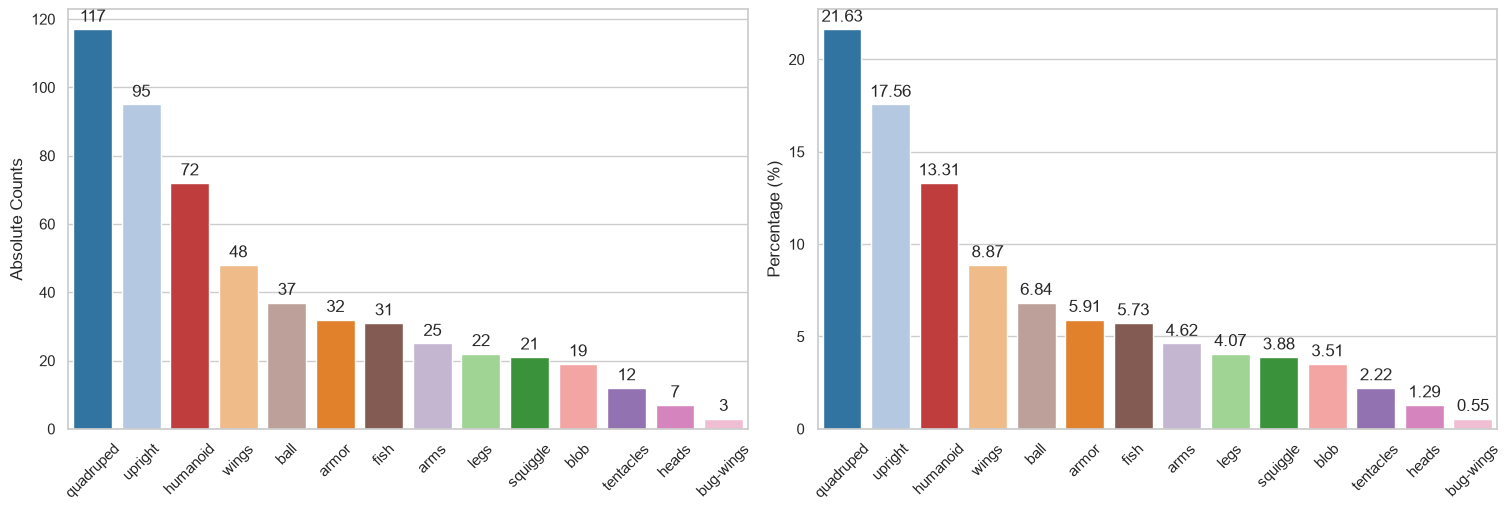

In [17]:
#Variable Shape
##Generar plots para shape
sns_plot_categorica_shape = plot_categorica_seaborn(df_pokemon, "shape", plot_size=(15,5), palette=shapes_palette)
##Guardar(png 300 dpi)
##bbox_inches='tight', evita que quede cortado al rotar a 45 grados etiquetas del eje x
sns_plot_categorica_shape.savefig("./results/sns_plot_categorica_shape.png", dpi=300,bbox_inches='tight')
##Mostrar
sns_plot_categorica_shape

b) Variable generation:

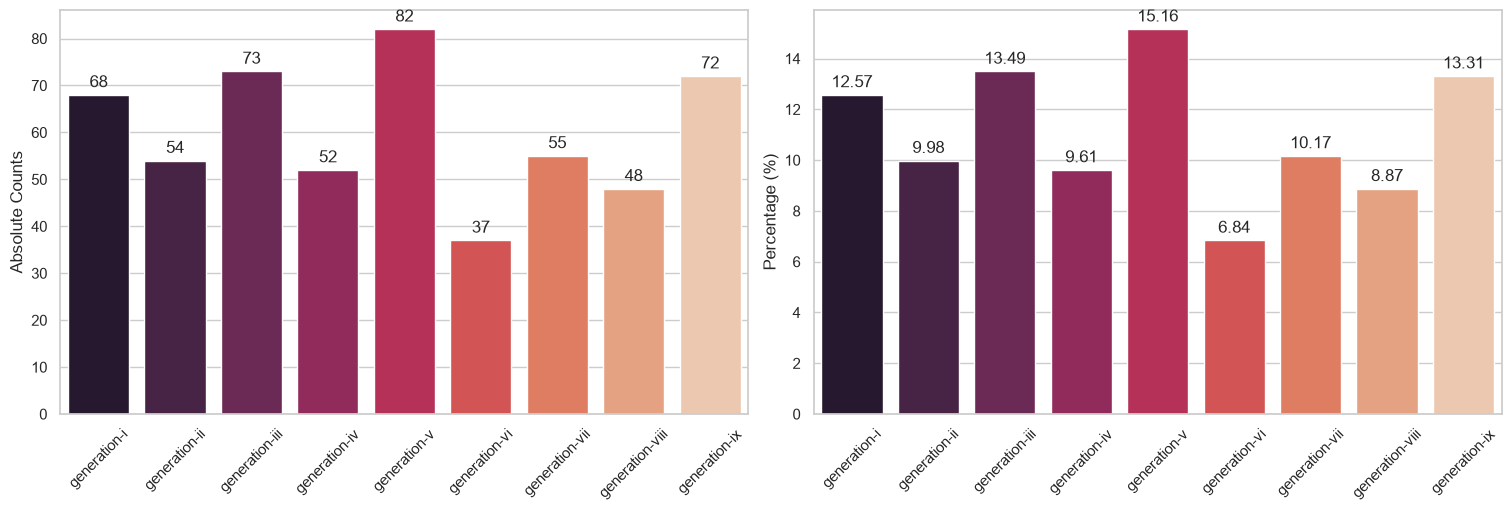

In [18]:
#Variable Generation
##Generar plots para generation
sns_plot_categorica_generation = plot_categorica_seaborn(df_pokemon, "generation", plot_size=(15,5), palette=generation_palette, original_order=True)
##Guardar(png 300 dpi)
sns_plot_categorica_generation.savefig("./results/sns_plot_categorica_generation.png", dpi=300,bbox_inches='tight')
##Mostrar
sns_plot_categorica_generation

c) Variable type_1:

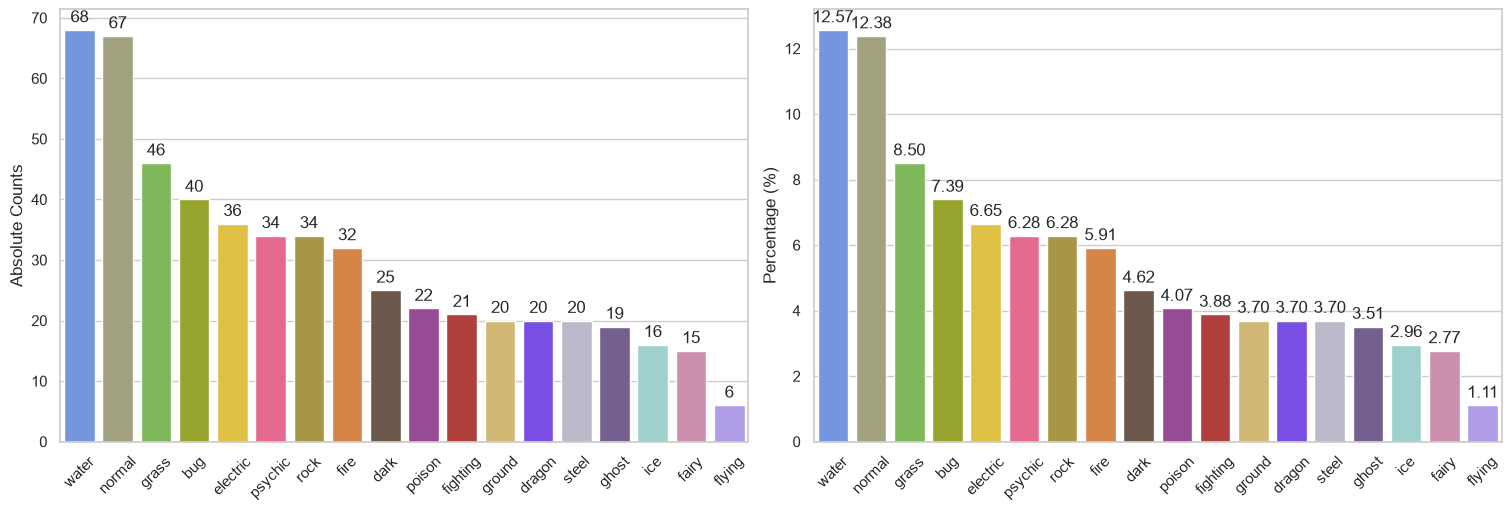

In [19]:
#Variable type_1
##Generar plots para generation
sns_plot_categorica_type1 = plot_categorica_seaborn(df_pokemon, "type_1", plot_size=(15,5), palette=types_palette)
##Guardar(png 300 dpi)
sns_plot_categorica_type1.savefig("./results/sns_plot_categorica_type1.png", dpi=300,bbox_inches='tight')
##Mostrar
sns_plot_categorica_type1

d) Variable type_2:

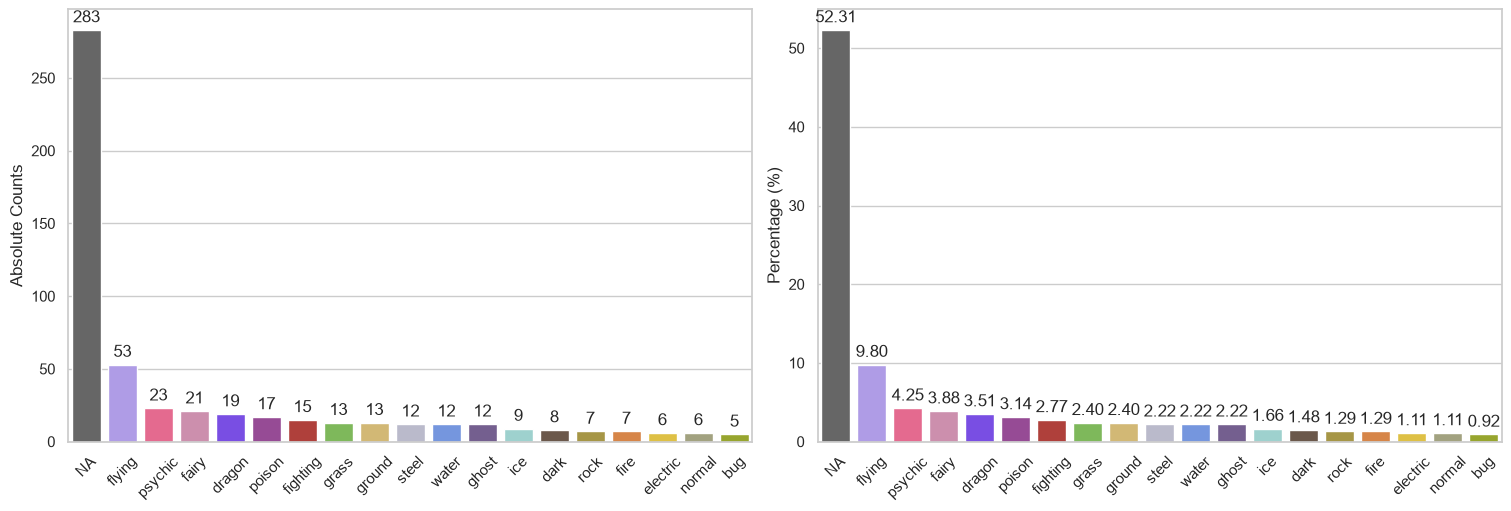

In [20]:
#Variable type_2
##Generar plots para generation
sns_plot_categorica_type2 = plot_categorica_seaborn(df_pokemon, "type_2", plot_size=(15,5), palette=types_palette)
##Guardar(png 300 dpi)
sns_plot_categorica_type2.savefig("./results/sns_plot_categorica_type2.png", dpi=300,bbox_inches='tight')
##Mostrar
sns_plot_categorica_type2

#### 6.1.2. Análisis general univariante (variables buleanas de types)

Vamos a aprobechar la tabla previa `df_bool_describe` y generar unos gráficos customizados para ver los types globales. Aunque claro, repitiendo conteos eso si, ya que un Pokémon puede tener más de un tipo teniendo en cuenta las variables `type_1` y `type_2`:

In [21]:
df_bool_describe

,count,unique,top,freq,complementary,percentage
type_water,541,2,False,461,80,14.787431
type_normal,541,2,False,468,73,13.49353
type_flying,541,2,False,482,59,10.90573
type_grass,541,2,False,482,59,10.90573
type_psychic,541,2,False,484,57,10.536044
type_bug,541,2,False,496,45,8.31793
type_electric,541,2,False,499,42,7.763401
type_rock,541,2,False,500,41,7.578558
type_dragon,541,2,False,502,39,7.208872
type_fire,541,2,False,502,39,7.208872


a) Primero con conteos absolutos:

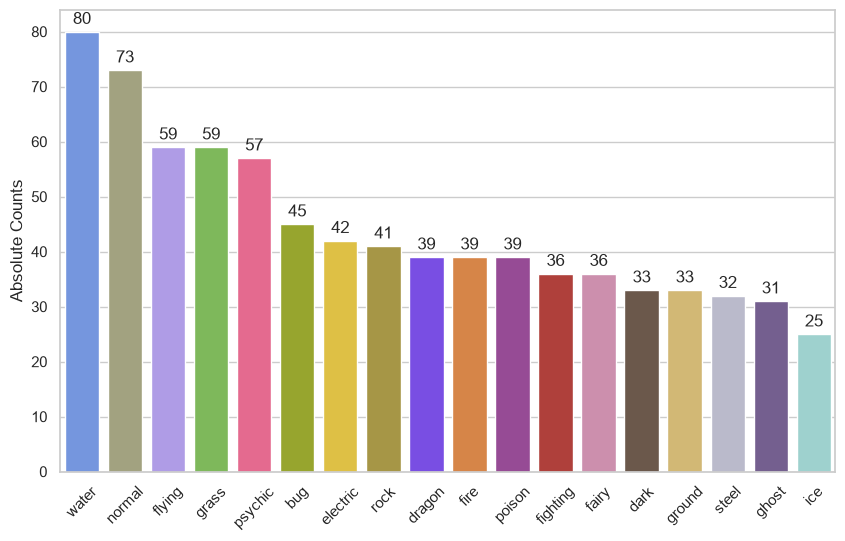

In [22]:
#Definimos tamaño
plt.figure(figsize=(10, 6))
#Vamos a reutilizar df_bool_describe (ya esta ordenada)
sns_plot_bool_types= sns.barplot(data=df_bool_describe, x=df_bool_describe.index.str.replace("type_",""), y='complementary',
                    hue=df_bool_describe.index.str.replace("type_",""),
                    palette=types_palette,
                    legend=False,
                    dodge=False)
#Ajustamos labelrotation
sns_plot_bool_types.tick_params(axis='x', labelrotation=45)
#Ajustamos etiquetas de los ejes
sns_plot_bool_types.set(ylabel="Absolute Counts",xlabel=None)
##Mostramos conteos
for contenedor0 in sns_plot_bool_types.containers: sns_plot_bool_types.bar_label(contenedor0,padding=3)
#Guardar plot
sns_plot_bool_types.get_figure().savefig("./results/sns_plot_bool_types_abs.png", dpi=300,bbox_inches='tight')
#Mostrar plot
sns_plot_bool_types;

b) Ahora con los porcentajes:

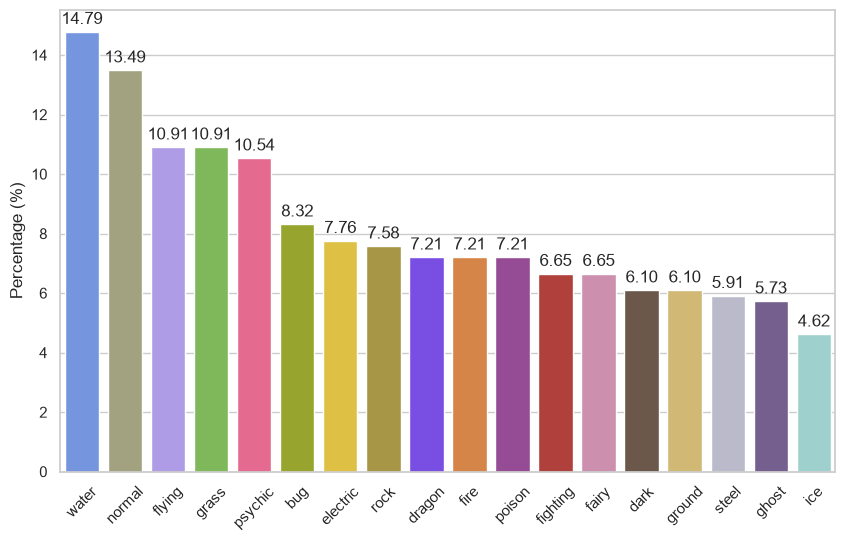

In [24]:
#Definimos tamaño
plt.figure(figsize=(10, 6))
#Vamos a reutilizar df_bool_describe (ya esta ordenada)
sns_plot_bool_types_perc= sns.barplot(data=df_bool_describe, x=df_bool_describe.index.str.replace("type_",""), y='percentage',
                    hue=df_bool_describe.index.str.replace("type_",""),
                    palette=types_palette,
                    legend=False,
                    dodge=False)
#Ajustamos labelrotation
sns_plot_bool_types_perc.tick_params(axis='x', labelrotation=45)
#Ajustamos etiquetas de los ejes
sns_plot_bool_types_perc.set(ylabel="Percentage (%)",xlabel=None)
##Mostramos conteos
for contenedor1 in sns_plot_bool_types_perc.containers: sns_plot_bool_types_perc.bar_label(contenedor1,padding=3,fmt="%.2f")
#Guardar plot
sns_plot_bool_types_perc.get_figure().savefig("./results/sns_plot_bool_types_perc.png", dpi=300,bbox_inches='tight')
#Mostrar plot
sns_plot_bool_types_perc;

#### 6.1.3. Análisis general univariante (variables numéricas)

a) Combinamos todos los barplots para las variables numéricas de interés en una figura para conseguir una visión general:

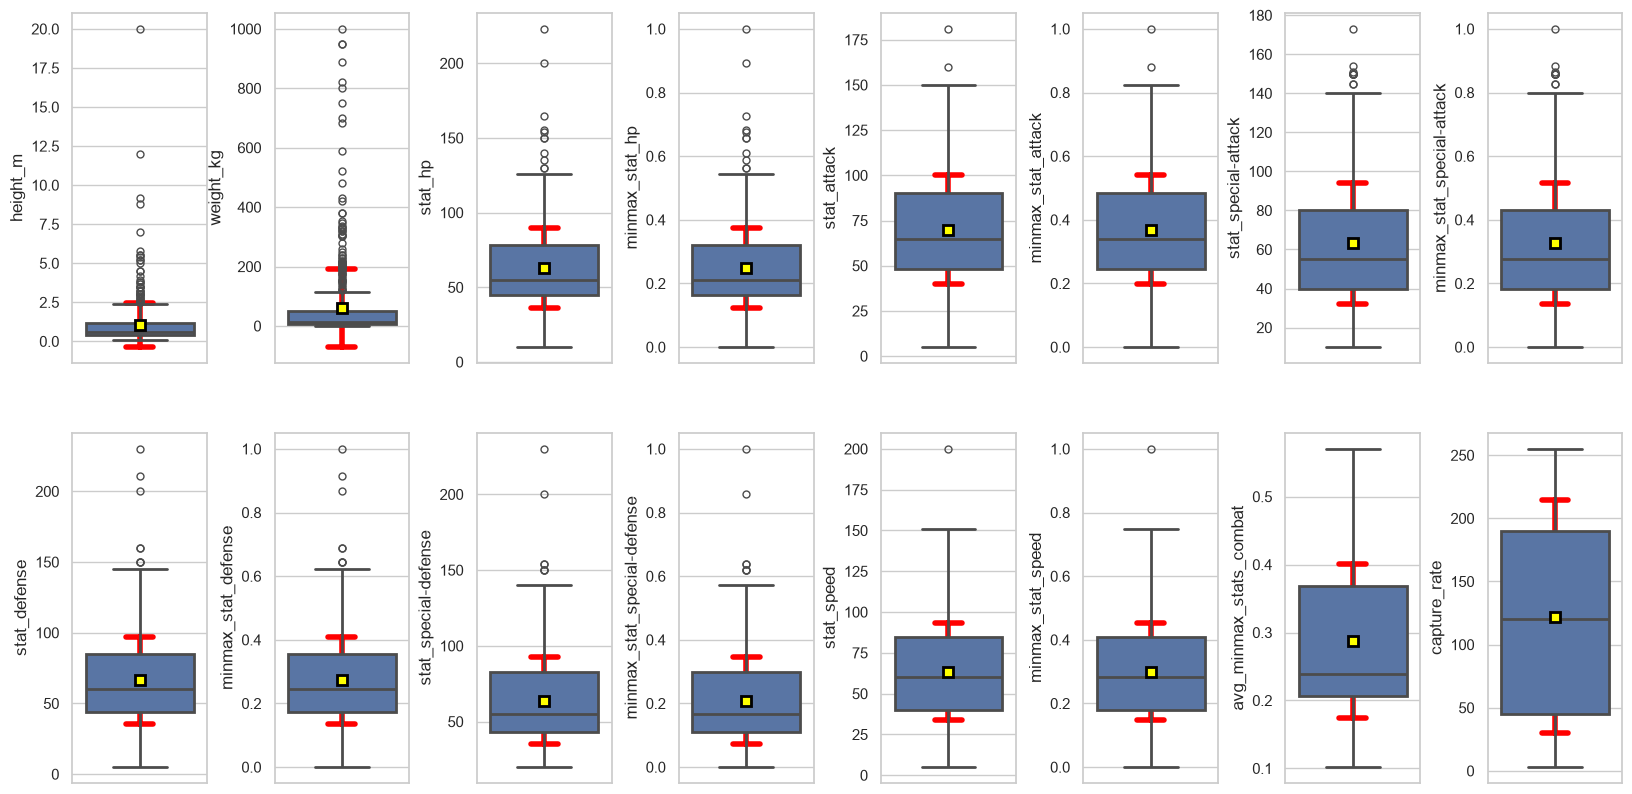

In [25]:
##Generar boxplots para numéricas de interés
sns_boxplots_numericas = plot_multiple_custom_boxplots(df_pokemon, columnas_numericas_ordered, n_cols=8,n_rows=2, plot_size=(20,10))
##Guardar(png 300 dpi)
sns_boxplots_numericas.savefig("./results/sns_boxplots_numericas.png", dpi=300,bbox_inches='tight')
##Mostrar
sns_boxplots_numericas

Tenemos unos boxplots que también representan la media (cuadrado amarillo) y la desviación estandar (barra error roja trasera).

b) Sacamos unos histogramas para ver distribuciones de estas variables numéricas:

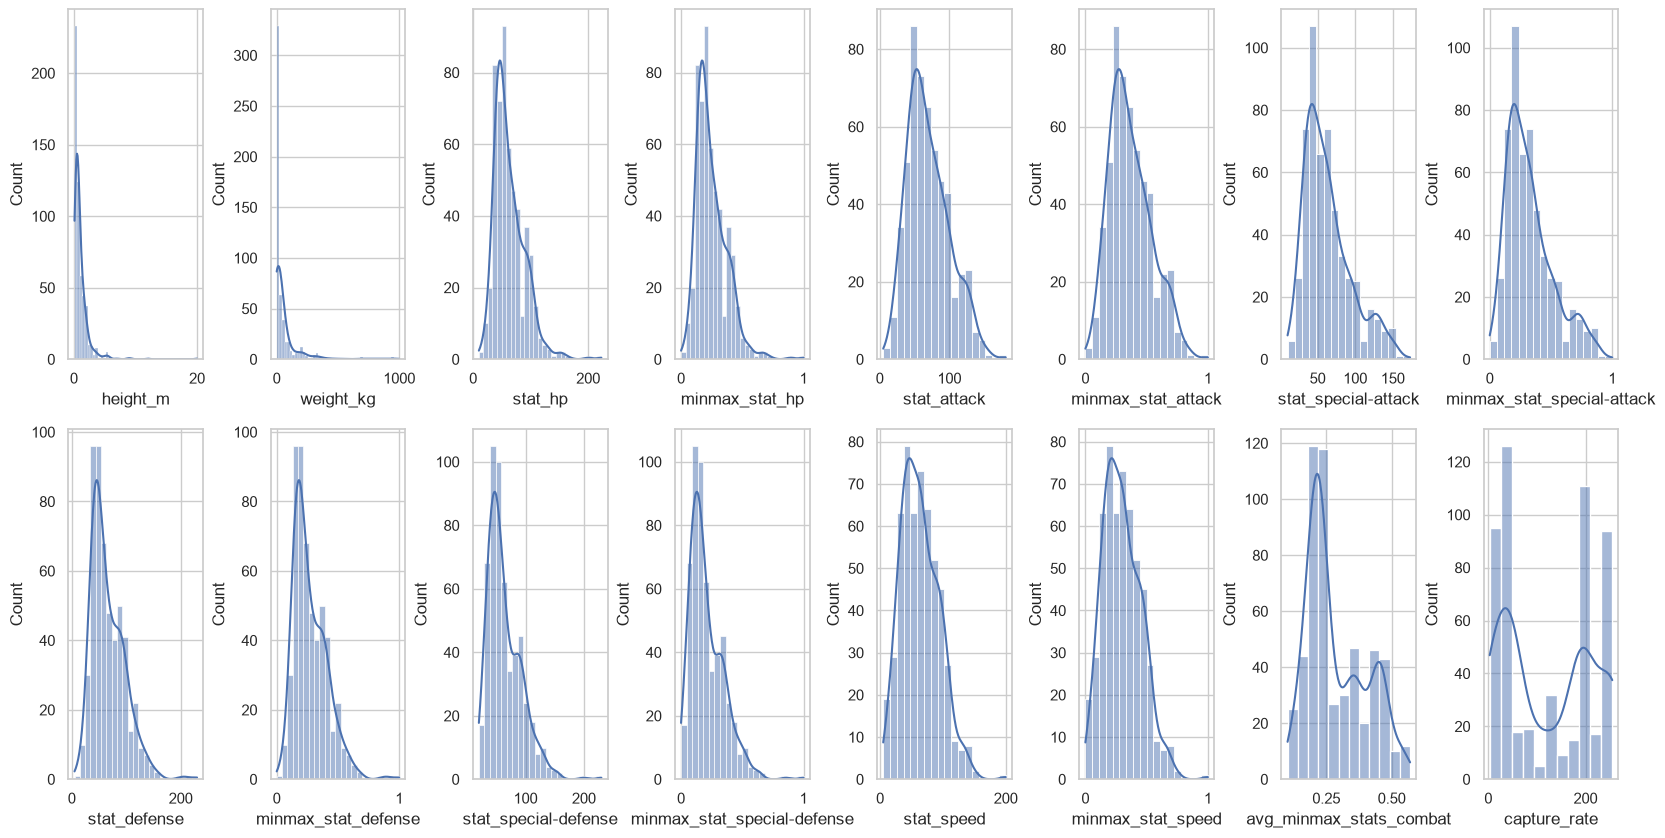

In [26]:
##Generar plots hists variables númericas
sns_hist_numericas = plot_multiple_hist(df_pokemon, columnas_numericas_ordered, n_cols=8,n_rows=2, plot_size=(20,10))
##Guardar(png 300 dpi)
sns_hist_numericas.savefig("./results/sns_hist_numericas.png", dpi=300,bbox_inches='tight')
##Mostrar
sns_hist_numericas

Vemos algunas cosas:
- `height_m` y `weight_kg` tienen formas parecidas concentrando la mayoría de conteos en un pico en el extremo izquierdo.
* Mientras que las variables relacionadas con `stats` de combate y sus `derivadas minmax` se caracterizan por un pico máximo centrado en la parte izquierda seguido de un segundo pico menor más a la derecha. Este segundo pico se hace especialmente patente en la variable `avg_minmax_stats_combate` derivada de las anteriores.
- Por otro lado, comprobamos que aplicar el escalado min-max ha cambiado la escala pero las distribuciones se mantienen estables cuando comparamos con sus respectivas variables stats.
* Finalmente, la variable `capture_rate` muestra dos picos máximos a cada extremo, con un pico menor en el centro. Lo que nos estaría indicando que la mayoría de Pokémon son o muy difíciles de capturar (pico izquierda) o muy fáciles de capturar (pico derecha), mientras que hay un cierto grupo de Pokémon con una dificultad intermedia de captura (pico central).

c) Ahora vamos a centrarnos en los min-max stats y generar un radar plot con la librería sypderplot (https://pypi.org/project/spiderplot/): 

In [8]:
#Calculamos las medias globales para los stats minmax y avg_minmax_stats_combat
minmax_global_means = df_pokemon[columnas_minmax].mean().reset_index()
minmax_global_means["category"] = "Global"
minmax_global_means.rename(columns={0:"value", "index":"stat"}, inplace=True)
minmax_global_means

,stat,value,category
0,avg_minmax_stats_combat,0.287453,Global
1,minmax_stat_hp,0.249173,Global
2,minmax_stat_attack,0.368404,Global
3,minmax_stat_special-attack,0.325822,Global
4,minmax_stat_defense,0.272992,Global
5,minmax_stat_special-defense,0.208652,Global
6,minmax_stat_speed,0.299673,Global


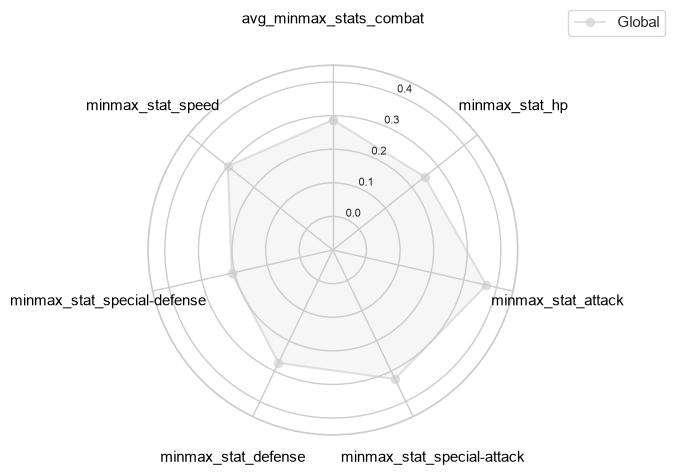

In [28]:
#Usaremos la libreria spyderplot(sp)
##Set style
sns.set_style("whitegrid")
#Inicializamos plot
radar_global = sp.spiderplot(x=minmax_global_means["stat"], y="value", hue="category", style="category",
                   data=minmax_global_means, dashes=False, palette=radar_types_palette) #Me habría servido cualquiera 3 radar palettes
#Definimos los limites de y="value"
radar_global.set_rlim([-0.1,0.45])
#Movemos las etiquetas stat fuera del gráfico y cambiamos color a negro
radar_global.tick_params(axis="x", pad=20, colors="black")
#Movemos las etiqyetas de y=value a grado 22.5
radar_global.set_rlabel_position(22.5)
#Movemos ambos grupos etiquetas al frente
radar_global.yaxis.set_zorder(10)
radar_global.xaxis.set_zorder(11)
#Añadimos la leyenda
radar_global.legend(loc="upper right",
           bbox_to_anchor=(1.4, 1.15),
           borderaxespad=0.)
#Guardar plot
radar_global.get_figure().savefig("./results/sp_radarplot_minmax_stats_globalmean.png", dpi=300,bbox_inches='tight')
#Mostrar plot
radar_global;

### 6.2. Análisis general multivariante

#### 6.2.1. Análisis entre variables categóricas

##### 6.2.1.1. Generation como referencia

a) Generation vs shape:

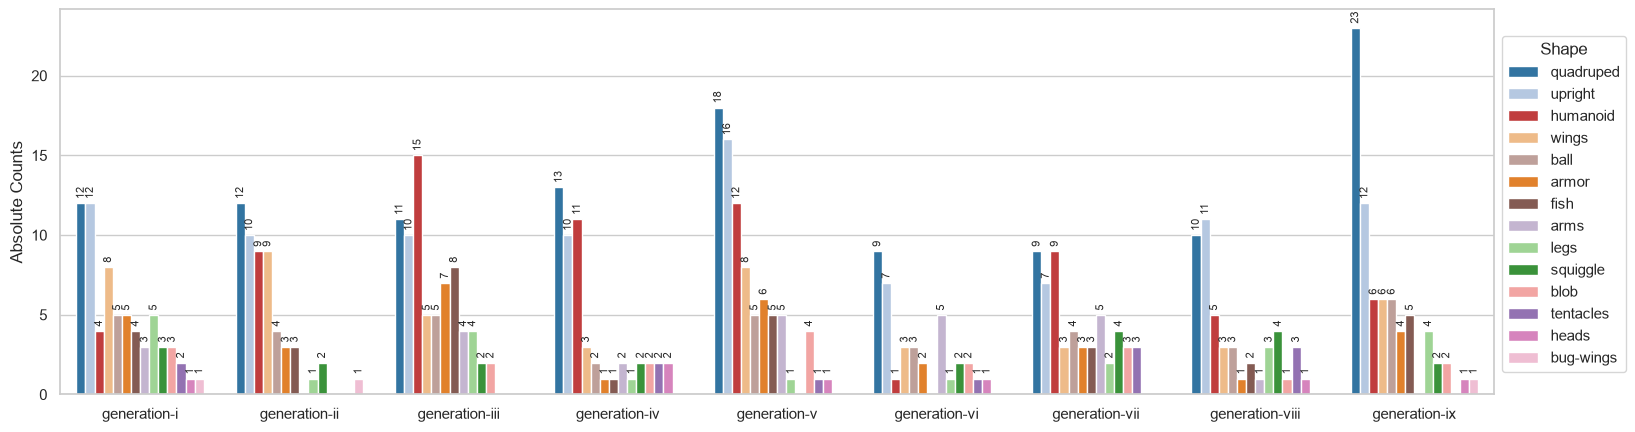

In [29]:
#Definimos tamaño
plt.figure(figsize=(18.5, 5))
#Generamos plot inicial
sns_barplot_generation_shape = sns.countplot(data=df_pokemon, x="generation", hue="shape", palette=shapes_palette, hue_order=order_shape_descent)
#Ajustamos labelrotation de eje x
#sns_barplot_generation_shape.tick_params(axis='x', labelrotation=45)
#Ajustamos etiquetas de los ejes
sns_barplot_generation_shape.set(ylabel="Absolute Counts",xlabel=None)
##Mostramos conteos en las barras (rotando 90 grados y reduciendo fontsize)
for contenedor1 in sns_barplot_generation_shape.containers: sns_barplot_generation_shape.bar_label(contenedor1,padding=3, rotation=90, fontsize=8)
##Ajustamos leyenda(añadimos title, posicionamos)
sns_barplot_generation_shape.legend(title="Shape",bbox_to_anchor=(1, 0.95), loc="upper left")
#Guardar plot
sns_barplot_generation_shape.get_figure().savefig("./results/sns_barplot_generation_shape.png", dpi=300,bbox_inches='tight')
#Mostrar plot
sns_barplot_generation_shape;

b) Generation vs type_1: 

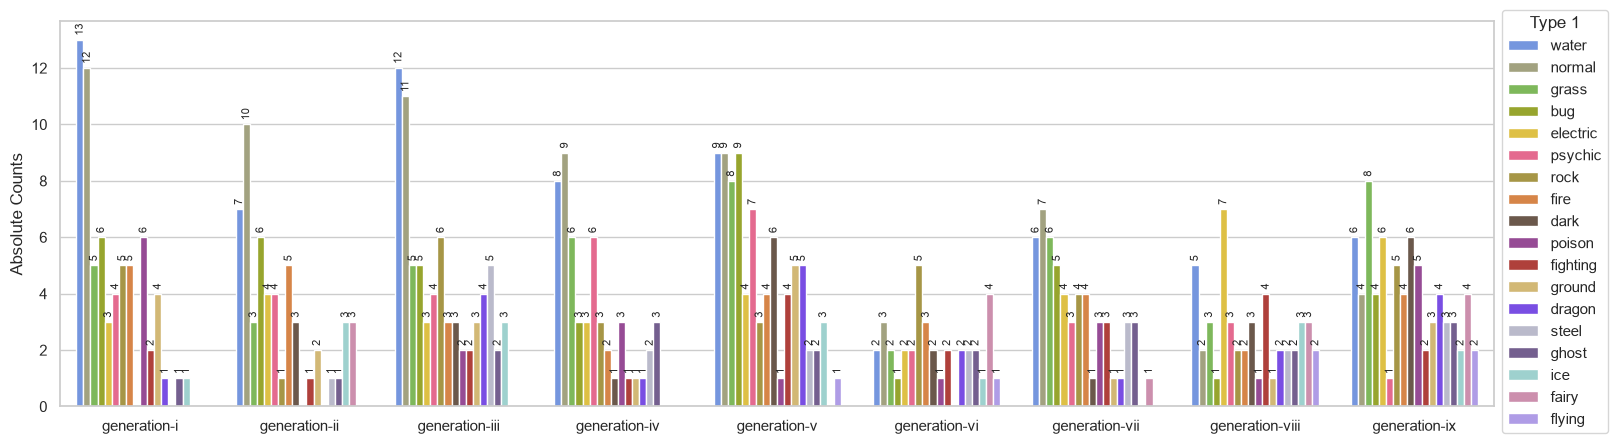

In [30]:
#Definimos tamaño
plt.figure(figsize=(18.5, 5))
#Generamos plot inicial
sns_barplot_generation_type1 = sns.countplot(data=df_pokemon, x="generation", hue="type_1", palette=types_palette, hue_order=order_type1_descent)
#Ajustamos labelrotation de eje x
#sns_barplot_generation_type1.tick_params(axis='x', labelrotation=45)
#Ajustamos etiquetas de los ejes
sns_barplot_generation_type1.set(ylabel="Absolute Counts",xlabel=None)
##Mostramos conteos en las barras (rotando 90 grados y reduciendo fontsize)
for contenedor1 in sns_barplot_generation_type1.containers: sns_barplot_generation_type1.bar_label(contenedor1,padding=3, rotation=90, fontsize=8)
##Ajustamos leyenda(añadimos title, posicionamos)
sns_barplot_generation_type1.legend(title="Type 1",bbox_to_anchor=(1, 1.05), loc="upper left")
#Guardar plot
sns_barplot_generation_type1.get_figure().savefig("./results/sns_barplot_generation_type1.png", dpi=300,bbox_inches='tight')
#Mostrar plot
sns_barplot_generation_type1;

Vemos que en realidad el Type1 más frecuente en generaciones sería el tipo normal (4 generaciones).

c) Generation vs type_2:

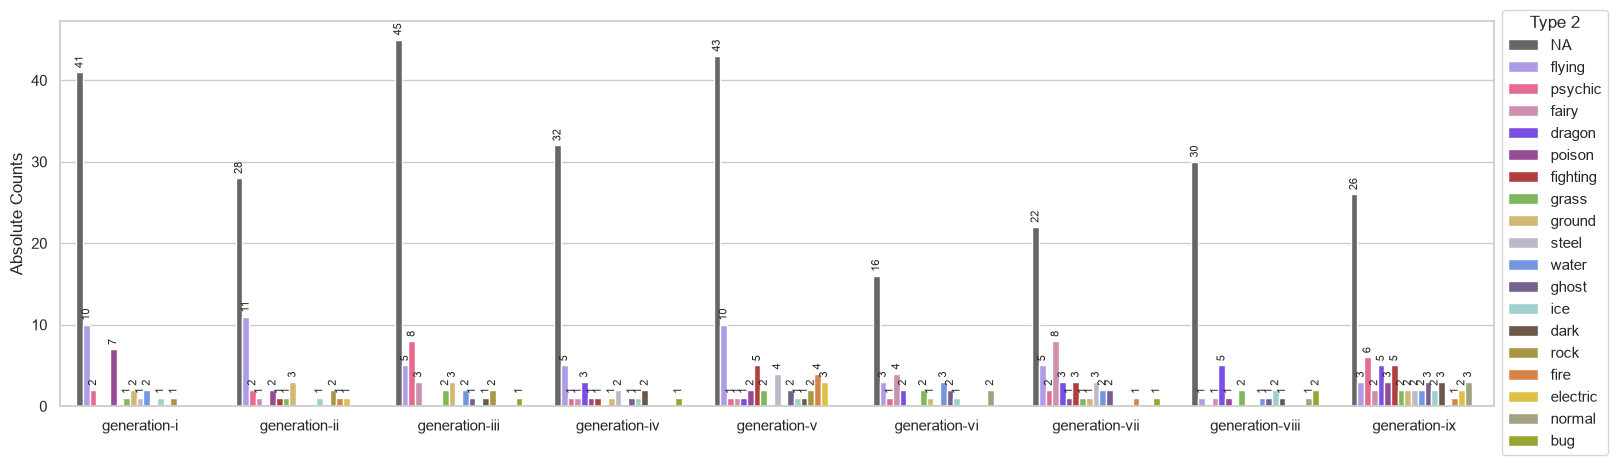

In [31]:
#Definimos tamaño
plt.figure(figsize=(18.5, 5))
#Generamos plot inicial
sns_barplot_generation_type2 = sns.countplot(data=df_pokemon, x="generation", hue=df_pokemon["type_2"].fillna("NA"), palette=types_palette, hue_order=order_type2_descent)
#Ajustamos labelrotation de eje x
#sns_barplot_generation_type2.tick_params(axis='x', labelrotation=45)
#Ajustamos etiquetas de los ejes
sns_barplot_generation_type2.set(ylabel="Absolute Counts",xlabel=None)
##Mostramos conteos en las barras (rotando 90 grados y reduciendo fontsize)
for contenedor1 in sns_barplot_generation_type2.containers: sns_barplot_generation_type2.bar_label(contenedor1,padding=3, rotation=90, fontsize=8)
##Ajustamos leyenda(añadimos title, posicionamos)
sns_barplot_generation_type2.legend(title="Type 2",bbox_to_anchor=(1, 1.05), loc="upper left")
#Guardar plot
sns_barplot_generation_type2.get_figure().savefig("./results/sns_barplot_generation_type2.png", dpi=300,bbox_inches='tight')
#Mostrar plot
sns_barplot_generation_type2;

d) generation vs bool types:

In [34]:
#Generamos la relacion de conteos entre generation vs types apartir de la tabla conteos previa
df_counts_generation_types_melt = df_counts_generation_types.reset_index().melt(id_vars=["generation"], var_name="types", value_name="counts")
df_counts_generation_types_melt["types"]=df_counts_generation_types_melt.types.str.replace("type_","") #sustituimos el prefijo, para que coincida con la palette
df_counts_generation_types_melt_filtered = df_counts_generation_types_melt[df_counts_generation_types_melt["counts"]>0] # Filtramos ceros

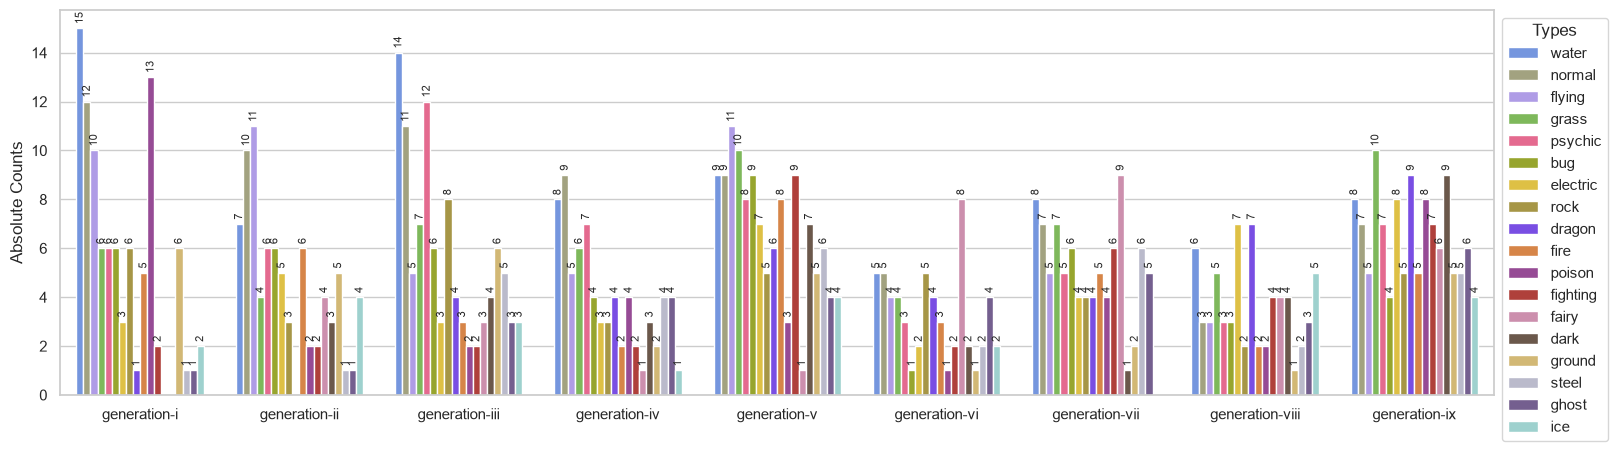

In [35]:
#Definimos tamaño
plt.figure(figsize=(18.5, 5))
#Generamos plot inicial
sns_barplot_generation_types = sns.barplot(data=df_counts_generation_types_melt_filtered, x="generation", y="counts", order=generation_order,
                                           hue="types", palette=types_palette, hue_order=order_types_descent)
#Ajustamos labelrotation de eje x
#sns_barplot_generation_types.tick_params(axis='x', labelrotation=45)
#Ajustamos etiquetas de los ejes
sns_barplot_generation_types.set(ylabel="Absolute Counts",xlabel=None)
##Mostramos conteos en las barras (rotando 90 grados y reduciendo fontsize)
for contenedor in sns_barplot_generation_types.containers: sns_barplot_generation_types.bar_label(contenedor,padding=3, rotation=90, fontsize=8)
##Ajustamos leyenda(añadimos title, posicionamos)
sns_barplot_generation_types.legend(title="Types",bbox_to_anchor=(1, 1), loc="upper left")
#Guardar plot
sns_barplot_generation_types.get_figure().savefig("./results/sns_barplot_generation_types.png", dpi=300,bbox_inches='tight')
#Mostrar plot
sns_barplot_generation_types;

##### 6.2.1.2. Types como referencia

a) Types vs Generation:

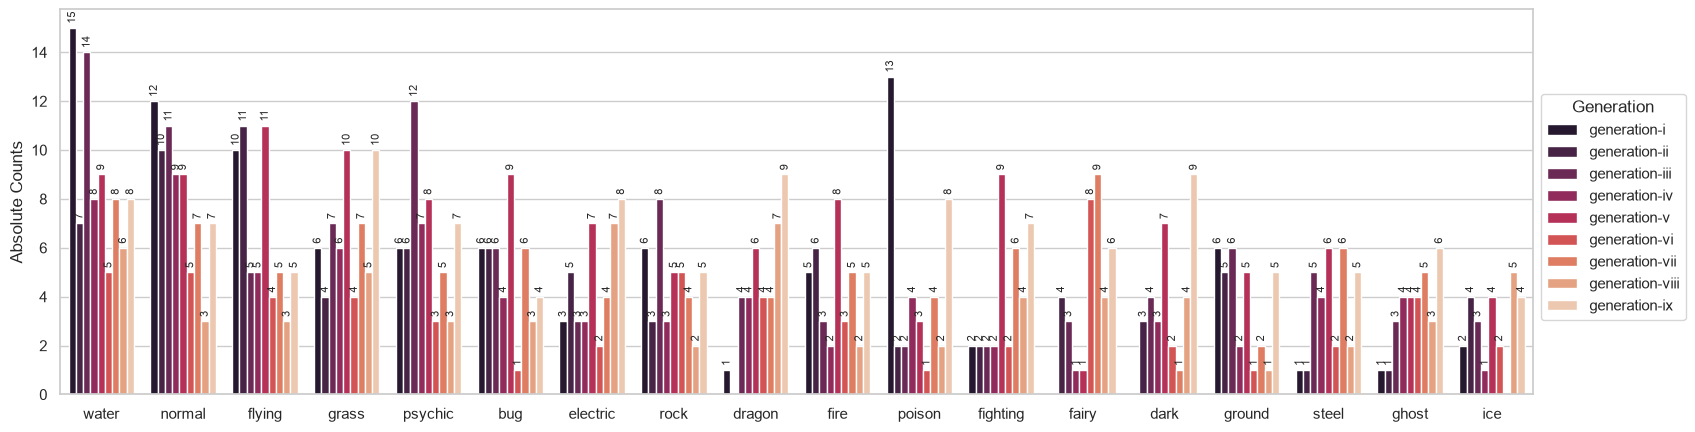

In [36]:
#Definimos tamaño
plt.figure(figsize=(19, 5))
#Generamos plot inicial
sns_barplot_types_generation = sns.barplot(data=df_counts_generation_types_melt_filtered, x="types", y="counts", order=order_types_descent,
                                           hue="generation", palette=generation_palette, hue_order=generation_order)
#Ajustamos labelrotation de eje x
#sns_barplot_generation_types.tick_params(axis='x', labelrotation=45)
#Ajustamos etiquetas de los ejes
sns_barplot_types_generation.set(ylabel="Absolute Counts",xlabel=None)
##Mostramos conteos en las barras (rotando 90 grados y reduciendo fontsize)
for contenedor in sns_barplot_types_generation.containers: sns_barplot_types_generation.bar_label(contenedor,padding=3, rotation=90, fontsize=8)
##Ajustamos leyenda(añadimos title, posicionamos)
sns_barplot_types_generation.legend(title="Generation",bbox_to_anchor=(1, 0.8), loc="upper left")
#Guardar plot
sns_barplot_types_generation.get_figure().savefig("./results/sns_barplot_types_generation.png", dpi=300,bbox_inches='tight')
#Mostrar plot
sns_barplot_types_generation;

b) Types vs shapes:

In [38]:
#Generamos la relacion de conteos entre generation vs types apartir de la tabla conteos previa
df_counts_shape_types_melt = df_counts_shape_types.reset_index().melt(id_vars=["shape"], var_name="types", value_name="counts")
df_counts_shape_types_melt["types"]=df_counts_shape_types_melt.types.str.replace("type_","") #sustituimos el prefijo, para que coincida con la palette
df_counts_shape_types_melt_filtered = df_counts_shape_types_melt[df_counts_shape_types_melt["counts"]>0] # Filtramos ceros

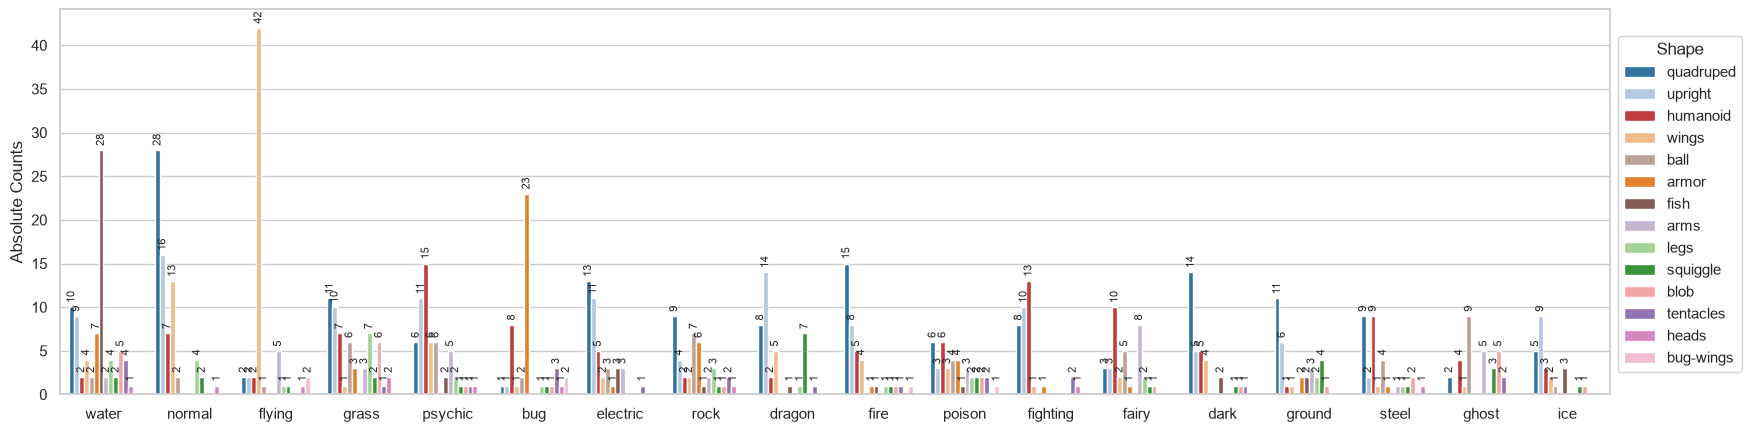

In [39]:
#Definimos tamaño
plt.figure(figsize=(20, 5))
#Generamos plot inicial
sns_barplot_types_shape = sns.barplot(data=df_counts_shape_types_melt_filtered, x="types", y="counts", order=order_types_descent,
                                           hue="shape", palette=shapes_palette, hue_order=order_shape_descent)
#Ajustamos labelrotation de eje x
#sns_barplot_generation_types.tick_params(axis='x', labelrotation=45)
#Ajustamos etiquetas de los ejes
sns_barplot_types_shape.set(ylabel="Absolute Counts",xlabel=None)
##Mostramos conteos en las barras (rotando 90 grados y reduciendo fontsize)
for contenedor in sns_barplot_types_shape.containers: sns_barplot_types_shape.bar_label(contenedor,padding=3, rotation=90, fontsize=8)
##Ajustamos leyenda(añadimos title, posicionamos)
sns_barplot_types_shape.legend(title="Shape",bbox_to_anchor=(1, 0.95), loc="upper left")
#Guardar plot
sns_barplot_types_shape.get_figure().savefig("./results/sns_barplot_types_shape.png", dpi=300,bbox_inches='tight')
#Mostrar plot
sns_barplot_types_shape;

##### 6.2.1.3. Shape como referencia

a) Shape vs Generation:

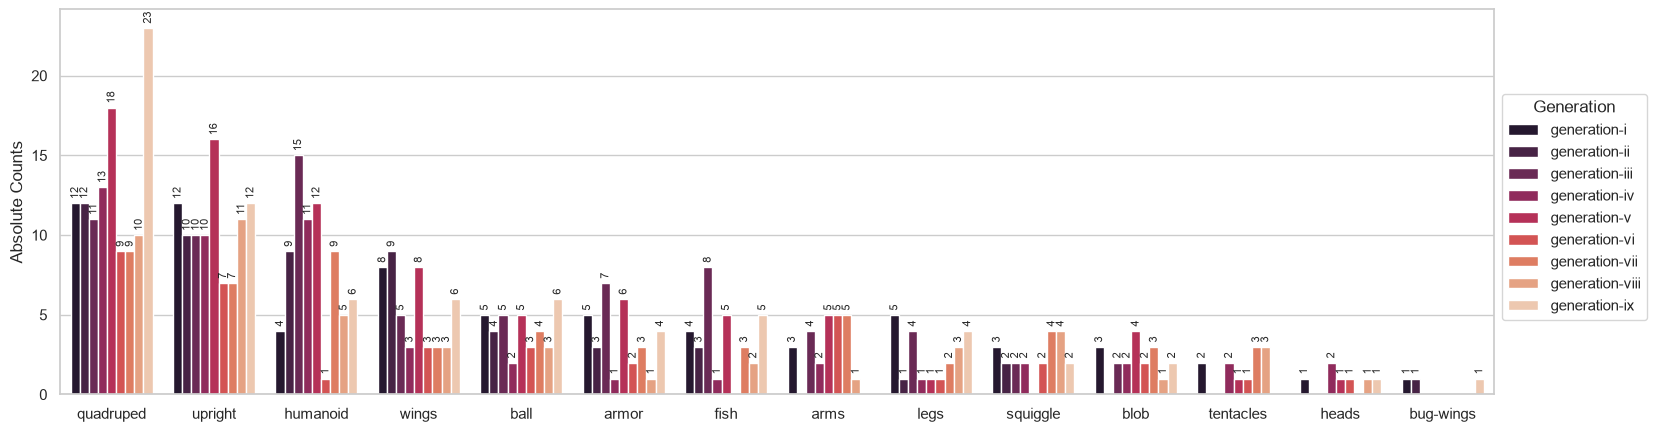

In [40]:
#Definimos tamaño
plt.figure(figsize=(18.5, 5))
#Generamos plot inicial
sns_barplot_shape_generation = sns.countplot(data=df_pokemon, x="shape", hue="generation", palette=generation_palette, hue_order=generation_order, order=order_shape_descent)
#Ajustamos labelrotation de eje x
#sns_barplot_shape_generation.tick_params(axis='x', labelrotation=45)
#Ajustamos etiquetas de los ejes
sns_barplot_shape_generation.set(ylabel="Absolute Counts",xlabel=None)
##Mostramos conteos en las barras (rotando 90 grados y reduciendo fontsize)
for contenedor1 in sns_barplot_shape_generation.containers: sns_barplot_shape_generation.bar_label(contenedor1,padding=3, rotation=90, fontsize=8)
##Ajustamos leyenda(añadimos title, posicionamos)
sns_barplot_shape_generation.legend(title="Generation",bbox_to_anchor=(1, 0.8), loc="upper left")
#Guardar plot
sns_barplot_shape_generation.get_figure().savefig("./results/sns_barplot_shape_generation.png", dpi=300,bbox_inches='tight')
#Mostrar plot
sns_barplot_shape_generation;

b) Shape vs types:

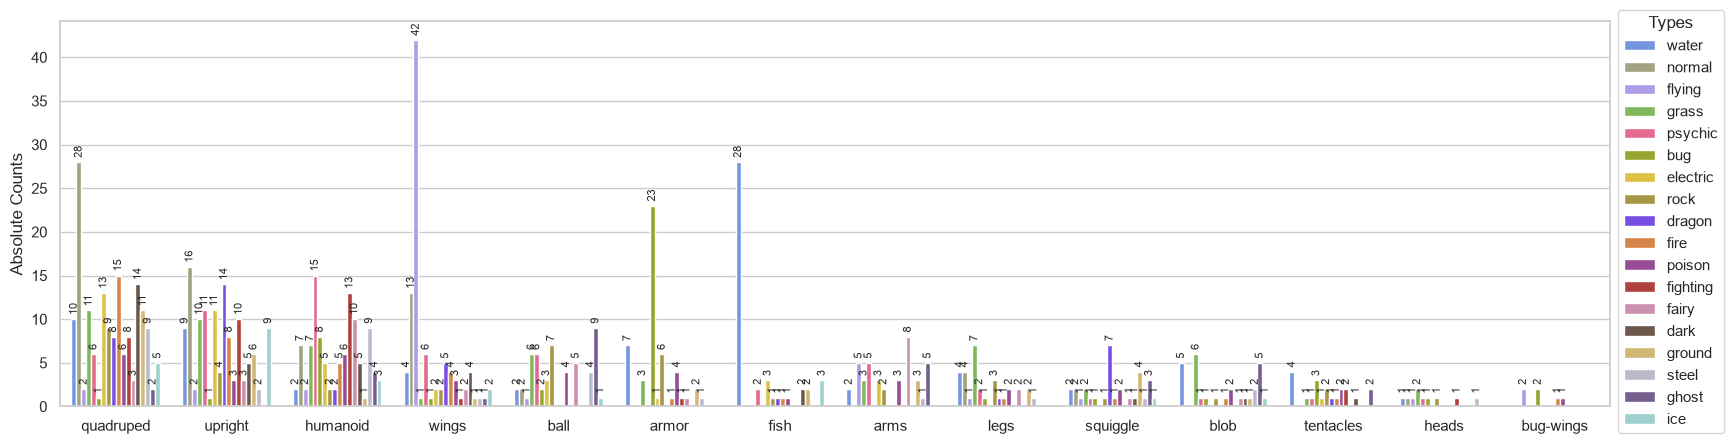

In [41]:
#Definimos tamaño
plt.figure(figsize=(20, 5))
#Generamos plot inicial
sns_barplot_shape_types = sns.barplot(data=df_counts_shape_types_melt_filtered, x="shape", y="counts", order=order_shape_descent,
                                           hue="types", palette=types_palette, hue_order=order_types_descent)
#Ajustamos labelrotation de eje x
#sns_barplot_generation_types.tick_params(axis='x', labelrotation=45)
#Ajustamos etiquetas de los ejes
sns_barplot_shape_types.set(ylabel="Absolute Counts",xlabel=None)
##Mostramos conteos en las barras (rotando 90 grados y reduciendo fontsize)
for contenedor in sns_barplot_shape_types.containers: sns_barplot_shape_types.bar_label(contenedor,padding=3, rotation=90, fontsize=8)
##Ajustamos leyenda(añadimos title, posicionamos)
sns_barplot_shape_types.legend(title="Types",bbox_to_anchor=(1, 1.05), loc="upper left")
#Guardar plot
sns_barplot_shape_types.get_figure().savefig("./results/sns_barplot_shape_types.png", dpi=300,bbox_inches='tight')
#Mostrar plot
sns_barplot_shape_types;

c) Shapes vs type_1:

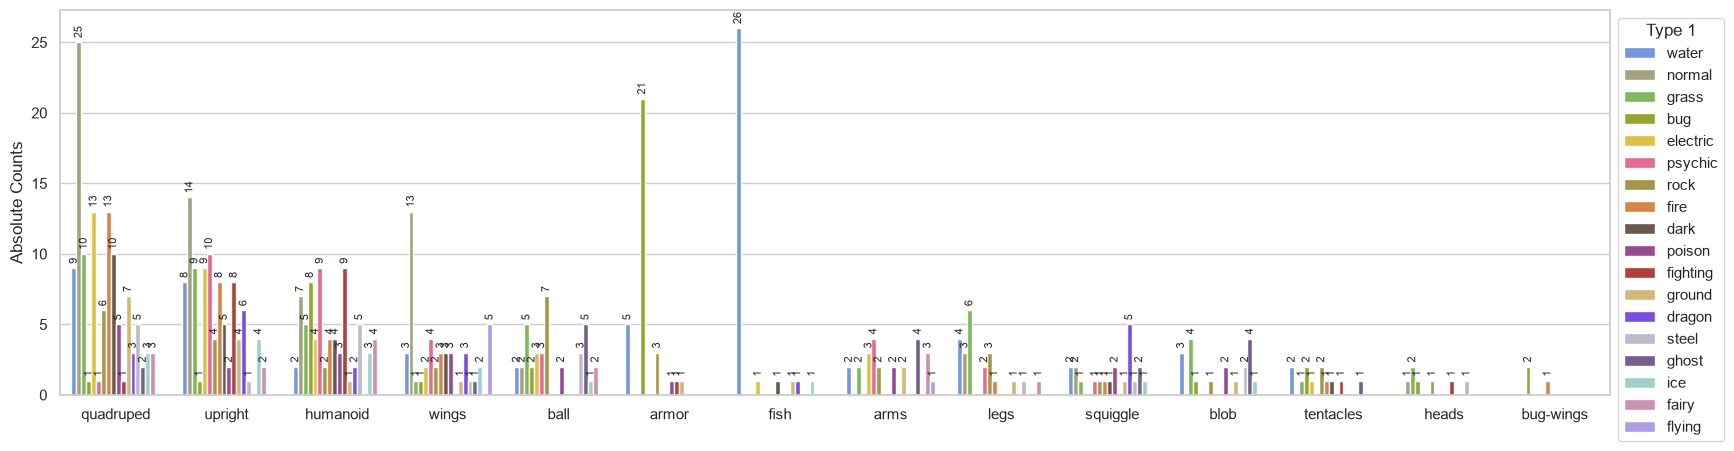

In [42]:
#Definimos tamaño
plt.figure(figsize=(20, 5))
#Generamos plot inicial
sns_barplot_shape_type1 = sns.countplot(data=df_pokemon, x="shape", hue="type_1", palette=types_palette, hue_order=order_type1_descent, order=order_shape_descent)
#Ajustamos labelrotation de eje x
#sns_barplot_shape_type1.tick_params(axis='x', labelrotation=45)
#Ajustamos etiquetas de los ejes
sns_barplot_shape_type1.set(ylabel="Absolute Counts",xlabel=None)
##Mostramos conteos en las barras (rotando 90 grados y reduciendo fontsize)
for contenedor1 in sns_barplot_shape_type1.containers: sns_barplot_shape_type1.bar_label(contenedor1,padding=3, rotation=90, fontsize=8)
##Ajustamos leyenda(añadimos title, posicionamos)
sns_barplot_shape_type1.legend(title="Type 1",bbox_to_anchor=(1, 1), loc="upper left")
#Guardar plot
sns_barplot_shape_type1.get_figure().savefig("./results/sns_barplot_shape_type1.png", dpi=300,bbox_inches='tight')
#Mostrar plot
sns_barplot_shape_type1;

d) Shapes vs type_2:

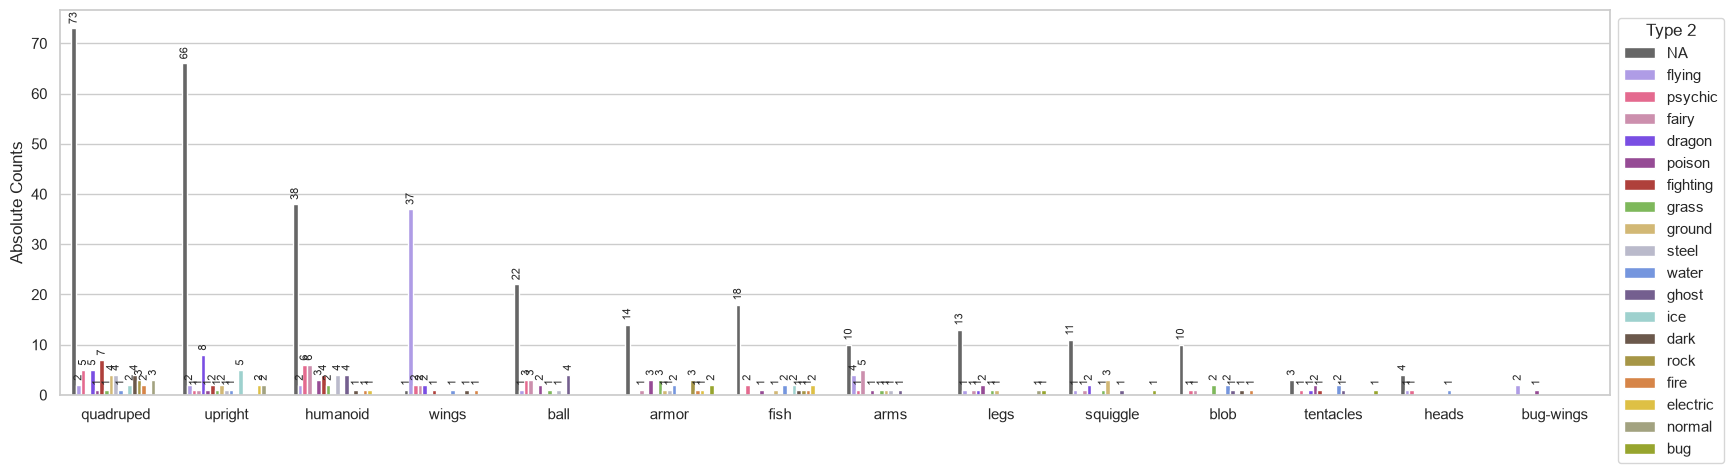

In [43]:
#Definimos tamaño
plt.figure(figsize=(20, 5))
#Generamos plot inicial
sns_barplot_shape_type2 = sns.countplot(data=df_pokemon, x="shape", hue=df_pokemon["type_2"].fillna("NA"), palette=types_palette, hue_order=order_type2_descent, order=order_shape_descent)
#Ajustamos labelrotation de eje x
#sns_barplot_shape_type2.tick_params(axis='x', labelrotation=45)
#Ajustamos etiquetas de los ejes
sns_barplot_shape_type2.set(ylabel="Absolute Counts",xlabel=None)
##Mostramos conteos en las barras (rotando 90 grados y reduciendo fontsize)
for contenedor1 in sns_barplot_shape_type2.containers: sns_barplot_shape_type2.bar_label(contenedor1,padding=3, rotation=90, fontsize=8)
##Ajustamos leyenda(añadimos title, posicionamos)
sns_barplot_shape_type2.legend(title="Type 2",bbox_to_anchor=(1, 1), loc="upper left")
#Guardar plot
sns_barplot_shape_type2.get_figure().savefig("./results/sns_barplot_shape_type2.png", dpi=300,bbox_inches='tight')
#Mostrar plot
sns_barplot_shape_type2;

##### 6.2.1.4. Tests Chi2

Hagamos unas pruebas para comparar si hay diferencias significativas entre grupos categóricos. Para simplificar, y para que se cumpla que los grupos no compartan observaciones usaremos type_1, en vez de types. Dejamos de lado también type_2, por los NAs. Esto no pretende ser un análisis exhaustivo, sino un caso práctico.

a) Generation vs Type_1:

In [44]:
#Generamos la tabla de contingencia
df_counts_generation_type1 = pd.crosstab(df_pokemon['generation'], df_pokemon['type_1'])
df_counts_generation_type1

type_1,bug,dark,dragon,electric,fairy,fighting,fire,flying,ghost,grass,ground,ice,normal,poison,psychic,rock,steel,water
generation,,,,,,,,,,,,,,,,,,
generation-i,6,0,1,3,0,2,5,0,1,5,4,1,12,6,4,5,0,13
generation-ii,6,3,0,4,3,1,5,0,1,3,2,3,10,0,4,1,1,7
generation-iii,5,3,4,3,0,2,3,0,2,5,3,3,11,2,4,6,5,12
generation-iv,3,1,1,3,0,1,2,0,3,6,1,0,9,3,6,3,2,8
generation-ix,4,6,4,6,4,2,4,2,3,8,3,2,4,5,1,5,3,6
generation-v,9,6,5,4,0,4,4,1,2,8,5,3,9,1,7,3,2,9
generation-vi,1,2,2,2,4,2,3,1,2,2,0,1,3,1,2,5,2,2
generation-vii,5,1,1,4,1,3,4,0,3,6,1,0,7,3,3,4,3,6
generation-viii,1,3,2,7,3,4,2,2,2,3,1,3,2,1,3,2,2,5


In [45]:
#Test con df_counts_generation_type1
chi2_generation_type1 = chi2_contingency_results(df_counts_generation_type1)

Resultados:
- Valor Chi-Cuadrado: 134.0150911220815
- P-Value: 0.5320631844806558
- Grados de Libertad: 136
Condiciones de aplicabilidad:
- ¿Hay alguna celda esperada < 1?: Sí
- Porcentaje de celdas esperadas >= 5: 16.67%
ADVERTENCIA: No se cumplen las condiciones de aplicabilidad.
El p-valor obtenido mediante Chi-cuadrado puede no ser confiable.


Vemos que el test no sería significativo con un alfa=0.05, pero no se cumplen las condiciones de aplicabilidad. Así que vamos a hacer una prueba agrupando las generaciones de 3 en 3:

In [46]:
# Agrupamos las 9 generaciones en 3 Eras temporales
dicc_eras = {'generation-i':'Era1', 'generation-ii':'Era1', 'generation-iii':'Era1', 
             'generation-iv':'Era2','generation-v':'Era2', 'generation-vi':'Era2', 
             'generation-vii':'Era3', 'generation-viii':'Era3','generation-ix':'Era3'
             }
# Hacemos la agrupación
df_counts_eras_type1 = df_counts_generation_type1.groupby(by=dicc_eras).sum()
df_counts_eras_type1

type_1,bug,dark,dragon,electric,fairy,fighting,fire,flying,ghost,grass,ground,ice,normal,poison,psychic,rock,steel,water
generation,,,,,,,,,,,,,,,,,,
Era1,17,6,5,10,3,5,13,0,4,13,9,7,33,8,12,12,6,32
Era2,13,9,8,9,4,7,9,2,7,16,6,4,21,5,15,11,6,19
Era3,10,10,7,17,8,9,10,4,8,17,5,5,13,9,7,11,8,17


In [47]:
chi2_eras_type1 = chi2_contingency_results(df_counts_eras_type1)

Resultados:
- Valor Chi-Cuadrado: 36.69927940154809
- P-Value: 0.3447656353855162
- Grados de Libertad: 34
Condiciones de aplicabilidad:
- ¿Hay alguna celda esperada < 1?: No
- Porcentaje de celdas esperadas >= 5: 90.74%
¡ÉXITO! Se cumplen las condiciones de aplicabilidad.


En este caso, después de agrupar si que se cumplen las condiciones de aplicabilidad y vemos que al comparar las generaciones de 3 en 3, siguen sin haber diferencias significativas al comparar eras con los tipos principales (type_1) al usar un alfa=0.05.

b) Generation vs Shapes:

In [48]:
#Generamos la tabla de contingencia
df_counts_generation_shape = pd.crosstab(df_pokemon['generation'], df_pokemon['shape'])
df_counts_generation_shape

shape,armor,arms,ball,blob,bug-wings,fish,heads,humanoid,legs,quadruped,squiggle,tentacles,upright,wings
generation,,,,,,,,,,,,,,
generation-i,5,3,5,3,1,4,1,4,5,12,3,2,12,8
generation-ii,3,0,4,0,1,3,0,9,1,12,2,0,10,9
generation-iii,7,4,5,2,0,8,0,15,4,11,2,0,10,5
generation-iv,1,2,2,2,0,1,2,11,1,13,2,2,10,3
generation-ix,4,0,6,2,1,5,1,6,4,23,2,0,12,6
generation-v,6,5,5,4,0,5,1,12,1,18,0,1,16,8
generation-vi,2,5,3,2,0,0,1,1,1,9,2,1,7,3
generation-vii,3,5,4,3,0,3,0,9,2,9,4,3,7,3
generation-viii,1,1,3,1,0,2,1,5,3,10,4,3,11,3


In [49]:
#Hacemos el test
chi2_generation_shape = chi2_contingency_results(df_counts_generation_shape)

Resultados:
- Valor Chi-Cuadrado: 99.69902247402196
- P-Value: 0.6010342316939101
- Grados de Libertad: 104
Condiciones de aplicabilidad:
- ¿Hay alguna celda esperada < 1?: Sí
- Porcentaje de celdas esperadas >= 5: 24.60%
ADVERTENCIA: No se cumplen las condiciones de aplicabilidad.
El p-valor obtenido mediante Chi-cuadrado puede no ser confiable.


Vemos que el test no sería significativo usando un alfa=0.05, pero no se cumplen las condiciones de aplicabilidad. Así que vamos a hacer una prueba agrupando las generaciones de 3 en 3, y agrupando dos shapes que en realidas son lo mismo prácticamente wings y bug-wings:

In [50]:
# Hacemos la agrupación
df_counts_eras_shape = df_counts_generation_shape.groupby(by=dicc_eras).sum()
# Preparamos la wings agrupación
mapeo_wings = {col: col for col in df_counts_eras_shape.columns}
mapeo_wings["bug-wings"] = "wings"
df_counts_eras_shape_wings = df_counts_eras_shape.T.groupby(by=mapeo_wings).sum().T
display(df_counts_eras_shape,df_counts_eras_shape_wings)

shape,armor,arms,ball,blob,bug-wings,fish,heads,humanoid,legs,quadruped,squiggle,tentacles,upright,wings
generation,,,,,,,,,,,,,,
Era1,15,7,14,5,2,15,1,28,10,35,7,2,32,22
Era2,9,12,10,8,0,6,4,24,3,40,4,4,33,14
Era3,8,6,13,6,1,10,2,20,9,42,10,6,30,12


shape,armor,arms,ball,blob,fish,heads,humanoid,legs,quadruped,squiggle,tentacles,upright,wings
generation,,,,,,,,,,,,,
Era1,15,7,14,5,15,1,28,10,35,7,2,32,24
Era2,9,12,10,8,6,4,24,3,40,4,4,33,14
Era3,8,6,13,6,10,2,20,9,42,10,6,30,13


In [51]:
#Repetimos el test
chi2_eras_shape = chi2_contingency_results(df_counts_eras_shape_wings)

Resultados:
- Valor Chi-Cuadrado: 25.641045346849193
- P-Value: 0.37162606263787074
- Grados de Libertad: 24
Condiciones de aplicabilidad:
- ¿Hay alguna celda esperada < 1?: No
- Porcentaje de celdas esperadas >= 5: 84.62%
¡ÉXITO! Se cumplen las condiciones de aplicabilidad.


En este caso, después de agrupar si que se cumplen las condiciones de aplicabilidad y vemos que al comparar las generaciones de 3 en 3 (y haber agrupado bug-wings con wings), siguen sin haber diferencias significativas usando un alfa=0.05 al comparar eras con las formas.

c) Type_1 vs Shape:

In [52]:
#Generamos la tabla de contingencia
df_counts_shape_type1 = pd.crosstab(df_pokemon['shape'], df_pokemon['type_1'])
df_counts_shape_type1

type_1,bug,dark,dragon,electric,fairy,fighting,fire,flying,ghost,grass,ground,ice,normal,poison,psychic,rock,steel,water
shape,,,,,,,,,,,,,,,,,,
armor,21,0,0,0,0,1,0,0,0,0,1,0,0,1,0,3,0,5
arms,0,0,0,3,3,0,0,1,4,2,2,0,0,2,4,2,0,2
ball,2,0,0,3,2,0,0,0,5,5,0,1,2,2,3,7,3,2
blob,1,0,0,0,0,0,0,0,4,4,1,1,0,2,0,1,2,3
bug-wings,2,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
fish,0,1,1,1,0,0,0,0,0,0,1,1,0,0,0,0,0,26
heads,1,0,0,0,0,1,0,0,0,2,0,0,1,0,0,1,1,0
humanoid,8,4,2,4,4,9,4,0,0,5,1,3,7,3,9,2,5,2
legs,0,0,0,0,1,0,1,0,0,6,1,0,3,0,2,3,1,4


In [53]:
chi2_shape_type1 = chi2_contingency_results(df_counts_shape_type1)

Resultados:
- Valor Chi-Cuadrado: 685.1984731939663
- P-Value: 5.712234527653994e-49
- Grados de Libertad: 221
Condiciones de aplicabilidad:
- ¿Hay alguna celda esperada < 1?: Sí
- Porcentaje de celdas esperadas >= 5: 9.13%
ADVERTENCIA: No se cumplen las condiciones de aplicabilidad.
El p-valor obtenido mediante Chi-cuadrado puede no ser confiable.


En este caso, vemos que se obtiene un p-valor significativo al usar un alfa=0.05, pero no se cumplen las condiciones de aplicabilidad. Como tenemos tantas categorías en ambas variables aparecen ceros que dificultan la aplicabilidad del test. Como no hay criterios de agrupación obvios en este caso y type-shape presentan categorías que claramente están más representadas en unos grupos que en otros (ej. type water y shape fish) resuntando en esos ceros, se ha decidido no continuar con la repetición del análisis forzando agrupaciones que pueden introducir sesgos. La mejor opción sería buscar métodos estadísticos alternativos que pudieran manejar este problema, pero esto se sale del alcance de la tarea actual.

#### 6.2.2. Análisis entre variables categóricas-numéricas

##### 6.2.2.1. Generation como referencia

a) Radarplots para stats escalados min-max:

In [54]:
#Preparamos medias
##Generamos min-max means by generation 
minmax_generation_means=df_pokemon.groupby('generation')[columnas_minmax].mean().reset_index().melt(id_vars=["generation"], var_name="stat", value_name="value")
minmax_generation_means.rename(columns={"generation":"category"}, inplace=True)
minmax_generation_means
##Combinamos con la tabla previa global (minmax_global_means)
minmax_generation_global_means =pd.concat([minmax_global_means,minmax_generation_means], ignore_index=True)
minmax_generation_global_means

,stat,value,category
0,avg_minmax_stats_combat,0.287453,Global
1,minmax_stat_hp,0.249173,Global
2,minmax_stat_attack,0.368404,Global
3,minmax_stat_special-attack,0.325822,Global
4,minmax_stat_defense,0.272992,Global
...,...,...,...
65,minmax_stat_speed,0.363034,generation-ix
66,minmax_stat_speed,0.290181,generation-v
67,minmax_stat_speed,0.275676,generation-vi
68,minmax_stat_speed,0.312727,generation-vii


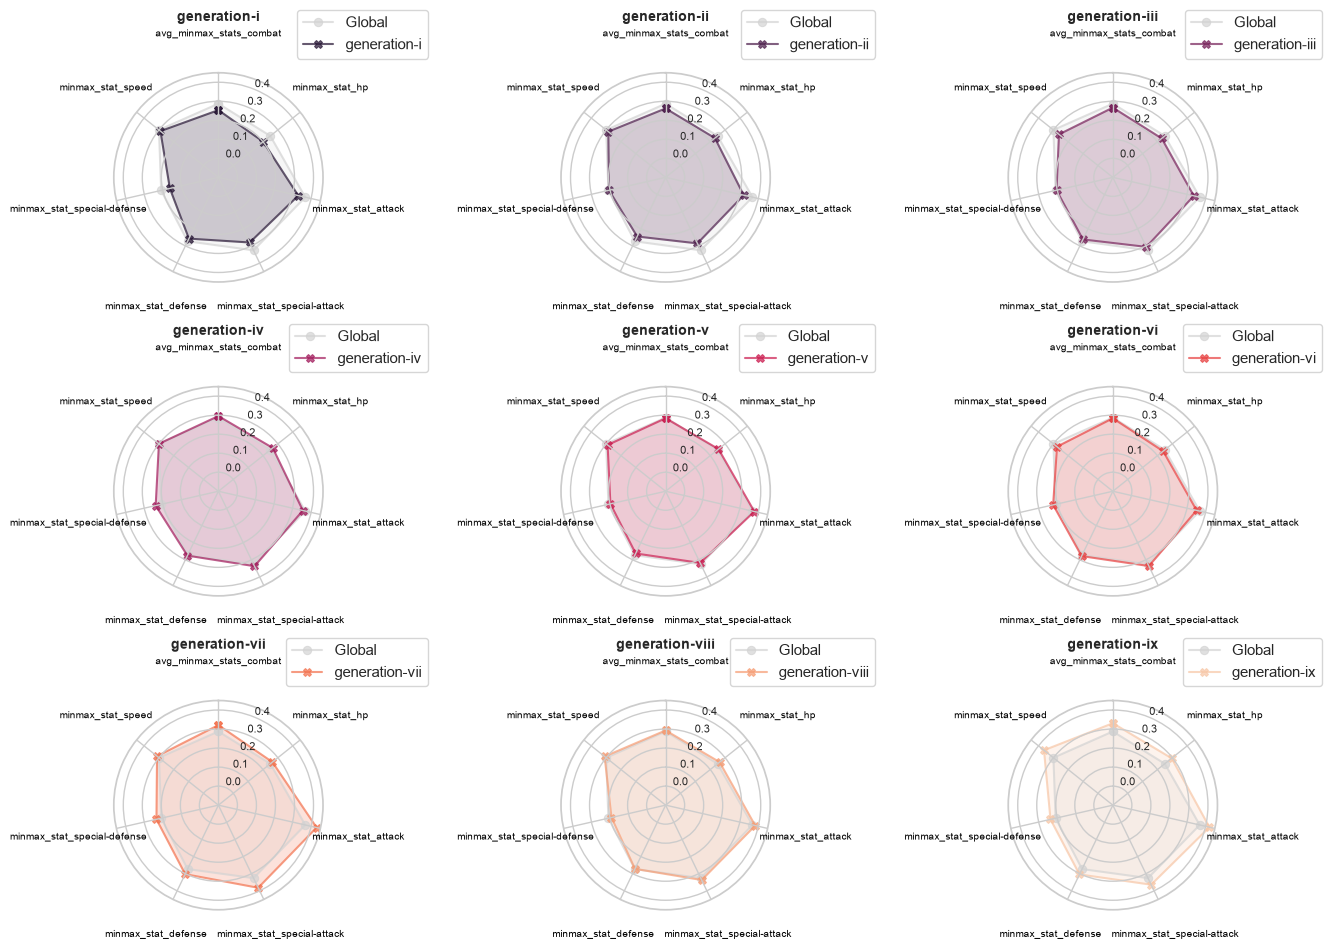

In [55]:
#Hacemos radar plot
radar_mean_stats_generation = facet_spider_plot(minmax_generation_global_means, other_categories=generation_order,palette=radar_generation_palette, 
                                                n_cols=3,n_rows=3, plot_size=(14,10))
##Guardar(png 300 dpi)
radar_mean_stats_generation.savefig("./results/radar_mean_stats_generation.png", dpi=300,bbox_inches='tight')
##Mostrar
radar_mean_stats_generation

Aquí tenemos el resultado, donde podemos ver que la mayoría de stats de combate suelen aumentar con respecto a los valores medios al pasar de las generaciones.

b) Violinplots:

En este caso, nos centraremos en las variables numericas `height_m`, `weight_kg`, `stats` sin escalado min-max, `avg_minmax_stats_combat` y `capture_rate`.

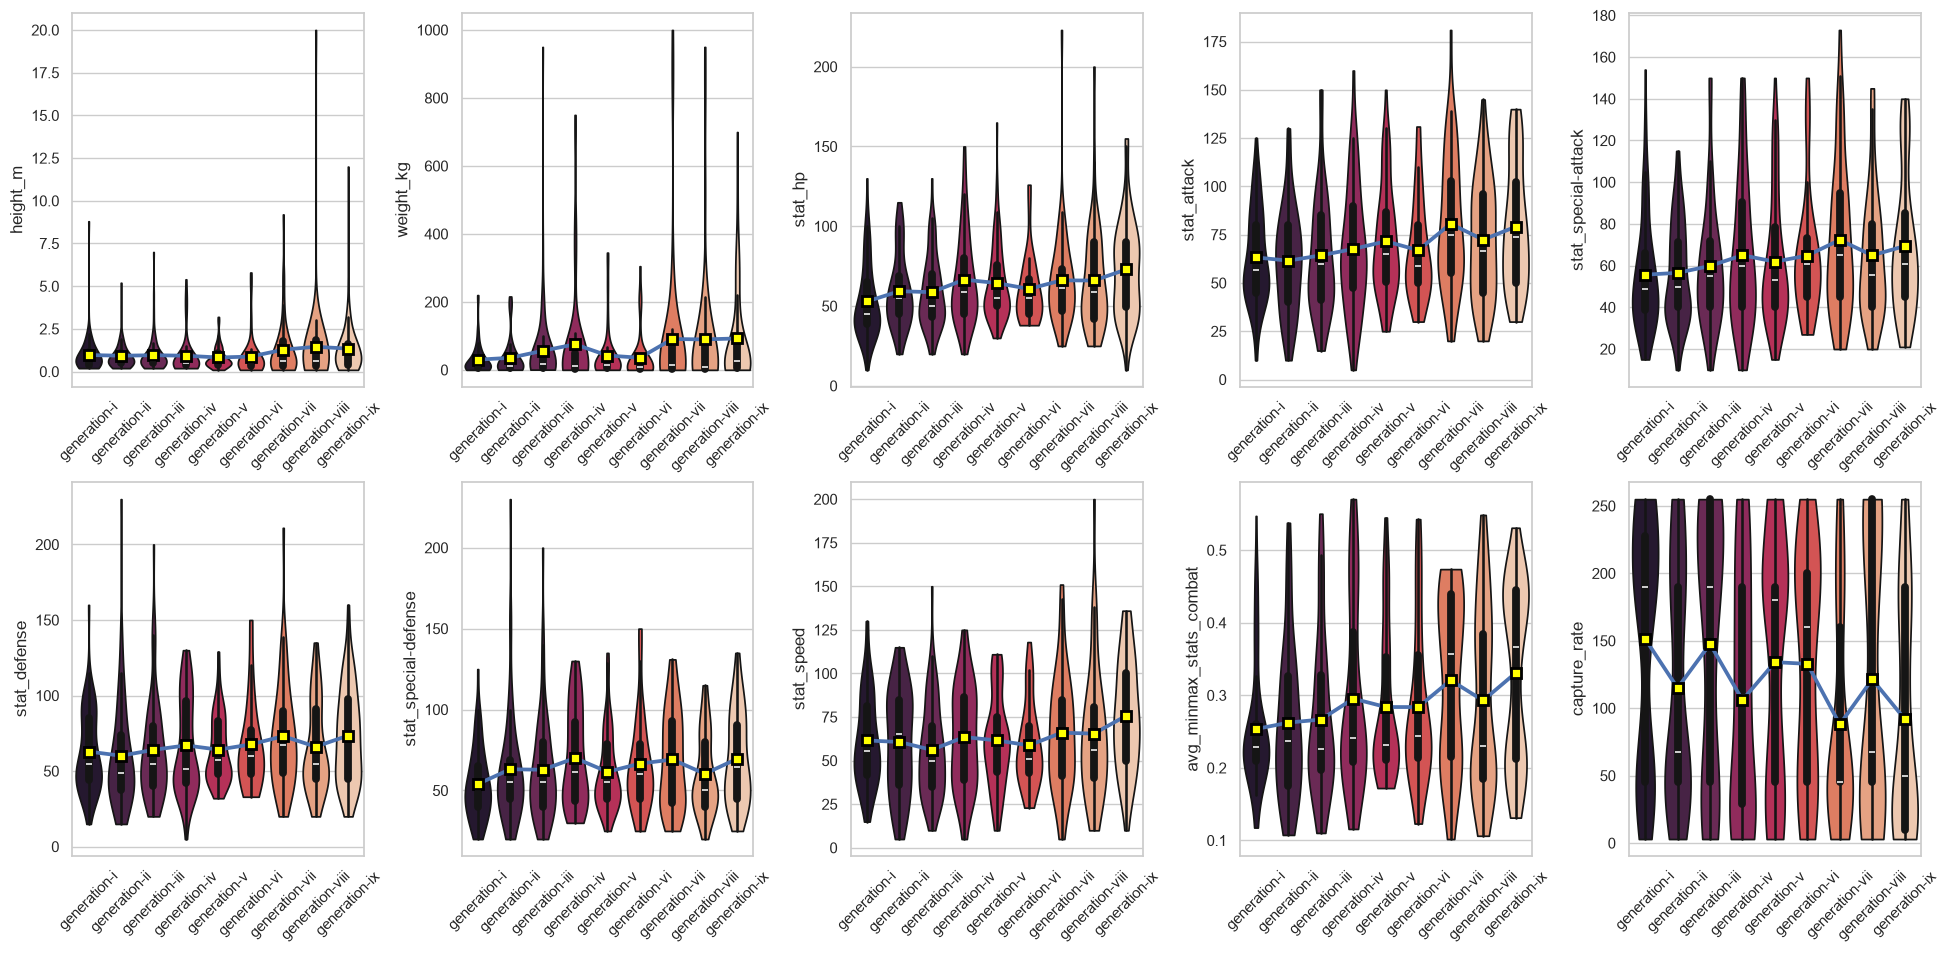

In [56]:
#Hacemos radar plot
violinplots_nums_generation = facet_violinplots_by_category(df_pokemon, "generation", columnas_numericas_ordered_filtered, 
                                                            generation_order,generation_palette, n_cols=5,n_rows=2, plot_size=(20,10))
##Guardar(png 300 dpi)
violinplots_nums_generation.savefig("./results/violinplots_nums_generation.png", dpi=300,bbox_inches='tight')
##Mostrar
violinplots_nums_generation

Aquí tenemos una representación de las distintas variables numéricas de interés por generación, donde se aprecia que en muchas de ellas parece haber una tendencia de aumento con el paso de las generaciones, excepto en el caso de `capture_rate` que hay una disminución.

c) Tests kruskal:

En este caso, vamos a hacer un test estadístico exploratorio. Como tenemos más de 2 grupos y no queremos perder mucho tiempo comprobando condiciones de aplicabilidad vamos a centrarnos en el test Kruskal que es no-paramétrico para multiples grupos y así sabremos por lo menos si hay diferencias significativas entre grupos.

In [57]:
matriz_kruskal_wallis(df_pokemon, ["generation"], columnas_numericas_ordered, alpha=0.05)

,Variable_Categorica,Variable_Numerica,Test,Estadistico_H,P_Valor,Alpha,Significativo
0,generation,height_m,Kruskal-Wallis,12.3114,0.137842,0.05,No
1,generation,weight_kg,Kruskal-Wallis,8.6891,0.369196,0.05,No
2,generation,stat_hp,Kruskal-Wallis,27.8853,0.000497,0.05,Sí
3,generation,minmax_stat_hp,Kruskal-Wallis,27.8853,0.000497,0.05,Sí
4,generation,stat_attack,Kruskal-Wallis,21.4873,0.005960,0.05,Sí
5,generation,minmax_stat_attack,Kruskal-Wallis,21.4873,0.005960,0.05,Sí
6,generation,stat_special-attack,Kruskal-Wallis,13.4276,0.097959,0.05,No
7,generation,minmax_stat_special-attack,Kruskal-Wallis,13.4276,0.097959,0.05,No
8,generation,stat_defense,Kruskal-Wallis,13.3574,0.100130,0.05,No
9,generation,minmax_stat_defense,Kruskal-Wallis,13.3574,0.100130,0.05,No


Como podemos ver al usar la variable categórica "generation" las variables min-max derivadas de los stats puros obtienen los mismos resultados. Con respecto a `height_m` y `weight_kg` no hay diferencias significativas entre generaciones. Con respecto a `stats`, `stat_hp`, `stat_attack`, `stat_special-defense` y `stat_speed`, si presentan alguna diferencia significativa. Por otro lado, la variable derivada `avg_minmax_stats_combat` presenta diferencias significativas. Así mismo la variable `capture_rate` también presenta diferencias significativas.

##### 6.2.2.2. Types como referencia

a) Radarplots para stats escalados min-max:

In [9]:
#Preparamos medias
##Generamos min-max means by types 
minmax_tupes_means_list = []
for t in columnas_bool:
    tmp_t_means = df_pokemon[df_pokemon[t]][columnas_minmax].mean().to_frame().reset_index()
    tmp_t_means.rename(columns={"index":"stat", 0:"value"},inplace=True)
    tmp_t_means["category"] = t.replace("type_","")
    minmax_tupes_means_list.append(tmp_t_means)
##Combinamos con la tabla previa global (minmax_global_means)
minmax_types_global_means =pd.concat([minmax_global_means]+minmax_tupes_means_list, ignore_index=True)
minmax_types_global_means

,stat,value,category
0,avg_minmax_stats_combat,0.287453,Global
1,minmax_stat_hp,0.249173,Global
2,minmax_stat_attack,0.368404,Global
3,minmax_stat_special-attack,0.325822,Global
4,minmax_stat_defense,0.272992,Global
...,...,...,...
128,minmax_stat_attack,0.387616,flying
129,minmax_stat_special-attack,0.357492,flying
130,minmax_stat_defense,0.252053,flying
131,minmax_stat_special-defense,0.214851,flying


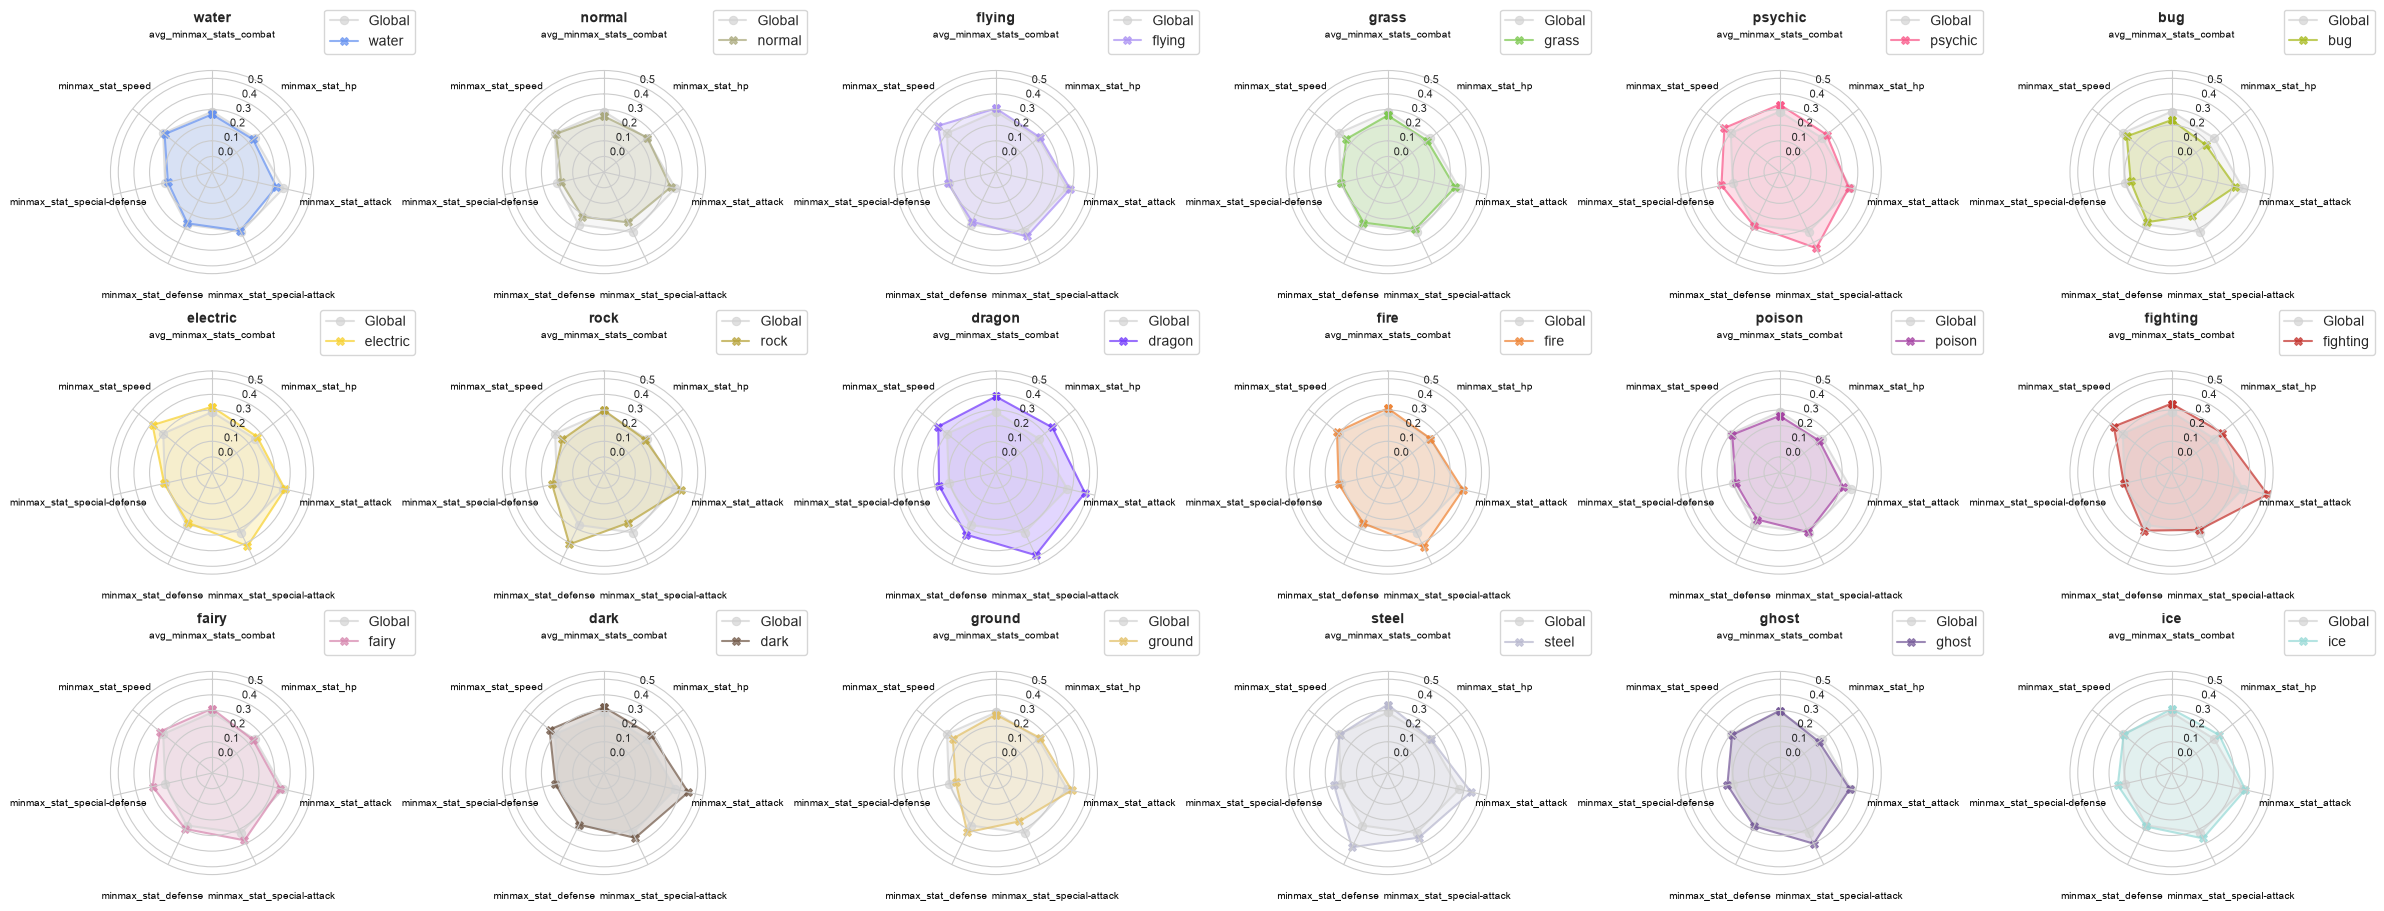

In [ ]:
#Hacemos radar plot
radar_mean_stats_types = facet_spider_plot(minmax_types_global_means, other_categories=order_types_descent,palette=radar_types_palette, 
                                                n_cols=6,n_rows=3, plot_size=(24,9.5), radar_limits=[-0.1,0.55])
##Guardar(png 300 dpi)
radar_mean_stats_types.savefig("./results/radar_mean_stats_types.png", dpi=300,bbox_inches='tight')
##Guardar(png 65 dpi, menor resolucion google slides)
radar_mean_stats_types.savefig("./results/radar_mean_stats_types_dpi65.png", dpi=65,bbox_inches='tight')
##Mostrar
radar_mean_stats_types

Por lo general, vemos bastantes tipos que sus stats presentan valores cercanos a los stats medios globales. También encontramos tipos que destacán con muchos stats simultaneamente por encima de las medias globales, en especial el tipo dragon, pero también otros como electric, o fighting. Además, también vemos tipos con valores stats que por lo general están por debajo de las medias globales, como los tipos bug.

b) violinplots:

In [60]:
#Vamos a generar una versión con filas repetidas en base a las columnas bool de types
lista_chunks = []
#Iniciamos lista df filtrados por columnas bool
for col_bool in columnas_bool:
    tmp_filt = df_pokemon[df_pokemon[col_bool]]
    tmp_chunk = tmp_filt[columnas_numericas_ordered_filtered].copy()
    tmp_chunk["Types"] = col_bool.replace("type_","")
    lista_chunks.append(tmp_chunk)
df_pokemon_types = pd.concat(lista_chunks, ignore_index=True)
df_pokemon_types

,height_m,weight_kg,stat_hp,stat_attack,stat_special-attack,stat_defense,stat_special-defense,stat_speed,avg_minmax_stats_combat,capture_rate,Types
0,0.3,2.9,45,30,20,35,20,45,0.117696,255,bug
1,0.3,3.2,40,35,20,30,20,50,0.119088,255,bug
2,0.3,5.4,35,70,45,55,55,25,0.198811,190,bug
3,1.0,30.0,60,55,40,50,55,45,0.212446,190,bug
4,1.5,56.0,70,110,55,80,80,105,0.381037,45,bug
...,...,...,...,...,...,...,...,...,...,...,...
794,0.6,2.4,82,96,45,51,51,92,0.311336,190,flying
795,0.4,3.6,40,40,55,35,40,70,0.196281,180,flying
796,1.5,42.9,70,103,60,85,85,82,0.367535,25,flying
797,1.6,37.0,82,115,75,74,64,90,0.385648,100,flying


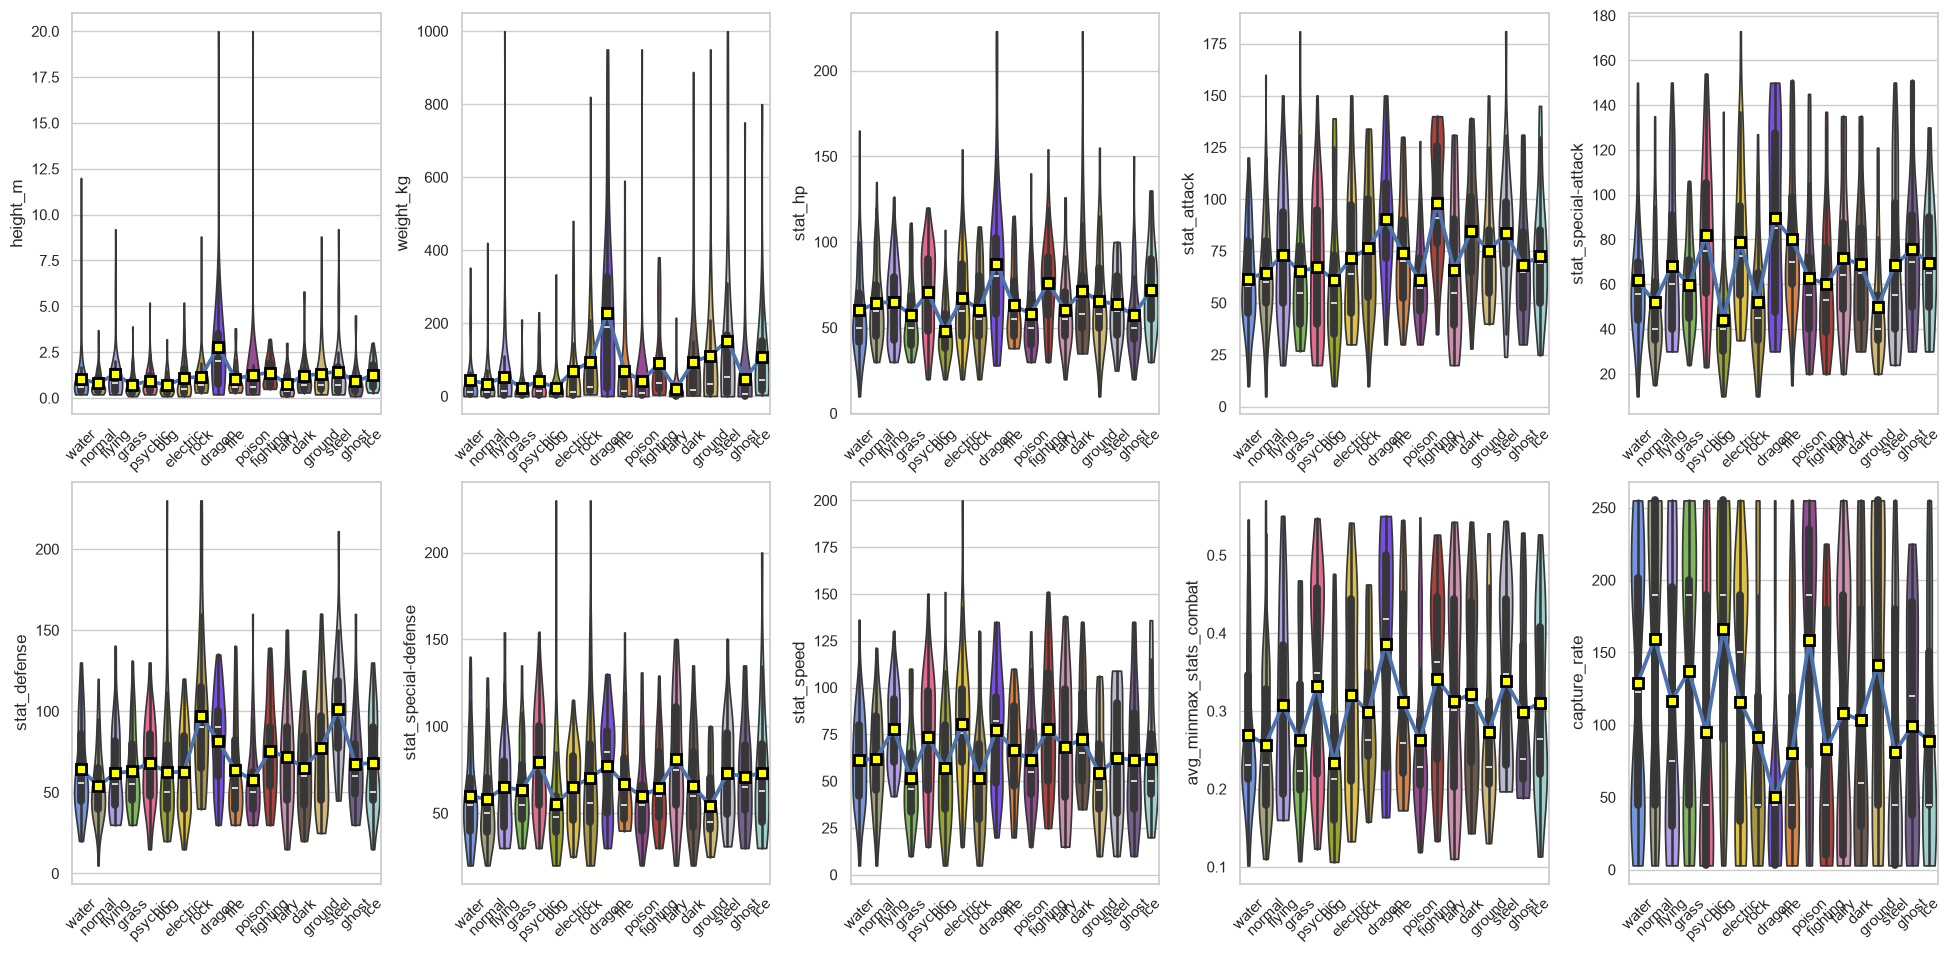

In [61]:
#Hacemos radar plot
violinplots_nums_types = facet_violinplots_by_category(df_pokemon_types, "Types", columnas_numericas_ordered_filtered, 
                                                            order_types_descent,types_palette, n_cols=5,n_rows=2, plot_size=(20,10))
##Guardar(png 300 dpi)
violinplots_nums_types.savefig("./results/violinplots_nums_types.png", dpi=300,bbox_inches='tight')
##Mostrar
violinplots_nums_types

Por lo general vemos que las variables suelen depender mucho del tipo de Pokémon. Por ejemplo, vemos que el tipo dragon suele presentar valores de altura, peso y muchos stats mayores que el resto, pero también presentan las tasas medias de captura más bajas. 

c) Tests kruskal:

En este caso, técnicamente no sería correcto aplicar estos test estadísticas pues tenemos observaciones repetidas ya que hay Pokémon que están representados en más de un type. Por ello, en este apartado nos quedaremos unicamente con los gráficos descriptivos de los apartados superiores sin realizar los test estadísticos. Habría que recurrir a otras aproximación que se salen del alcance de este ejercicio.

##### 6.2.2.3. Shape como referencia

a) Radarplots para stats escalados min-max:

In [13]:
#Preparamos medias
##Generamos min-max means by generation 
minmax_shape_means=df_pokemon.groupby('shape')[columnas_minmax].mean().reset_index().melt(id_vars=["shape"], var_name="stat", value_name="value")
minmax_shape_means.rename(columns={"shape":"category"}, inplace=True)
minmax_shape_means
##Combinamos con la tabla previa global (minmax_global_means)
minmax_shape_global_means =pd.concat([minmax_global_means,minmax_shape_means], ignore_index=True)
minmax_shape_global_means

,stat,value,category
0,avg_minmax_stats_combat,0.287453,Global
1,minmax_stat_hp,0.249173,Global
2,minmax_stat_attack,0.368404,Global
3,minmax_stat_special-attack,0.325822,Global
4,minmax_stat_defense,0.272992,Global
...,...,...,...
100,minmax_stat_speed,0.317423,quadruped
101,minmax_stat_speed,0.245177,squiggle
102,minmax_stat_speed,0.264957,tentacles
103,minmax_stat_speed,0.319298,upright


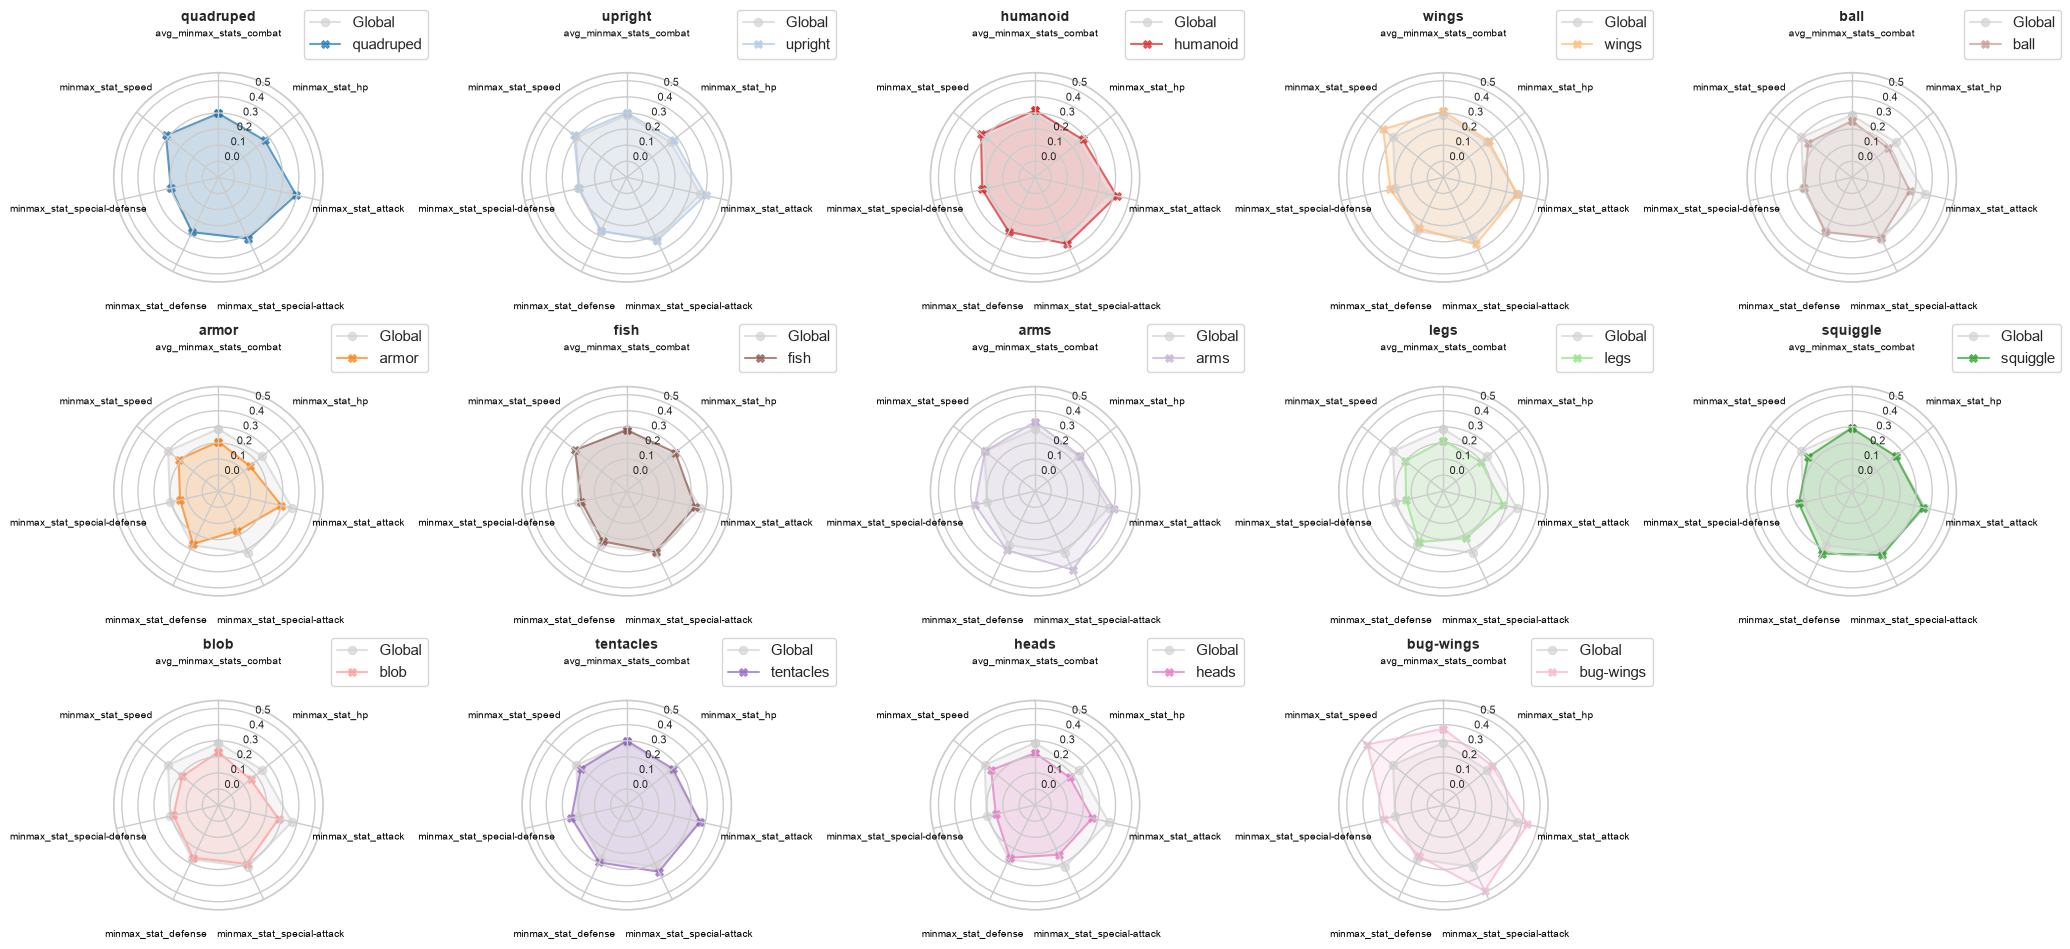

In [ ]:
#Hacemos radar plot
radar_mean_stats_shapes = facet_spider_plot(minmax_shape_global_means, other_categories=order_shape_descent,palette=radar_shapes_palette, 
                                                n_cols=5,n_rows=3, plot_size=(21,10), radar_limits=[-0.1,0.55])
##Guardar(png 300 dpi)
radar_mean_stats_shapes.savefig("./results/radar_mean_stats_shapes.png", dpi=300,bbox_inches='tight')
##Guardar(png 90 dpi para google slides)
radar_mean_stats_shapes.savefig("./results/radar_mean_stats_shapes_dpi90.png", dpi=90,bbox_inches='tight')
##Mostrar
radar_mean_stats_shapes

Por lo general, vemos formas que presentan stats con valores cercanos a los stats medios globales, pero también encontramos varias formas con varios stats por debajo de las medias globales como las formas blob, heads, legs, armor y ball. Curiosamente las formas wings y en especial bug-wings presentan valores superiores a los stats medios, destacando en el avg y los stats speed, special-defense, special-attack.

b) Violinplots:

En este caso, nos centraremos en las variables numéricas `height_m`, `weight_kg`, `stats` sin escalado min-max, `avg_minmax_stats_combat` y `capture_rate`.

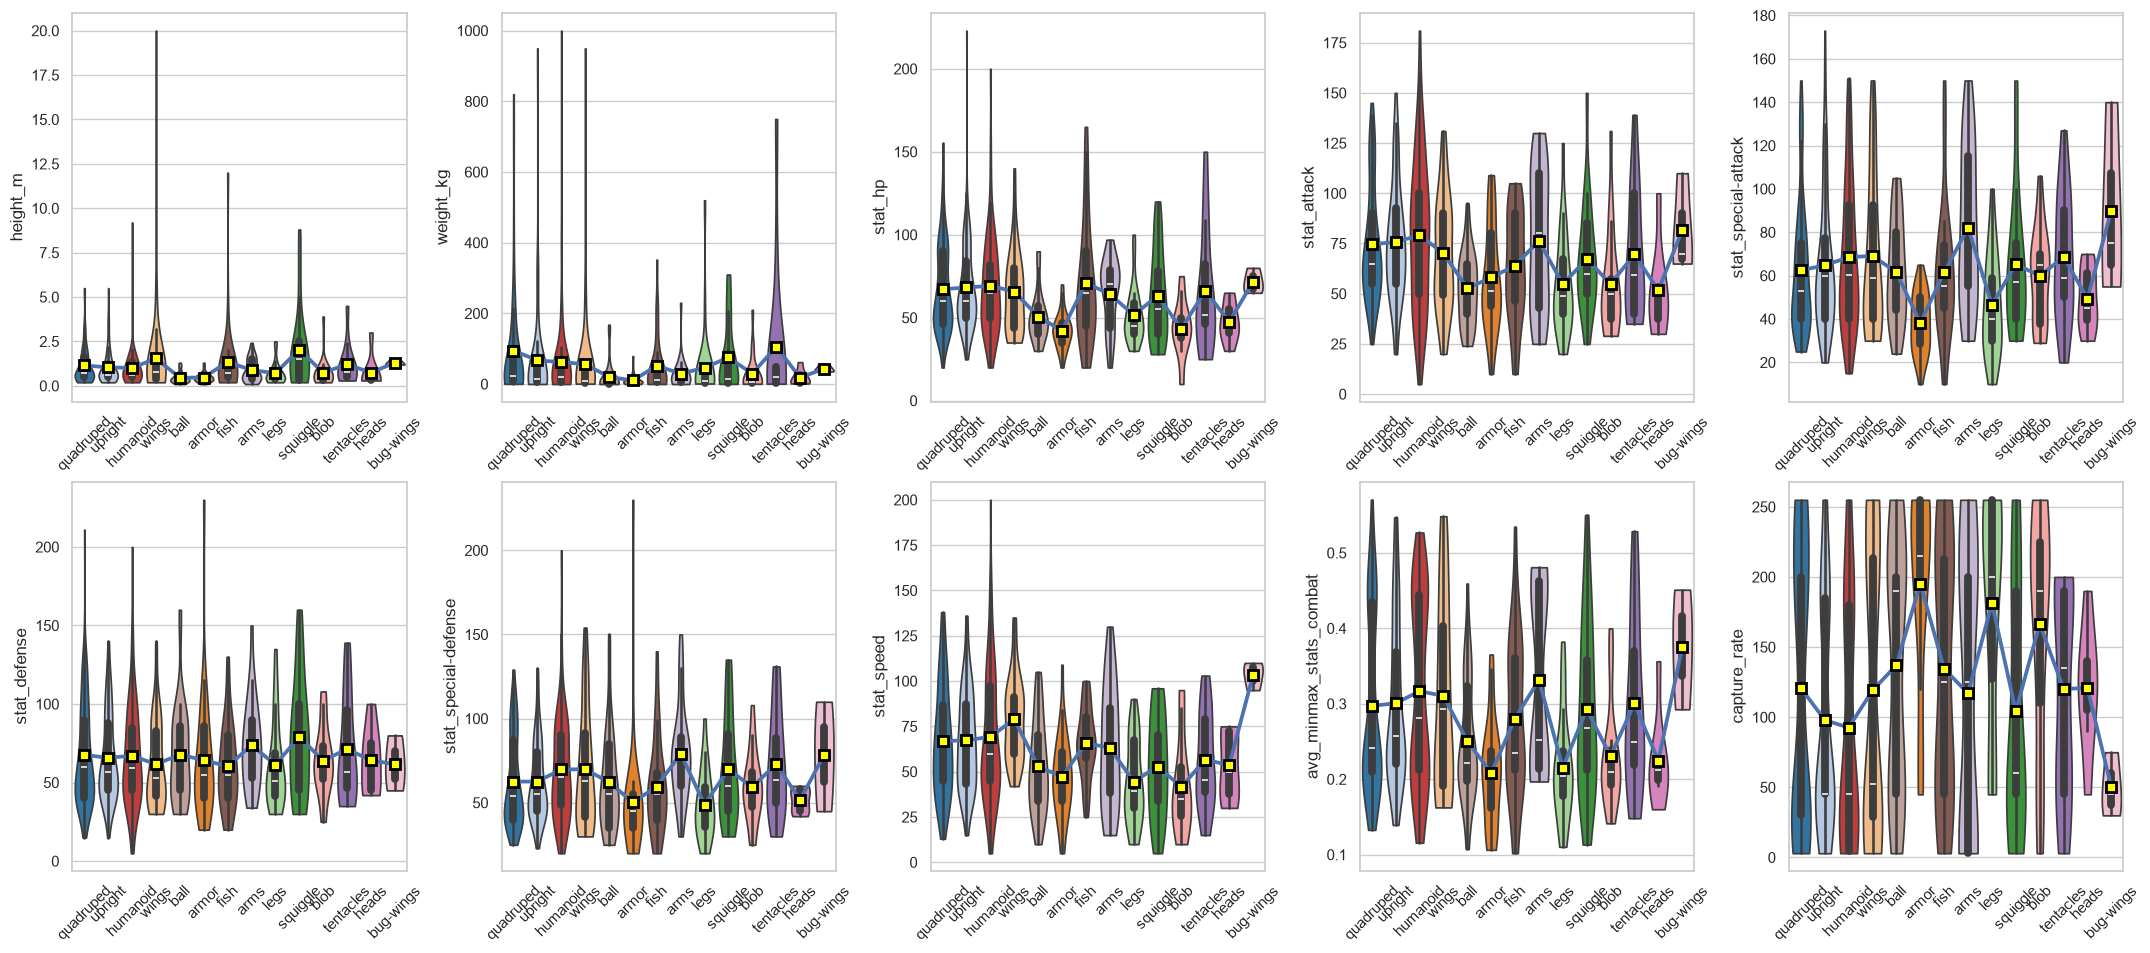

In [64]:
#Hacemos radar plot
violinplots_nums_shape = facet_violinplots_by_category(df_pokemon, "shape", columnas_numericas_ordered_filtered, 
                                                            order_shape_descent,shapes_palette, n_cols=5,n_rows=2, plot_size=(22,10))
##Guardar(png 300 dpi)
violinplots_nums_shape.savefig("./results/violinplots_nums_shape.png", dpi=300,bbox_inches='tight')
##Mostrar
violinplots_nums_shape

De nuevo, vemos que las variables suelen depender mucho de la forma de Pokémon. Es interesante ver que la forma `bug-wings` destaca en varias categorias de stats (hp, attack, special-attack, special-defense, speed, avg_minmax_stats_combat). Sin embargo, están entre los más difíciles de capturar en termino medio (aunque también entran dentro de los rangos de captura de otras formas). Veamos quienes son:

In [65]:
df_pokemon[df_pokemon["shape"] == "bug-wings"]

,id,name,generation,shape,capture_rate,stat_hp,stat_attack,stat_special-attack,stat_defense,stat_special-defense,...,type_dark,type_fairy,type_fighting,type_water,type_ice,type_rock,type_fire,type_psychic,type_grass,type_flying
51,123,scyther,generation-i,bug-wings,45,70,110,55,80,80,...,False,False,False,False,False,False,False,False,False,True
85,193,yanma,generation-ii,bug-wings,75,65,65,75,45,45,...,False,False,False,False,False,False,False,False,False,True
516,994,iron-moth,generation-ix,bug-wings,30,80,70,140,60,110,...,False,False,False,False,False,False,True,False,False,False


c) Tests kruskal:

En este caso, vamos a hacer un test estadístico exploratorio. Como tenemos más de 2 grupos y no queremos perder mucho tiempo comprobando condiciones de aplicabilidad vamos a centrarnos en el test Kruskal que es no-paramétrico para múltiples grupos y así sabremos por lo menos si hay diferencias significativas entre grupos.

In [66]:
matriz_kruskal_wallis(df_pokemon, ["shape"], columnas_numericas_ordered, alpha=0.05)

,Variable_Categorica,Variable_Numerica,Test,Estadistico_H,P_Valor,Alpha,Significativo
0,shape,height_m,Kruskal-Wallis,60.3099,4.623787e-08,0.05,Sí
1,shape,weight_kg,Kruskal-Wallis,59.3956,6.736100e-08,0.05,Sí
2,shape,stat_hp,Kruskal-Wallis,73.8592,1.551707e-10,0.05,Sí
3,shape,minmax_stat_hp,Kruskal-Wallis,73.8592,1.551707e-10,0.05,Sí
4,shape,stat_attack,Kruskal-Wallis,48.2259,5.989699e-06,0.05,Sí
5,shape,minmax_stat_attack,Kruskal-Wallis,48.2259,5.989699e-06,0.05,Sí
6,shape,stat_special-attack,Kruskal-Wallis,45.8411,1.513726e-05,0.05,Sí
7,shape,minmax_stat_special-attack,Kruskal-Wallis,45.8411,1.513726e-05,0.05,Sí
8,shape,stat_defense,Kruskal-Wallis,8.6191,8.010647e-01,0.05,No
9,shape,minmax_stat_defense,Kruskal-Wallis,8.6191,8.010647e-01,0.05,No


Podemos ver que al usar la variable categórica "shape", de nuevo las variables min-max derivadas de los stats puros obtienen los mismos resultados. En este caso, se observan diferencias significativas en todas las variables numéricas con la excepción de `stat_defense` y `minmax_stat_defense`.

#### 6.2.3. Análisis entre variables numéricas

a) Análisis de correlación de Spearman:

Ahora, realizaremos un análisis de correlación usando el método no-paramétrico de Spearman.

In [76]:
#Calculamos la matriz de correlación usando la funcionalidad corr de pandas
corr_matrix = df_pokemon[columnas_numericas_ordered].corr(numeric_only= True, method="spearman") # Si no lo pones y tienes variables tipo texto, fallará7
corr_matrix

,height_m,weight_kg,stat_hp,minmax_stat_hp,stat_attack,minmax_stat_attack,stat_special-attack,minmax_stat_special-attack,stat_defense,minmax_stat_defense,stat_special-defense,minmax_stat_special-defense,stat_speed,minmax_stat_speed,avg_minmax_stats_combat,capture_rate
height_m,1.000000,0.838973,0.593041,0.593041,0.578457,0.578457,0.411722,0.411722,0.459079,0.459079,0.455263,0.455263,0.381466,0.381466,0.631151,-0.480154
weight_kg,0.838973,1.000000,0.579617,0.579617,0.544638,0.544638,0.306961,0.306961,0.497416,0.497416,0.428095,0.428095,0.250590,0.250590,0.571327,-0.448963
stat_hp,0.593041,0.579617,1.000000,1.000000,0.656187,0.656187,0.506555,0.506555,0.562964,0.562964,0.567050,0.567050,0.386940,0.386940,0.759984,-0.576822
minmax_stat_hp,0.593041,0.579617,1.000000,1.000000,0.656187,0.656187,0.506555,0.506555,0.562964,0.562964,0.567050,0.567050,0.386940,0.386940,0.759984,-0.576822
stat_attack,0.578457,0.544638,0.656187,0.656187,1.000000,1.000000,0.417037,0.417037,0.588552,0.588552,0.389964,0.389964,0.472226,0.472226,0.771193,-0.590659
minmax_stat_attack,0.578457,0.544638,0.656187,0.656187,1.000000,1.000000,0.417037,0.417037,0.588552,0.588552,0.389964,0.389964,0.472226,0.472226,0.771193,-0.590659
stat_special-attack,0.411722,0.306961,0.506555,0.506555,0.417037,0.417037,1.000000,1.000000,0.380035,0.380035,0.609860,0.609860,0.498326,0.498326,0.757499,-0.580913
minmax_stat_special-attack,0.411722,0.306961,0.506555,0.506555,0.417037,0.417037,1.000000,1.000000,0.380035,0.380035,0.609860,0.609860,0.498326,0.498326,0.757499,-0.580913
stat_defense,0.459079,0.497416,0.562964,0.562964,0.588552,0.588552,0.380035,0.380035,1.000000,1.000000,0.629694,0.629694,0.220656,0.220656,0.713169,-0.531568
minmax_stat_defense,0.459079,0.497416,0.562964,0.562964,0.588552,0.588552,0.380035,0.380035,1.000000,1.000000,0.629694,0.629694,0.220656,0.220656,0.713169,-0.531568


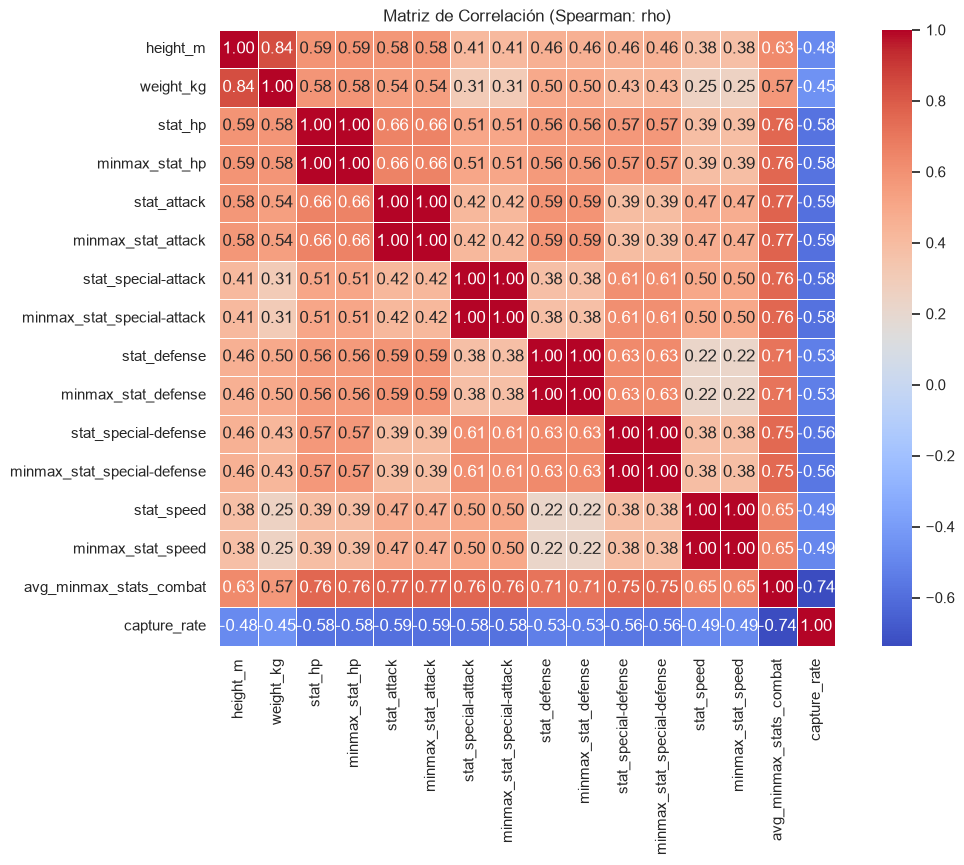

In [77]:
#Definimos tamaño
plt.figure(figsize=(12, 8))
#Generamos plot inicial
sns_heatmap_spearman = sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True, linewidths=.5)
#Añadimos titulo
sns_heatmap_spearman.set_title('Matriz de Correlación (Spearman: rho)')
#Guardar plot
sns_heatmap_spearman.get_figure().savefig("./results/sns_heatmap_spearman.png", dpi=300,bbox_inches='tight')
#Mostrar plot
sns_heatmap_spearman;

In [78]:
spearman_results=matriz_spearman(df_pokemon[columnas_numericas_ordered])
spearman_results

,Variable 1,Variable 2,Test,Estadístico (rho),p-valor,Alpha,Significativo
0,height_m,height_m,Spearman,1.0000,0.0,0.05,Sí
1,height_m,weight_kg,Spearman,0.8390,0.0,0.05,Sí
2,height_m,stat_hp,Spearman,0.5930,0.0,0.05,Sí
3,height_m,minmax_stat_hp,Spearman,0.5930,0.0,0.05,Sí
4,height_m,stat_attack,Spearman,0.5785,0.0,0.05,Sí
...,...,...,...,...,...,...,...
131,minmax_stat_speed,avg_minmax_stats_combat,Spearman,0.6451,0.0,0.05,Sí
132,minmax_stat_speed,capture_rate,Spearman,-0.4949,0.0,0.05,Sí
133,avg_minmax_stats_combat,avg_minmax_stats_combat,Spearman,1.0000,0.0,0.05,Sí
134,avg_minmax_stats_combat,capture_rate,Spearman,-0.7360,0.0,0.05,Sí


In [79]:
spearman_results.Significativo.describe()

count     136
unique      1
top        Sí
freq      136
Name: Significativo, dtype: object

Vemos que todos los p-valores son significativos con un alfa=0.05. En el heatmap vemos varias cosas:
- Stats y sus respectivas min-max derivadas dan valores idénticos y una correlación positiva máxima entre sus respectivos.
* La mayoría de comparaciones presentan correlaciones positivas,la única excepción con correlaciones negativas son las que implican a la variable `capture_rate`.
- Hay una correlación positiva fuerte entre `height_m` y `weight_kg` (rho=0.8390).
* También hay una correlación negativa fuerte entre `avg_minmax_stats_combat` y `capture_rate` (rho=-0.7360).

b) Vamos a generar un pairplot:

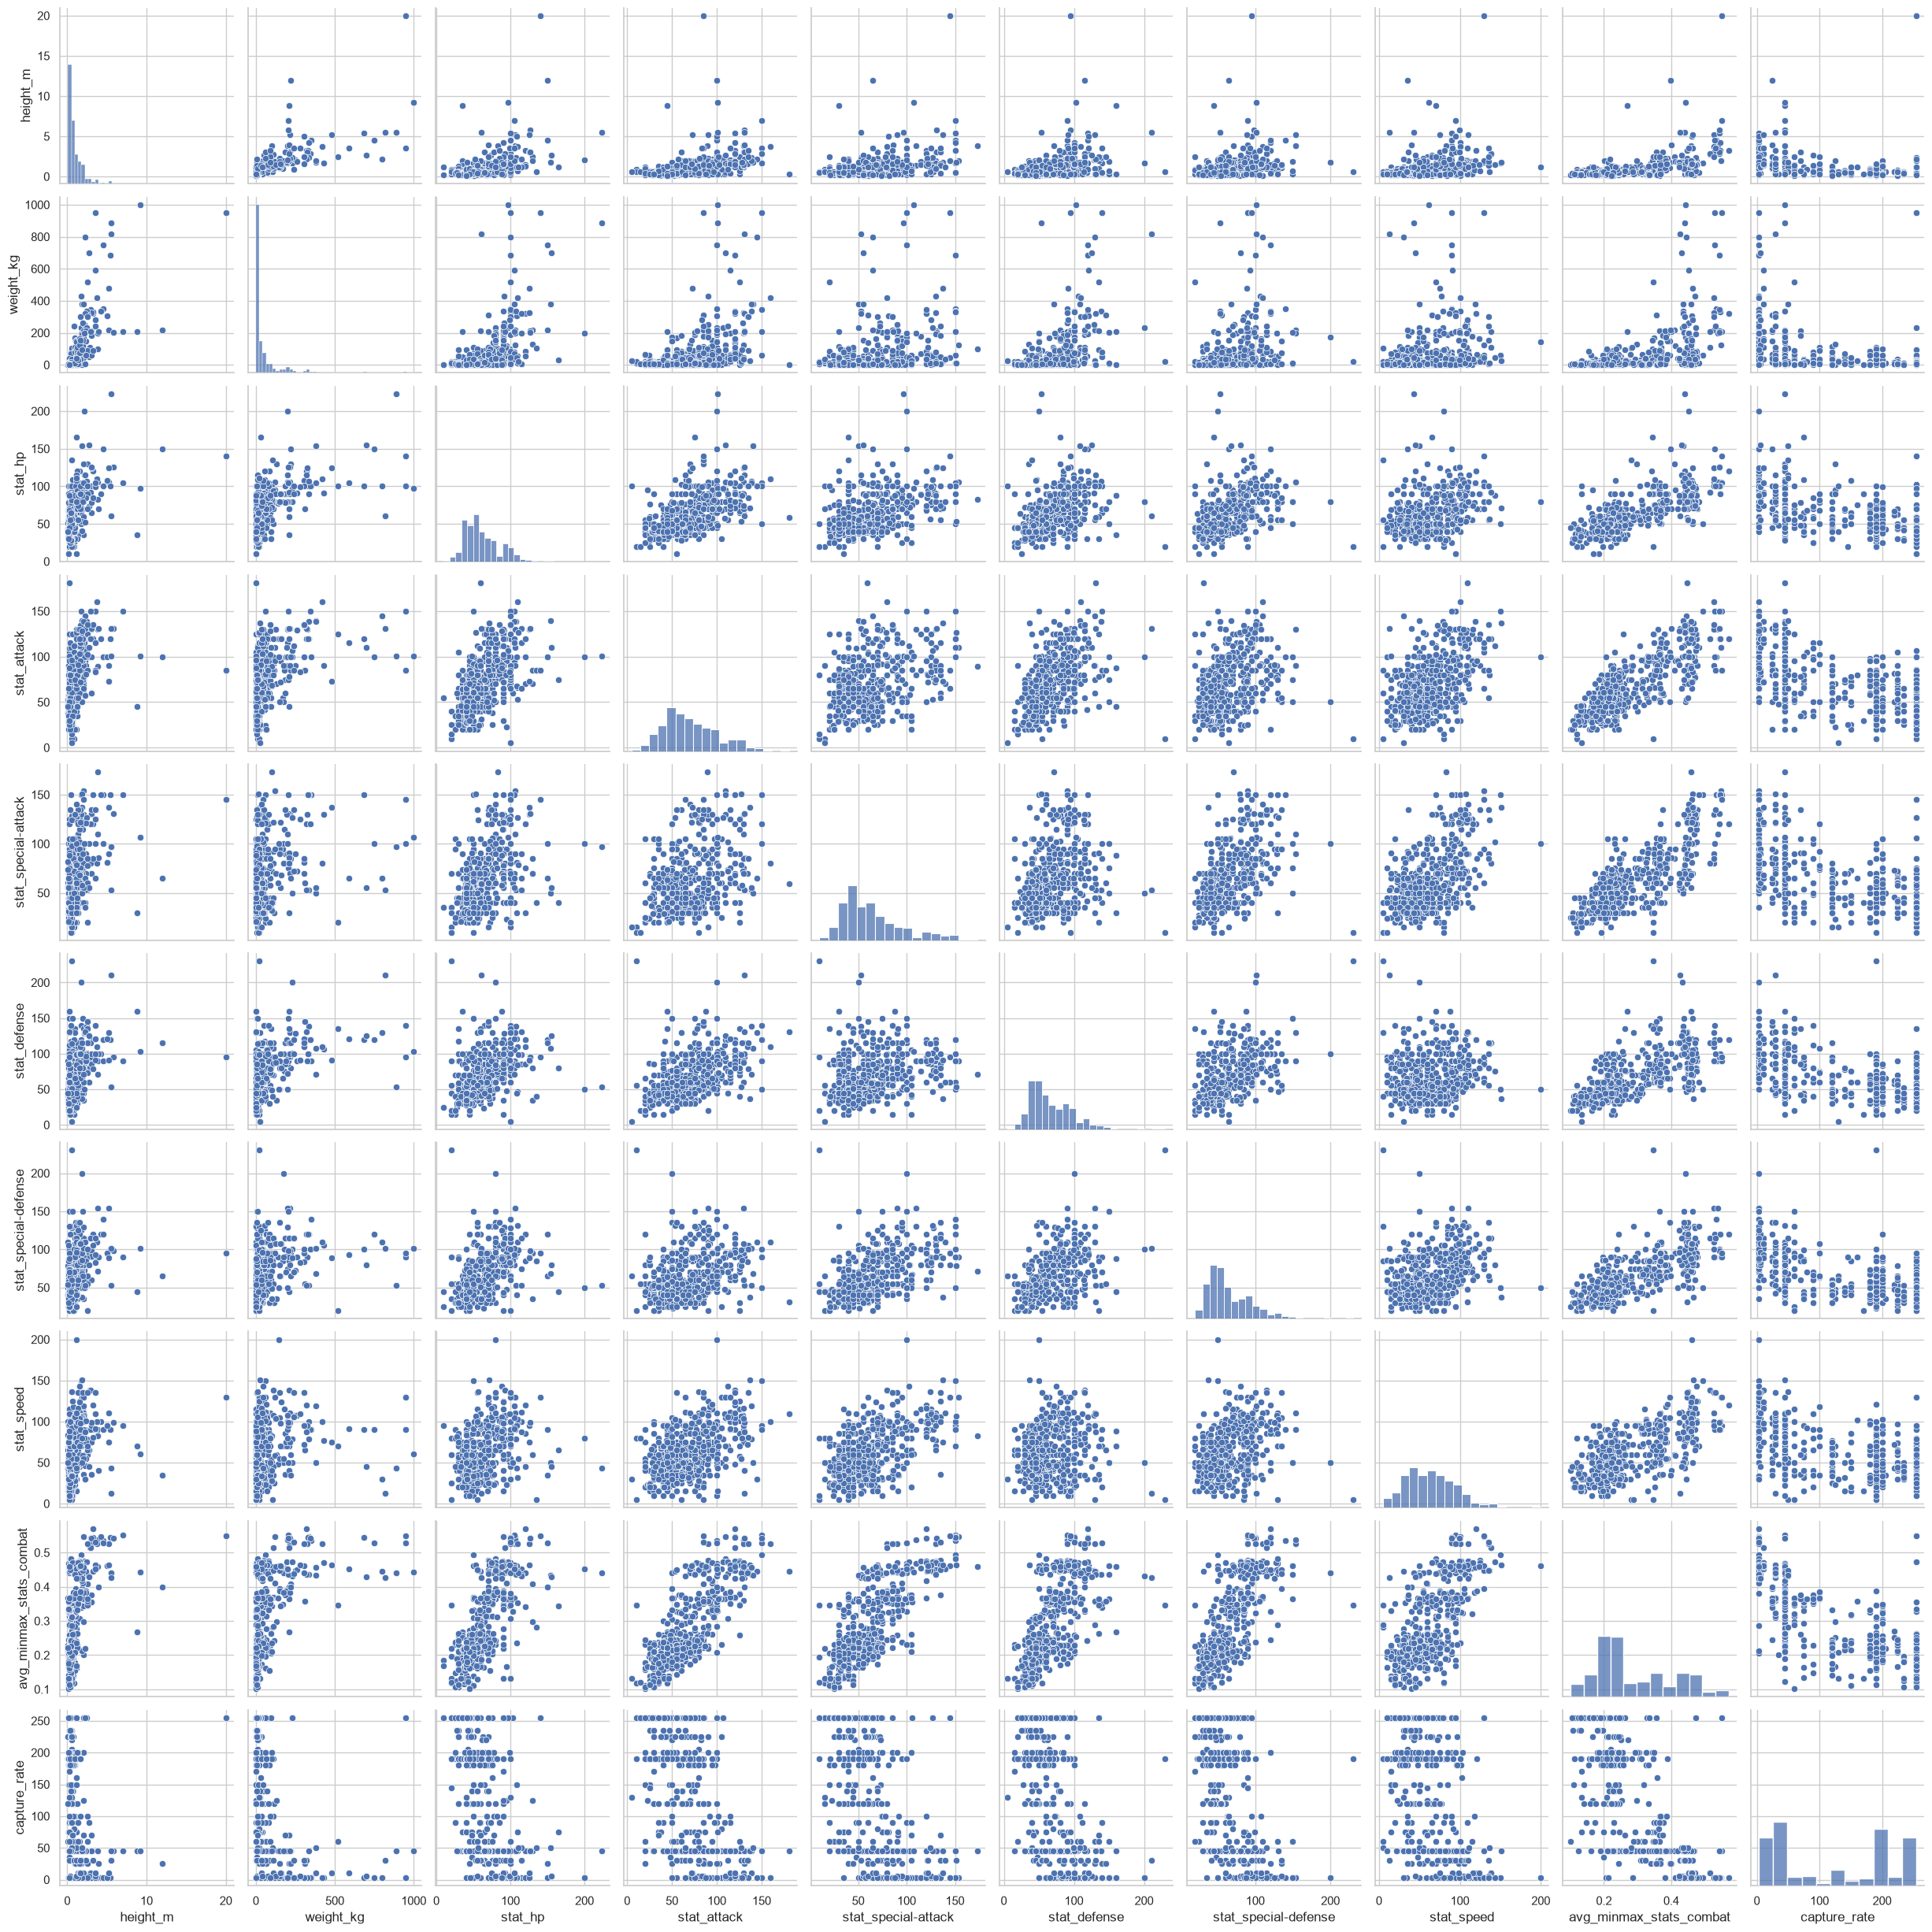

In [80]:
#Por simplicidad visual representamos columnas_numericas_ordered_filtered
pairplot_pokemon_nums=sns.pairplot(df_pokemon[columnas_numericas_ordered_filtered])
#Guardar plot
pairplot_pokemon_nums.figure.savefig("./results/pairplot_pokemon_nums.png", dpi=300,bbox_inches='tight')
#Mostrar plot
pairplot_pokemon_nums;

c) Análisis entre `avg_minmax_stats_combat` y `capture_rate`:

Ahora, vamos a hacer un análisis comparando las variables `avg_minmax_stats_combat` y `capture_rate` con la idea de buscar Pokémon de interés.

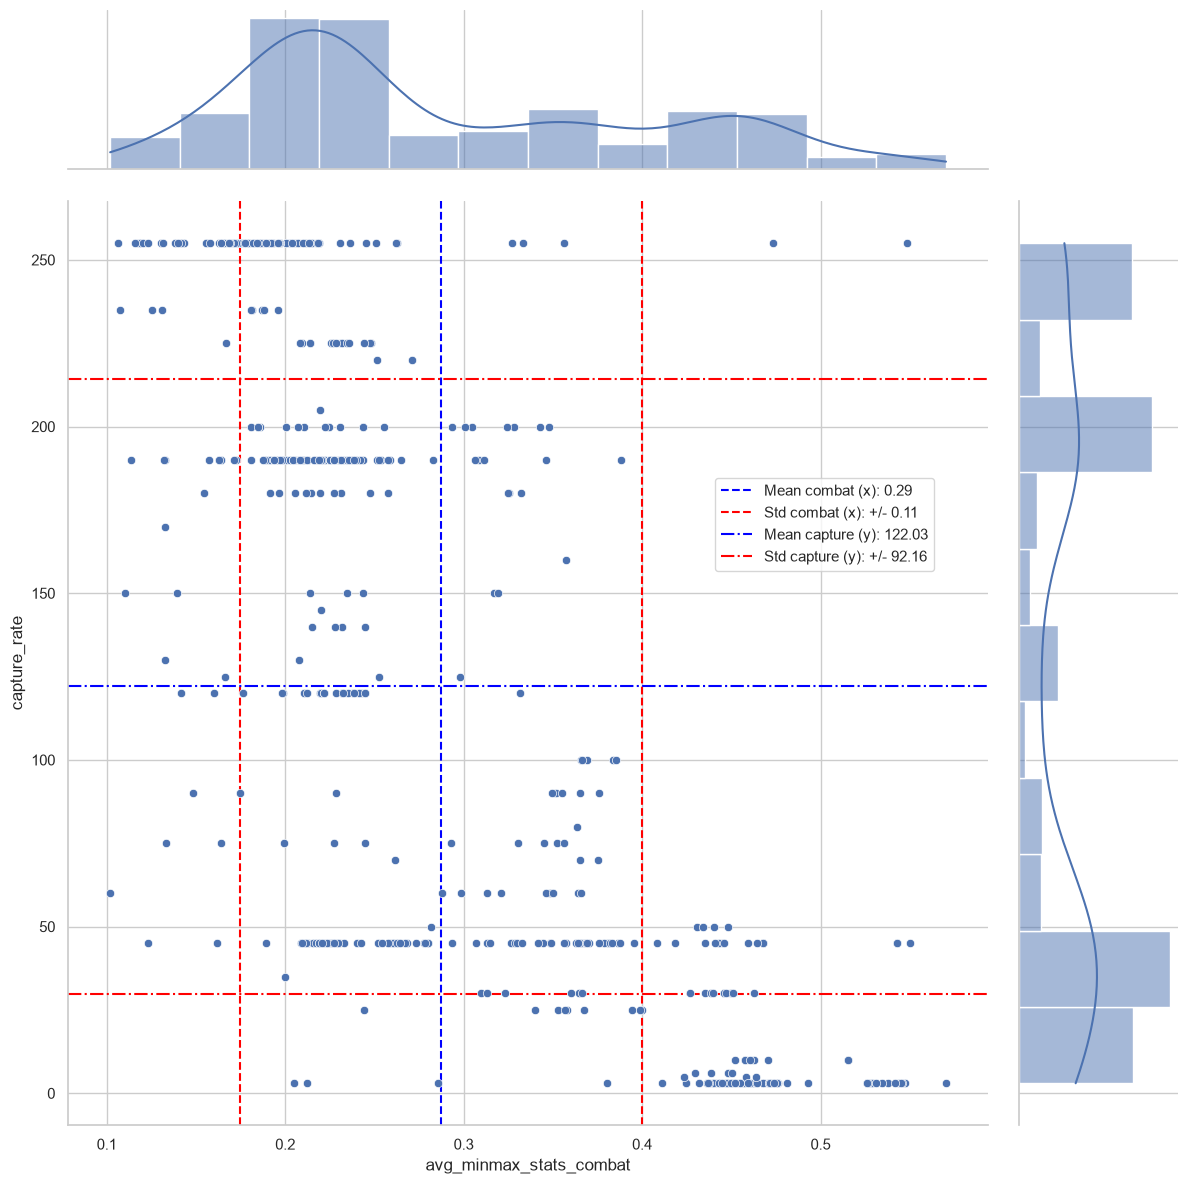

In [81]:
#Generamos plot inicial
##jointplot genera un cuadrado, la altura se controla con height
sns_dotplot_capture_combat = sns.jointplot(df_pokemon, x="avg_minmax_stats_combat", y="capture_rate", 
                                           height=12,
                                           kind="scatter",  # Gráfico central
                                           marginal_kws=dict(kde=True))
# Calculamos valores mean y std
mean_combat=df_pokemon["avg_minmax_stats_combat"].mean()
std_combat=df_pokemon["avg_minmax_stats_combat"].std()
mean_capture=df_pokemon["capture_rate"].mean()
std_capture=df_pokemon["capture_rate"].std()
#Añadimos lineas de means y stds
sns_dotplot_capture_combat.ax_joint.axvline(mean_combat, color='blue', linestyle='--', linewidth=1.5, label=f'Mean combat (x): {mean_combat:.2f}', zorder=1)
sns_dotplot_capture_combat.ax_joint.axvline(mean_combat+std_combat, color='red', linestyle='--', linewidth=1.5, label=f'Std combat (x): +/- {std_combat:.2f}', zorder=1)
sns_dotplot_capture_combat.ax_joint.axvline(mean_combat-std_combat, color='red', linestyle='--', linewidth=1.5, zorder=1)
sns_dotplot_capture_combat.ax_joint.axhline(mean_capture, color='blue', linestyle='-.', linewidth=1.5, label=f'Mean capture (y): {mean_capture:.2f}', zorder=1)
sns_dotplot_capture_combat.ax_joint.axhline(mean_capture+std_capture, color='red', linestyle='-.', linewidth=1.5, label=f'Std capture (y): +/- {std_capture:.2f}', zorder=1)
sns_dotplot_capture_combat.ax_joint.axhline(mean_capture-std_capture, color='red', linestyle='-.', linewidth=1.5, zorder=1)
#Para que los puntos queden por encima de las lineas
sns_dotplot_capture_combat.ax_joint.collections[0].set_zorder(2)
# Mostrar la leyenda en el cuadro central derecha
sns_dotplot_capture_combat.ax_joint.legend(loc="center right",bbox_to_anchor=(0.95, 0.65), frameon=True)

#Guardar plot
sns_dotplot_capture_combat.figure.savefig("./results/sns_dotplot_capture_combat.png", dpi=300,bbox_inches='tight')
#Mostrar plot
sns_dotplot_capture_combat;

Confirma lo que habíamos visto en el plot de correlación y nuestra hipótesis de partida, que por lo general hay una relación inversa entre `avg_minmax_stats_combat` y `capture_rate`. 

Vemos 3 zonas bien diferenciadas:

- La primera corresponde a aquellos que son fáciles de capturar, y que por lo general presentan stats de combate menores.
* Después tenemos una zona intermedia que por lo general presenta valores cercanos a las medias de `avg_minmax_stats_combat` y `capture_rate`.
- La última corresponde a aquellos que son difíciles de capturar, y que por lo general presentan stats de combate mayores.

Analicemos algunos casos de interés:

C.1) Vemos algunos outliers de interés que se encuentran en la zona ideal de alta tasa de captura y con `avg_minmax_stats_combat` elevado, pasándo los límites superiores de las stds de ambas variables. Estos serían los Pokémon ideales que intentar capturar si tenemos oportunidad. Veamos quienes son:

In [82]:
df_pokemon[(df_pokemon["avg_minmax_stats_combat"]>(mean_combat+std_combat)) & (df_pokemon["capture_rate"]>(mean_capture+std_capture))]

,id,name,generation,shape,capture_rate,stat_hp,stat_attack,stat_special-attack,stat_defense,stat_special-defense,...,type_dark,type_fairy,type_fighting,type_water,type_ice,type_rock,type_fire,type_psychic,type_grass,type_flying
413,800,necrozma,generation-vii,arms,255,97,107,127,101,89,...,False,False,False,False,False,False,False,True,False,False
460,890,eternatus,generation-viii,wings,255,140,85,145,95,95,...,False,False,False,False,False,False,False,False,False,False


Después de investigar un poco estos dos Pokémon son legendarios con ciertas particularidades, pues tienen la tasa de captura máxima 255 por necesidades del guión:
* Eternatus, en Pokémon Espada y Escudo, la batalla contra él y su captura es un requisito obligatorio para avanzar hacia la final de la liga y terminar el juego, así que su captura tiene un 100% de éxito garantizado.
- Necrozma, en Pokémon Ultrasol y Ultraluna, pasa a ser el Pokémon insignia de la historia. Tras una durísima batalla previa y haberlo derrotado como Ultra-Necrozma, el Pokémon huye y cae debilitado. Cuando te lo vuelves a encontrar más adelante su tasa de captura se eleva a 255 y puedes capturarlo.

C.2) También vemos que hay un Pokémon que es la representación casi perfecta del promedio:

In [83]:
pp=df_pokemon[(df_pokemon["avg_minmax_stats_combat"]>(mean_combat)) & (df_pokemon["capture_rate"]>(mean_capture)) & (df_pokemon["avg_minmax_stats_combat"]<(0.3)) & (df_pokemon["capture_rate"]<(150))]
pp[["name","shape", "type_1", "type_2", "generation"]+columnas_numericas_ordered_filtered]

,name,shape,type_1,type_2,generation,height_m,weight_kg,stat_hp,stat_attack,stat_special-attack,stat_defense,stat_special-defense,stat_speed,avg_minmax_stats_combat,capture_rate
153,wailmer,fish,water,NaN,generation-iii,2.0,130.0,130,70,70,35,35,60,0.297935,125


Después de investigar un poco, Wailmer es un famoso Pokémon común de tipo agua introducido en la tercera generación, en las ligas little cup (donde los luchadores están en la primera etapa evolutiva) cumple un role como tanque gracias a sus grandes reservas de puntos de salud, lo que lo hace interesante.

C.3) Veamos esos 3 Pokémos que son muy fáciles de capturar y que están por encima de la media de stats de combate en posiciones intermedias:

In [84]:
pp2=df_pokemon[(df_pokemon["avg_minmax_stats_combat"]>(mean_combat)) & (df_pokemon["capture_rate"]>(mean_capture+std_capture))& (df_pokemon["avg_minmax_stats_combat"]<(mean_combat+std_combat))]
pp2[["name","shape", "type_1", "type_2", "generation"]+columnas_numericas_ordered_filtered]

,name,shape,type_1,type_2,generation,height_m,weight_kg,stat_hp,stat_attack,stat_special-attack,stat_defense,stat_special-defense,stat_speed,avg_minmax_stats_combat,capture_rate
263,audino,upright,normal,NaN,generation-v,1.1,31.0,103,60,60,86,86,50,0.326821,255
275,maractus,blob,grass,NaN,generation-v,1.0,28.0,75,86,106,67,67,60,0.355961,255
539,terapagos,quadruped,normal,NaN,generation-ix,0.2,6.5,90,65,65,85,85,60,0.333508,255


Después de investigar un poco:
- Terapagos, es otro legendario dominante con formas dinámicas de combate, que de nuevo su captura está garantizada por el bien de la trama.
* Maractus, es un Pokémon común de tipo planta con un role atacante mixto de corte ofensivo pero lento.
- Audino, otro Pokémon común de tipo normal con un role de tanque defensivo enfocado al soporte y curación.

C.4) También, vemos un caso cercano a 0.4 de `avg_minmax_stats_combat` y 200 `capture_rate` hacia el extremo derecho-arriba que maximiza los valores intermedios:

In [85]:
pp3=df_pokemon[(df_pokemon["avg_minmax_stats_combat"]>(0.38)) & (df_pokemon["capture_rate"]>(180)) &(df_pokemon["avg_minmax_stats_combat"]<(mean_combat+std_combat))]
pp3[["name","shape", "type_1", "type_2", "generation"]+columnas_numericas_ordered_filtered]

,name,shape,type_1,type_2,generation,height_m,weight_kg,stat_hp,stat_attack,stat_special-attack,stat_defense,stat_special-defense,stat_speed,avg_minmax_stats_combat,capture_rate
497,cyclizar,quadruped,dragon,normal,generation-ix,1.6,63.0,70,95,85,65,65,121,0.388167,190


Después de investigar un poco, Cyclizar es un Pokémon de tipo dragon con un role utilitario de soporte de primer nivel, preparando el terreno para sus compañeros.

## 7. Conclusiones

Podemos concluir que:
- Se ha cumplido el objetivo principal, consiguiendo aplicar diferentes herramientas vistas en el módulo 3 de data analysis, realizando un EDA bastante completo que ha cubierto diferentes puntos, incluyendo la obtención de datos, limpieza, derivación de variables y preparación, así como distintos análisis univariantes y multivariantes de tipo exploratorio.
* Se ha realizado una caracterización general de los Pokémon en su forma base, atendiendo a sus generaciones, formas y tipos, así como  otras variables incluyendo altura, peso, stats de combate, avg_minmax_stats_combat y la tasa de captura, satisfaciendo así la curiosidad de los amantes de los videojuegos presentes.
- Hemos contestado a preguntas de interés y confirmado/desmentido nuestras hipótesis iniciales:
    * Hemos confirmado cuáles son los tipos y formas más comunes de Pokémon base, y en que generaciones se introdujeron más Pokémon.
    - Hemos confirmado que somos más altos que un Pokémon base promedio.
    * Hemos desmentido que la mayoría pueda levantar a un Pokémon base promedio, pero quizás muchos puedan ser capaces de levantar a un Pokémon base mediano.
    - Hemos confirmado que hay cambios entre generaciones, y en especial suele haber un aumento de los stats y una disminución de la tasa de captura que son significativos.
    * Hemos confirmado que hay diferencias globales entre tipos de Pokémon, con tipos que destacan en stats de combate sobre el resto, en especial el tipo dragon, y que estas y otras variables dependen mucho del tipo de Pokémon analizado.
    - Hemos confirmado que hay diferencias significativas entre las distintas formas de Pokémon, con formas que destacan en stats de combate sobre el resto, curiosamente la forma bug-wings, y que estas y otras variables dependen mucho de la forma del Pokémon analizado.
    * Hemos confirmado que hay una correlación negativa significativamente fuerte entre las variables avg_minmax_stats_combat y capture_rate. 
* Además, se ha hecho un análisis de los outliers y algunos casos de interés para intentar encontrar Pokémon con una tasa de captura alta y unos stats de combate elevados. Esto ha resultado en una lista de posibles candidatos que podrían ser interesantes. Aunque también hemos encontrado Pokémon que responden a un cambio de filosofía con respecto a las primeras generaciones, donde capturar un Pokémon legendario era un reto de no solo ganar la batalla, sino de paciencia para capturarlo después. Mientras que en algunos juegos de generaciones más recientes, la captura se ha vuelto una recompensa a favor de la trama.